# Imports

In [15]:
!pip install imbalanced-learn
!pip install shap

In [16]:
import torch
from torch import nn, optim

In [17]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, f1_score

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, precision_recall_curve
import scipy.stats as chi2_contigency
import scipy.stats as chisquare
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.discrete.count_model import ZeroInflatedPoisson
from statsmodels.graphics.gofplots import ProbPlot
import seaborn as sns

# Section 1: Pre-processing

## Task 1: Drop ID column, irrelevant unique identifier


In [18]:
def drop_ID(data):
  data = data.drop(columns=["ID"])
  return data

## Task 2: Relabel Age and Driving Experience

In [19]:
def relabel_age_and_drive_xp(data):
  data["AGE"] = data["AGE"].map({
    "16-25": "Young-Adult",
    "26-39": "Adult",
    "40-64": "Middle Age",
    "65+": "Senior"
  })

  data["DRIVING_EXPERIENCE"] = data["DRIVING_EXPERIENCE"].map({
      "0-9y": "Beginner",
      "10-19y": "Advanced",
      "20-29y": "Expert",
      "30y+": "Expert"
  })

  return data

## Task 3: Transform variables MARRIED and CHILDREN into booleans. Also, transform Postal Code into categorical

In [20]:
def transform_binary_vars(data):
  data["MARRIED"] = data["MARRIED"].astype(bool)
  data["CHILDREN"] = data["CHILDREN"].astype(bool)
  data["POSTAL_CODE"] = data["POSTAL_CODE"].astype(str)

  return data

## Task 4: Plot Correlation Matrix to inspect correlation betwen features

In [21]:
def plot_corr_matrix(data):
  corr_matrix = data.corr(numeric_only=True)

  plt.imshow(corr_matrix)
  plt.colorbar()

## Task 5: Impute Missing values with Linear Regression

In [22]:
print("Amount of missing values per column/feature")
#data.isnull().sum()

Amount of missing values per column/feature


In [23]:
def visualize_na(data, imputed_data):
  fig, axes = plt.subplots(1, 2, figsize=(16,6))
  axes[0].imshow(
      data.isna(),
      aspect="auto",
      interpolation="none"
  )
  axes[0].set_title("Before Imputation")
  axes[0].set_xlabel("Features")
  axes[0].set_ylabel("Rows")
  axes[0].set_xticks(range(len(data.columns)))
  axes[0].set_xticklabels(data.columns, rotation=90)

  axes[1].imshow(
      imputed_data.isna(),
      aspect="auto",
      interpolation="none"
  )

  axes[1].set_title("After Imputation")
  axes[1].set_xlabel("Features")
  axes[1].set_ylabel("Rows")
  axes[1].set_xticks(range(len(imputed_data.columns)))
  axes[1].set_xticklabels(imputed_data.columns, rotation=90)

  plt.tight_layout()
  plt.show()

In [24]:
def impute_regression(train_df, test_df, target_col, k=3):
  train_df = train_df.copy()
  test_df = test_df.copy()

  numeric_df = train_df.select_dtypes(include=np.number)

  correlations = (
      numeric_df.corr()[target_col]
      .drop(target_col)
      .abs()
      .dropna()
      .sort_values(ascending=False)
  )

  features = correlations.head(k).index.tolist()
  train_data = train_df[target_col].notna()

  # missing_data = data[target_col].isna()

  X_train = train_df.loc[train_data, features].copy()
  y_train = train_df.loc[train_data, target_col]

  # X_missing = data.loc[missing_data, features].copy()

  medians = X_train.median()
  X_train = X_train.fillna(medians)
  # X_missing = X_missing.fillna(medians)

  model = LinearRegression()
  model.fit(X_train, y_train)

  # data.loc[missing_data, target_col] = model.predict(X_missing)

  for df in (train_df, test_df):
    missing = df[target_col].isna()

    if missing.any():
      X_missing = df.loc[missing, features].fillna(medians)
      df.loc[missing, target_col] = model.predict(X_missing)

  return train_df, test_df

## Task 6: Normalize Data

In [25]:
def normalize_data(train_data, test_data):
  train_df = train_data.copy()
  test_df = test_data.copy()

  numerical_cols = train_df.select_dtypes(include=["int64", "float64"]).columns

  scaler = MinMaxScaler()

  train_df[numerical_cols] = scaler.fit_transform(train_df[numerical_cols])
  test_df[numerical_cols] = scaler.transform(test_df[numerical_cols])

  return train_df, test_df

## Task 7: Feature Engineering

Insurance Risk: $\frac{(Speeding Violation + DUIs + Past Accidents)}{(\max(Speeding Violation) + \max(DUIs) + \max(Past Accidents))}$

In [26]:
def insurance_risk(train_data, test_data):
  train_risk = train_data["SPEEDING_VIOLATIONS"] + train_data["DUIS"] + train_data["PAST_ACCIDENTS"]
  test_risk = test_data["SPEEDING_VIOLATIONS"] + test_data["DUIS"] + test_data["PAST_ACCIDENTS"]

  scaler = MinMaxScaler()

  train_data["INSURANCE_RISK"] = (
      scaler.fit_transform(train_risk.to_frame()).ravel()
  )

  test_data["INSURANCE_RISK"] = (
      scaler.transform(test_risk.to_frame()).ravel()
  )

  return train_data, test_data

Car Estimated Age: Annual Mileage and Vehicle Year

In [27]:
def car_estimated_age(data):
  median_mileage = data["ANNUAL_MILEAGE"].median()
  estimated_age_conditions = [
      (data["ANNUAL_MILEAGE"] <= median_mileage) & (data["VEHICLE_YEAR"] == "before 2015"),
      (data["ANNUAL_MILEAGE"] <= median_mileage) & (data["VEHICLE_YEAR"] == "after 2015"),
      (data["ANNUAL_MILEAGE"] > median_mileage) & (data["VEHICLE_YEAR"] == "before 2015"),
      (data["ANNUAL_MILEAGE"] > median_mileage) & (data["VEHICLE_YEAR"] == "after 2015"),
  ]

  estimated_age_values = [
      "Old",
      "Newer",
      "Very Old",
      "Old"
  ]

  data["CAR_AGE"] = np.select(
      estimated_age_conditions,
      estimated_age_values,
      default="unknown"
  )

  return data

# data = data.drop(column=["ANNUAL_MILEAGE", "VEHICLE_YEAR"])

Family Status: Married and Children

In [28]:
def family_status(data):
  family_condition = [
      (data["MARRIED"] == 0) & (data["CHILDREN"] == 0),
      (data["MARRIED"] == 1) & (data["CHILDREN"] == 1),
      (data["MARRIED"] == 0) & (data["CHILDREN"] == 1),
      (data["MARRIED"] == 1) & (data["CHILDREN"] == 0)
  ]

  family_values = [
      0,
      1,
      1,
      1
  ]

  data["FAMILY"] = np.select(
      family_condition,
      family_values,
      default=0
  )

  return data

# data = data.drop(columns=["MARRIED", "CHILDREN"])

## Task 8: One-Hot Encoding

One-Hot Encoded Data for Feature Selection, some EDA tasks requires non-encoded data

In [29]:
def one_hot_encode(train_data, test_data):
  train_encoded = pd.get_dummies(train_data, dtype=int, drop_first=True)
  test_encoded = pd.get_dummies(test_data, dtype=int, drop_first=False)

  test_encoded = test_encoded.reindex(
      columns=train_encoded.columns,
      fill_value=0
  )
  corr_matrix = train_encoded.corr(numeric_only=True)
  plt.imshow(corr_matrix)
  plt.colorbar()

  return train_encoded, test_encoded

## Task 9: Step-wise Linear Regression Feature Selection

In [30]:
def plot_stepwise_paths(selectors):
    fig, ax = plt.subplots(figsize=(9, 5))

    for label, selector in selectors.items():

        metrics = selector.get_metric_dict()
        sizes = sorted(metrics)
        scores = [metrics[k]["avg_score"] for k in sizes]

        line, = ax.plot(sizes, scores, marker="o", markersize=3, label=label)

        best_size = len(selector.k_feature_names_)
        ax.plot(best_size, selector.k_score_, marker="*", markersize=16,
                color=line.get_color(), linestyle="none")

    ax.set_xlabel("number of features")
    ax.set_ylabel("CV ROC-AUC")
    ax.set_title("Stepwise selection path (star = chosen subset)")
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    return None

def stepwise_summary(selectors):
    rows = []

    for label, selector in selectors.items():
        features = list(selector.k_feature_names_)
        rows.append({
            "direction": label,
            "n_features": len(features),
            "cv_roc_auc": round(selector.k_score_, 4),
            "features": ", ".join(sorted(features)),
        })

    return (pd.DataFrame(rows)
            .sort_values("cv_roc_auc", ascending=False)
            .reset_index(drop=True))

def step_wise_linear_reg(data, label):
  X = data
  y = label
  X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
  )

  lr = LogisticRegression(max_iter=1000)
  sfs = SFS(
    lr,
    k_features="best",
    forward=True,
    floating=False,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1
  )

  sfs.fit(X_train, y_train)

  print("Selected features:")
  print(sfs.k_feature_names_)

  print("Best CV ROC-AUC:")
  print(sfs.k_score_)

  # Backward Sequential Feature Selection
  sbs = SFS(
      lr,
      k_features="best",
      forward=False,
      floating=False,
      scoring="roc_auc",
      cv=5,
      n_jobs=-1
  )

  sbs.fit(X_train, y_train)

  print("Selected features:")
  print(sbs.k_feature_names_)

  print("\nBest CV ROC-AUC:")
  print(sbs.k_score_)

  # Forward selection with backward elimination
  stepwise_sfs = SFS(
      lr,
      k_features="best",
      forward=True,
      floating=True,
      scoring="roc_auc",
      cv=5,
      n_jobs=-1
  )

  stepwise_sfs.fit(X_train, y_train)

  print("Selected features:")
  print(stepwise_sfs.k_feature_names_)

  print("\nNumber of selected features:")
  print(len(stepwise_sfs.k_feature_names_))

  print("\nBest CV ROC-AUC:")
  print(stepwise_sfs.k_score_)

  selectors = {
    "forward": sfs,
    "backward": sbs,
    "both (floating)": stepwise_sfs,
  }

  display(stepwise_summary(selectors))

  plot_stepwise_paths(selectors)

  return selectors

## Task 10: Random Forest-based Feature Selection

In [31]:
def visualize_rf(feature_selection):
  plt.figure(figsize=(10, 8))

  plt.barh(
      feature_selection["feature"],
      feature_selection["importance"]
  )

  plt.xlabel("Feature Importance")
  plt.ylabel("Feature")
  plt.title("Random Forest Feature Importance")
  plt.gca().invert_yaxis()
  plt.tight_layout()
  plt.show()

def rf_feature_selection(data, label):
  X = data
  y = label
  X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=123,
    stratify=y
  )

  rf_model = RandomForestClassifier(
      n_estimators=100,
      random_state=123,
      n_jobs=1
  )

  rf_model.fit(X_train, y_train)

  feature_counts = np.zeros(X_train.shape[1], dtype=int)

  for tree in rf_model.estimators_:
    features_used = tree.tree_.feature
    features_used = features_used[features_used >= 0]
    unique_features = np.unique(features_used)
    feature_counts[unique_features] += 1

  feature_recurrence = feature_counts / len(rf_model.estimators_)
  feature_selection = pd.DataFrame({
      "feature": X_train.columns,
      "tree_count": feature_counts,
      "recurrence": feature_recurrence,
      "importance": rf_model.feature_importances_
  })

  feature_selection = feature_selection.sort_values(
      by="importance",
      ascending=False
  )

  print(feature_selection)

  visualize_rf(feature_selection)

  return feature_selection

def rf_threshold(data, feature_selection, threshold=0.02):
  features_selected = feature_selection.loc[
      feature_selection["importance"] > threshold, "feature"
  ].tolist()

  rf_data = data[features_selected]
  return rf_data

## Task 11: PCA

# Section 2: Exploratory Data Analysis

- data = non-encoded data
- encoded_data = one-hot encoded data
- rf_enc_data = one-hot encoded data with random forest based feature selection

In [ ]:
#print(rf_enc_data)

## Task 1-3: Mean/Mode/Median

In [ ]:

# brian_data = pd.concat([data.copy(), outcome], axis=1)
# brian_encoded = encoded_data.copy()

# --- Group the preprocessed columns automatically ----------------------
def classify_columns(df, count_max=30, id_like=("POSTAL_CODE")):
    groups = {"continuous": [], "count": [], "binary": [], "categorical": []}

    for col in df.columns:
        if col in id_like:
            groups["categorical"].append(col)
            continue

        values = df[col]

        if df[col].dtype == bool:
            groups["binary"].append(col)
        elif not pd.api.types.is_numeric_dtype(df[col]):
            groups["categorical"].append(col)
        elif set(df[col].unique()) <= {0, 1}:
            groups["binary"].append(col)
        elif (values.dtype.kind in "iu" and values.min() >= 0
              and values.max() <= count_max):
            groups["count"].append(col)
        else:
            groups["continuous"].append(col)

    return groups

# --- Group the columns by what a mean/median/mode actually means -------
def central_tendency(df, columns):
    summary = pd.DataFrame({
        "mean": df[columns].mean(),
        "median": df[columns].median(),
        # mode() can return several values; take the first (lowest) one
        "mode": [df[col].mode().iloc[0] for col in columns],
        "std": df[columns].std(),
        "skew": df[columns].skew(),
        "min": df[columns].min(),
        "max": df[columns].max(),
        "n_unique": df[columns].nunique(),
    })
    return summary.round(4)


# --- Mode for the categorical columns ----------------------------------
def categorical_modes(df, columns, sort=True):
    rows = []

    for col in columns:

        counts = df[col].value_counts()

        rows.append({
            "column": col,
            "mode": counts.index[0],
            "count": counts.iloc[0],
            "share_%": round(counts.iloc[0] / len(df) * 100, 1),
            "n_categories": df[col].nunique(),
            # The runner-up shows whether the mode really stands out
            "second": counts.index[1] if len(counts) > 1 else None,
            "second_share_%": (round(counts.iloc[1] / len(df) * 100, 1)
                               if len(counts) > 1 else None),
        })
    result = pd.DataFrame(rows)

    if sort:
        result = result.sort_values("share_%", ascending=False)

    return result.reset_index(drop=True)

# groups = classify_columns(brian_data)
# for name, cols in groups.items():
#     print(f"{name:12s} ({len(cols):2d}): {cols}")

In [ ]:

# # --- The three statistics on the preprocessed frame --------------------
# print("CONTINUOUS")
# display(central_tendency(brian_data, groups["continuous"]))

# print("COUNTS")
# display(central_tendency(brian_data, groups["count"]))

# print("BINARY FLAGS")
# display(central_tendency(brian_data, groups["binary"]))

# print("CATEGORICAL")
# display(categorical_modes(brian_data, groups["categorical"]))

In [ ]:
# --- Plot the three statistics on each distribution --------------------
def plot_central_tendency(df, columns, bins=30, unique_ratio=0.5):
    fig, axes = plt.subplots(1, len(columns), figsize=(4 * len(columns), 4))
    axes = np.atleast_1d(axes)

    for ax, col in zip(axes, columns):
        values = df[col].dropna()
        sns.histplot(values, bins=bins, ax=ax, color="steelblue", edgecolor="none")

        # Mode: the binned peak for continuous columns, the raw value otherwise
        if values.nunique() / len(values) > unique_ratio:
            peak = pd.cut(values, bins=bins).value_counts().idxmax()
            mode_value = peak.mid
            mode_label = "mode (binned)"
        else:
            mode_value = values.mode().iloc[0]
            mode_label = "mode"

        ax.axvline(values.mean(), color="red", linestyle="-", lw=2, label="mean")
        ax.axvline(values.median(), color="green", linestyle="--", lw=2, label="median")
        ax.axvline(mode_value, color="orange", linestyle=":", lw=2, label=mode_label)

        ax.set_title(f"{col}\nskew = {values.skew():.2f}")
        ax.set_ylabel("")
        ax.legend(fontsize=8)

    plt.tight_layout()
    plt.show()

    return None

# plot_central_tendency(data, groups["continuous"] + groups["count"])

In [ ]:
# --- Mode for the categorical columns ----------------------------------
def categorical_modes(df, columns, sort=True):
    rows = []
    for col in columns:
        counts = df[col].value_counts()
        rows.append({
            "column": col,
            "mode": counts.index[0],
            "count": counts.iloc[0],
            "share_%": round(counts.iloc[0] / len(df) * 100, 1),
            "n_categories": df[col].nunique(),
            # The runner-up shows whether the mode really stands out
            "second": counts.index[1] if len(counts) > 1 else None,
            "second_share_%": (round(counts.iloc[1] / len(df) * 100, 1)
                               if len(counts) > 1 else None),
        })
    result = pd.DataFrame(rows)
    if sort:
        result = result.sort_values("share_%", ascending=False)
    return result.reset_index(drop=True)


# display(categorical_modes(data, groups["categorical"]))

## Task 4: Linear Regression on Outcome, Past Accidents, DUIs, and Speeding Violations

### Diagnostic plot code
Reference: https://robert-alvarez.github.io/2018-06-04-diagnostic_plots/

In [ ]:
def diagnostic_plots(model, x, y):
  dataframe = pd.concat([x, y], axis=1)
  fitted = model.fittedvalues
  residuals = model.resid
  norm_residuals = model.get_influence().resid_studentized_internal
  norm_residuals_abs_sqrt = np.sqrt(np.abs(norm_residuals))
  abs_resid = np.abs(residuals)
  leverage = model.get_influence().hat_matrix_diag
  cooks = model.get_influence().cooks_distance[0]

  fig, axes = plt.subplots(2, 2, figsize=(12, 10))
  ax = axes[0, 0]
  sns.residplot(x=fitted,
    y=dataframe.columns[-1],
    data=dataframe,
    lowess=True,
    scatter_kws={'alpha':0.5},
    line_kws={'color': 'red', 'lw':1, 'alpha': 0.8},
    ax=ax)
  ax.set_title("Residuals vs Fitted")
  ax.set_xlabel("Fitted values")
  ax.set_ylabel("Residuals")

  ax = axes[0, 1]
  QQ = ProbPlot(norm_residuals)

  QQ.qqplot(line="45", alpha=0.5, color="#4C72B0", lw=1, ax=ax)
  ax.set_title("Normal Q-Q")
  ax.set_xlabel("Theoretical Quantiles")
  ax.set_ylabel("Standardized Residuals")

  abs_norm_resid = np.flip(np.argsort(np.abs(norm_residuals)), 0)
  abs_norm_resid_top_3 = abs_norm_resid[:3]
  for r, i in enumerate(abs_norm_resid_top_3):
    ax.annotate(i,
                xy=(np.flip(QQ.theoretical_quantiles, 0)[r],
                    norm_residuals[i]))

  ax = axes[1, 0]
  sns.scatterplot(x=fitted, y=norm_residuals_abs_sqrt, alpha=0.5, ax=ax)
  sns.regplot(
      x=fitted,
      y=norm_residuals_abs_sqrt,
      scatter=False,
      ci=False,
      lowess=True,
      line_kws={'color': 'red', 'lw': 1, 'alpha': 0.8},
      ax=ax
  )
  ax.set_title("Scale-Location")
  ax.set_xlabel("Fitted values")
  ax.set_ylabel('sqrt{|Standardized Residuals|}')
  abs_sq_norm_resid = np.flip(np.argsort(norm_residuals_abs_sqrt), 0)
  abs_sq_norm_resid_top_3 = abs_sq_norm_resid[:3]
  for i in abs_sq_norm_resid_top_3:
    ax.annotate(
        i,
        xy=(fitted[i],
            norm_residuals_abs_sqrt[i])
    )

  ax = axes[1, 1]
  sns.scatterplot(
      x=leverage,
      y=norm_residuals,
      alpha=0.5,
      ax=ax
  )
  sns.regplot(
      x=leverage,
      y=norm_residuals,
      scatter=False,
      ci=False,
      lowess=True,
      line_kws={'color': 'red', 'lw': 1, 'alpha': 0.8},
      ax=ax
  )
  ax.set_xlim(0, max(leverage)+0.01)
  ax.set_ylim(-3, 5)
  ax.set_title('Residuals vs Leverage')
  ax.set_xlabel('Leverage')
  ax.set_ylabel('Standardized Residuals')

  leverage_top_3 = np.flip(np.argsort(cooks), 0)[:3]
  for i in leverage_top_3:
    ax.annotate(
        i,
        xy=(leverage[i],
            norm_residuals[i])
    )


### Linear Regression on Outcome

In [ ]:

# claim_features = sm.add_constant(rf_enc_data.astype(float))
# claim_lr_model = sm.OLS(outcome, claim_features).fit()

# print(claim_lr_model.summary())

In [ ]:

# diagnostic_plots(
#     claim_lr_model,
#     x=encoded_data,
#     y=outcome
# )

### Linear Regression on Past Accidents, DUIs, and Speeding Violations

In [ ]:

# encoded_data = encoded_data.drop(columns=["SPEEDING_VIOLATIONS"])
# features_speeding = sm.add_constant(encoded_data.astype(float))

# encoded_data["SPEEDING_VIOLATIONS"] = speeding_scaled
# encoded_data = encoded_data.drop(columns=["PAST_ACCIDENTS"])

# features_pa = sm.add_constant(encoded_data.astype(float))

# encoded_data["PAST_ACCIDENTS"] = past_accidents_scaled
# encoded_data = encoded_data.drop(columns=["DUIS"])

# features_duis = sm.add_constant(encoded_data.astype(float))

# encoded_data["DUIS"] = duis_scaled

In [ ]:

# speeding_lr_model = sm.OLS(speeding, features_speeding).fit()
# print(speeding_lr_model.summary())
# diagnostic_plots(
#     speeding_lr_model,
#     x=features_speeding,
#     y=speeding
# )

In [ ]:

# pa_lr_model = sm.OLS(past_accidents, features_pa).fit()
# print(pa_lr_model.summary())
# diagnostic_plots(
#     pa_lr_model,
#     x=features_pa,
#     y=past_accidents
# )

In [ ]:

# duis_lr_model = sm.OLS(duis, features_duis).fit()
# print(duis_lr_model.summary())
# diagnostic_plots(
#     duis_lr_model,
#     x=features_duis,
#     y=duis
# )

## Task 5: Negative Binomial Regression on count based features: Past Accidents, DUIs, and Speeding Violations

### Diagnostic plot code

In [ ]:
def diagnostic_plots_glm(model):
  fitted = model.fittedvalues
  pearson_resid = model.resid_pearson
  deviance_resid = model.resid_deviance
  influence = model.get_influence()
  leverage = influence.hat_matrix_diag
  fig, axes = plt.subplots(2, 2, figsize=(12, 10))

  ax = axes[0, 0]
  ax.scatter(
      x=fitted,
      y=pearson_resid,
      alpha=0.7
  )
  sns.regplot(
      x=fitted,
      y=pearson_resid,
      scatter=False,
      lowess=True,
      ci=None,
      line_kws={'color': 'red', 'lw': 1, 'alpha': 0.8},
      ax=ax
  )
  ax.set_title("Pearson Residuals vs Fitted")
  ax.set_xlabel("Fitted values")
  ax.set_ylabel("Pearson residuals")

  ax = axes[0, 1]
  QQ = ProbPlot(deviance_resid)

  QQ.qqplot(
      line="45",
      alpha=0.5,
      ax=ax
  )
  ax.set_title("Q-Q Plot of Deviance Residuals")
  ax.set_xlabel("Theoretical Quantiles")
  ax.set_ylabel("Deviance Residuals")

  ax = axes[1, 0]
  scaled_resid = np.sqrt(np.abs(pearson_resid))

  sns.scatterplot(
      x=fitted,
      y=scaled_resid,
      alpha=0.5,
      ax=ax
  )

  sns.regplot(
      x=fitted,
      y=scaled_resid,
      scatter=False,
      lowess=True,
      ci=None,
      line_kws={'color': 'red', 'lw': 1, 'alpha':0.8},
      ax=ax
  )

  ax.set_title("Scale-Location")
  ax.set_xlabel("Fitted values")
  ax.set_ylabel("sqrt{|Pearson Residuals|}")

  ax = axes[1, 1]
  sns.scatterplot(
      x=leverage,
      y=pearson_resid,
      alpha=0.5,
      ax=ax
  )
  sns.regplot(
      x=leverage,
      y=pearson_resid,
      scatter=False,
      lowess=True,
      ci=None,
      line_kws={'color': 'red', 'lw': 1, 'alpha': 0.8},
      ax=ax
  )

  ax.set_title("Pearson Residuals vs Leverage")
  ax.set_xlabel("Leverage")
  ax.set_ylabel("Pearson residuals")

  plt.tight_layout()
  plt.show()

### Models

In [ ]:

# speeding_nb_model = sm.GLM(
#     speeding,
#     features_speeding,
#     family=sm.families.NegativeBinomial()
# ).fit()
# diagnostic_plots_glm(speeding_nb_model)
# print(speeding_nb_model.summary())

In [ ]:

# pa_nb_model = sm.GLM(
#     past_accidents,
#     features_pa,
#     family=sm.families.NegativeBinomial()
# ).fit()
# diagnostic_plots_glm(pa_nb_model)
# print(pa_nb_model.summary())

In [ ]:

# duis_nb_model = sm.GLM(
#     duis,
#     features_duis,
#     family=sm.families.NegativeBinomial()
# ).fit()
# diagnostic_plots_glm(duis_nb_model)
# print(duis_nb_model.summary())

## Task 6: Poisson Regression on count based features: Past Accidents, DUIs, and Speeding Violations

In [ ]:
# speeding_pois_model = sm.GLM(
#     speeding,
#     features_speeding,
#     family=sm.families.Poisson()
# ).fit()
# diagnostic_plots_glm(speeding_pois_model)
# print(speeding_pois_model.summary())

In [ ]:
# pa_pois_model = sm.GLM(
#     past_accidents,
#     features_pa,
#     family=sm.families.Poisson()
# ).fit()
# diagnostic_plots_glm(pa_pois_model)
# print(pa_pois_model.summary())

In [ ]:
# duis_pois_model = sm.GLM(
#     duis,
#     features_duis,
#     family=sm.families.Poisson()
# ).fit()
# diagnostic_plots_glm(duis_pois_model)
# print(duis_pois_model.summary())

## Task 7: Zero Inflated Poisson Regression on count based features: Past Accidents, DUIs, and Speeding Violations

### Diagnostic plot code for ZIP

In [ ]:
def diagnostic_zip(model, y):
  fitted = model.predict(which="mean")
  residuals = y - fitted
  pearson_resid = residuals / np.sqrt(
      np.maximum(fitted, 1e-8)
  )
  scale_resid = np.sqrt(np.abs(pearson_resid))
  fig, axes = plt.subplots(2, 2, figsize=(12, 10))

  ax = axes[0, 0]
  sns.scatterplot(
      x=fitted,
      y=pearson_resid,
      alpha=0.5,
      ax=ax
  )
  sns.regplot(
      x=fitted,
      y=pearson_resid,
      scatter=False,
      lowess=True,
      ci=None,
      line_kws={'color': 'red', 'lw': 1, 'alpha': 0.8},
      ax=ax
  )

  ax.set_title("Pearson Residuals vs Fitted")
  ax.set_xlabel("Predicted mean")
  ax.set_ylabel("Pearson residuals")

  ax = axes[0, 1]

  QQ = ProbPlot(pearson_resid)
  QQ.qqplot(
      line="45",
      alpha=0.5,
      ax=ax
  )
  ax.set_title("Q-Q Plot of Pearson Residuals")
  ax.set_xlabel("Theoretical Quantiles")
  ax.set_ylabel("Pearson Residuals")

  ax = axes[1, 0]
  sns.scatterplot(
      x=fitted,
      y=scale_resid,
      alpha=0.5,
      ax=ax
  )

  sns.regplot(
      x=fitted,
      y=scale_resid,
      scatter=False,
      lowess=True,
      ci=None,
      line_kws={'color': 'red', 'lw': 1, 'alpha': 0.8},
      ax=ax
  )

  ax.set_title("Scale-Location")
  ax.set_xlabel("Predicted mean")
  ax.set_ylabel("sqrt{|Pearson Residuals|}")

  ax = axes[1, 1]
  sns.scatterplot(
      x=fitted,
      y=y,
      alpha=0.5,
      ax=ax
  )

  min_value = min(fitted.min(), y.min())
  max_value = max(fitted.max(), y.max())
  ax.plot(
      [min_value, max_value],
      [min_value, max_value],
      color="black",
      linestyle="--",
      linewidth=1
  )

  ax.set_title("Observed vs Predicted")
  ax.set_xlabel("Predicted mean")
  ax.set_ylabel("Observed count")
  plt.tight_layout()
  plt.show()

### Models

In [ ]:
# speeding_zip_model = ZeroInflatedPoisson(
#     speeding,
#     features_speeding,
#     inflation="logit"
# ).fit(method="bfgs", maxiter=1000, disp=False)
# diagnostic_zip(speeding_zip_model, speeding)
# print(speeding_zip_model.summary())

In [ ]:
# pa_zip_model = ZeroInflatedPoisson(
#     past_accidents,
#     features_pa,
#     inflation="logit"
# ).fit(method="bfgs", maxiter=1000, disp=False)
# diagnostic_zip(pa_zip_model, past_accidents)
# print(pa_zip_model.summary())

In [ ]:
# duis_zip_model = ZeroInflatedPoisson(
#     duis,
#     features_duis,
#     inflation="logit"
# ).fit(method="bfgs", maxiter=1000, disp=False)
# diagnostic_zip(duis_zip_model, duis)
# print(duis_zip_model.summary())

## Task 8: Cluster Analysis

In [ ]:
# columns = ["CREDIT_SCORE", "ANNUAL_MILEAGE", "SPEEDING_VIOLATIONS", "DUIS",
#            "PAST_ACCIDENTS", "VEHICLE_OWNERSHIP", "MARRIED", "CHILDREN"]

# available = []
# for c in columns:
#     if c in encoded_data.columns:
#         available.append(c)

# columns = available
# print("Using:", columns)

# cluster_data = encoded_data[columns].astype(float)

# scaler = StandardScaler()
# cluster_scaled = scaler.fit_transform(cluster_data)

# # elbow method on the original features
# within_cluster_sum_of_squares = []
# for k in range(1, 11):
#     kmeans_test = KMeans(n_clusters=k, n_init=10, random_state=44)
#     kmeans_test.fit(cluster_scaled)
#     within_cluster_sum_of_squares.append(kmeans_test.inertia_)

# plt.plot(range(1, 11), within_cluster_sum_of_squares, marker="o")
# plt.xlabel("Number of clusters (k)")
# plt.ylabel("Within-cluster sum of squares")
# plt.title("Elbow Method (original features)")
# plt.show()

# # find the elbow point
# k_list = np.array(range(1, 11))
# scores = np.array(within_cluster_sum_of_squares)
# k_scaled = (k_list - k_list.min()) / (k_list.max() - k_list.min())
# scores_scaled = (scores - scores.min()) / (scores.max() - scores.min())
# distance = np.abs(scores_scaled - (1 - k_scaled))
# best_k_original = k_list[np.argmax(distance)]
# print("Elbow point k =", best_k_original)

# # final model
# km = KMeans(n_clusters=best_k_original, n_init=10, random_state=44)
# km.fit(cluster_scaled)

# cluster_data["CLUSTER"] = km.labels_
# cluster_data["CLAIM_RATE"] = outcome.values

# cluster_summary_original = cluster_data.groupby("CLUSTER").mean()
# cluster_summary_original = cluster_summary_original.round(2)
# print(cluster_summary_original)

# print(cluster_data["CLUSTER"].value_counts())

In [ ]:
# from sklearn.metrics import adjusted_rand_score

# columns = ["CREDIT_SCORE", "VEHICLE_OWNERSHIP", "INSURANCE_RISK", "FAMILY",
#            "CAR_AGE_Old", "CAR_AGE_Very Old"]

# available = []
# for c in columns:
#     if c in data.columns:
#         available.append(c)

# columns = available
# print("Using:", columns)

# engineered_data = data[columns].astype(float)

# scaler = StandardScaler()
# engineered_scaled = scaler.fit_transform(engineered_data)

# # elbow method on engineered features
# within_cluster_sum_of_squares = []
# for k in range(1, 11):
#     kmeans_test = KMeans(n_clusters=k, n_init=10, random_state=44)
#     kmeans_test.fit(engineered_scaled)
#     within_cluster_sum_of_squares.append(kmeans_test.inertia_)

# plt.plot(range(1, 11), within_cluster_sum_of_squares, marker="o")
# plt.xlabel("Number of clusters (k)")
# plt.ylabel("Within-cluster sum of squares")
# plt.title("Elbow Method (engineered features)")
# plt.show()

# #taking elbow point as same as original feature to compare the result i.e k=4

# # final model
# kmeans_engineered = KMeans(n_clusters=4, n_init=10, random_state=44)
# kmeans_engineered.fit(engineered_scaled)

# engineered_data["CLUSTER"] = kmeans_engineered.labels_
# engineered_data["CLAIM_RATE"] = outcome.values

# cluster_summary_engineered = engineered_data.groupby("CLUSTER").mean()
# cluster_summary_engineered = cluster_summary_engineered.round(2)
# print(cluster_summary_engineered)

# print(engineered_data["CLUSTER"].value_counts())

# # compare the two clusterings
# ari_score = adjusted_rand_score(km.labels_, kmeans_engineered.labels_)
# print("k original =", best_k_original, " k engineered =", 4)
# print("Agreement between the two clusterings (ARI):", round(ari_score, 3))

In [ ]:
# from sklearn.decomposition import PCA
# from matplotlib.patches import Patch

# color_map = {0: "#2a78d6", 1: "#eb6834", 2: "#1baf7a", 3: "#eda100"}

# cluster_plot = pd.DataFrame()
# cluster_plot["x_point"] = PCA(n_components=1, random_state=44).fit_transform(cluster_scaled)[:, 0]
# cluster_plot["y_spread"] = np.random.default_rng(44).normal(0, 1, len(cluster_plot))
# cluster_plot["cluster"] = km.labels_
# cluster_plot["color"] = cluster_plot["cluster"].map(color_map)

# plt.figure(figsize=(12, 6))
# plt.scatter(cluster_plot["x_point"], cluster_plot["y_spread"], c=cluster_plot["color"], alpha=0.5)
# plt.legend(handles=[Patch(color=color_map[c], label=f"Cluster {c}") for c in sorted(color_map)])
# plt.title("Customer Clusters (original features)")
# plt.xlabel("First principal component (PC1)")
# plt.ylabel("Random spread (jitter)")
# plt.yticks([])
# plt.tight_layout()
# plt.show()

In [ ]:
# # ---------------------------------------------------------------
# # Visualization of clusters (engineered features)
# # ---------------------------------------------------------------
# engineered_plot = pd.DataFrame()

# engineered_plot["x_point"] = PCA(n_components=1, random_state=44).fit_transform(engineered_scaled)[:, 0]
# engineered_plot["y_spread"] = np.random.default_rng(44).normal(0, 1, len(engineered_plot))
# engineered_plot["cluster"] = kmeans_engineered.labels_
# engineered_plot["color"] = engineered_plot["cluster"].map(color_map)

# plt.figure(figsize=(12, 6))
# plt.scatter(engineered_plot["x_point"], engineered_plot["y_spread"], c=engineered_plot["color"], alpha=0.5)
# plt.legend(handles=[Patch(color=color_map[c], label=f"Cluster {c}") for c in sorted(color_map)])
# plt.title("Customer Clusters (engineered features)")
# plt.xlabel("First principal component (PC1)")
# plt.ylabel("Random spread (jitter)")
# plt.yticks([])
# plt.tight_layout()
# plt.show()

## Task 9: Chi-Square Test

In [ ]:
# --- Chi-square test of independence against the target ---------------
from scipy.stats import chi2_contingency

def chi_square_test(df, feature, target):
    """
    Chi-square test of independence between one categorical column and the target.

    H0: the feature and the target are independent.
    """

    table = pd.crosstab(df[feature], df[target])

    chi2, p_value, dof, expected = chi2_contingency(table)

    return {
        "feature": feature,
        "chi2": round(chi2, 1),
        "dof": dof,
        "p_value": p_value,
        "n_categories": table.shape[0],
        "min_expected": round(expected.min(), 1),
        "significant": p_value < 0.05,
    }


def chi_square_summary(df, columns, target):
    # Run the chi-square test for every categorical column and rank the results.
    results = pd.DataFrame([chi_square_test(df, col, target) for col in columns])
    return results.sort_values("chi2", ascending=False).reset_index(drop=True)


# chi2_results = chi_square_summary(brian_data, groups["categorical"], "OUTCOME")
# display(chi2_results)

# print(f"significant at 0.05: {chi2_results['significant'].sum()} "
#       f"of {len(chi2_results)}")
# print("NOT associated with OUTCOME:",
#       chi2_results.loc[~chi2_results["significant"], "feature"].tolist())
# print("smallest expected count anywhere:",
#       chi2_results["min_expected"].min(), "(needs to be >= 5)")

## Task 10: Correlation Matrix

In [ ]:
# Plot a correlation matrix for all numeric columns in a dataset.
def plot_correlation_matrix(dataset):
    numeric_data = dataset.select_dtypes(include="number")

    corr_matrix = numeric_data.corr()

    fig, ax = plt.subplots(figsize=(12, 10))
    heatmap = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)

    ax.set_xticks(range(len(corr_matrix.columns)))
    ax.set_yticks(range(len(corr_matrix.columns)))
    ax.set_xticklabels(corr_matrix.columns, rotation=90)
    ax.set_yticklabels(corr_matrix.columns)

    for i in range(len(corr_matrix.columns)):
        for j in range(len(corr_matrix.columns)):
            ax.text(
                j, i,
                f"{corr_matrix.iloc[i, j]:.2f}",
                ha="center",
                va="center"
            )

    fig.colorbar(heatmap)

    ax.set_title("Correlation Matrix")
    plt.tight_layout()
    plt.show()

# plot_correlation_matrix(brian_data)

In [ ]:
# --- Correlation for the categorical columns ---------------------------
def plot_onehot_numeric_correlation(df, categorical_cols, numeric_cols):
    dummies = pd.get_dummies(df[categorical_cols].astype(str), dtype=int)

    grid = pd.DataFrame({col: dummies.corrwith(df[col]) for col in numeric_cols})

    fig, ax = plt.subplots(figsize=(1. * len(numeric_cols) + 4,
                                    0.3 * len(grid) + 2))

    heatmap = ax.imshow(grid, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")

    ax.set_xticks(range(len(grid.columns)))
    ax.set_yticks(range(len(grid.index)))
    ax.set_xticklabels(grid.columns, rotation=90)
    ax.set_yticklabels(grid.index, fontsize=8)

    for i in range(len(grid.index)):
        for j in range(len(grid.columns)):
            ax.text(j, i, f"{grid.iloc[i, j]:.2f}",
                    ha="center", va="center", fontsize=7)

    fig.colorbar(heatmap)
    ax.set_title("One-hot categories vs numeric columns")
    plt.tight_layout()
    plt.show()

    return grid


# numeric_targets = groups["continuous"] + groups["count"] + ["OUTCOME"]
# onehot_grid = plot_onehot_numeric_correlation(
#     brian_data, groups["categorical"], numeric_targets
# )

## Task 11: Flip Ratio

In [ ]:
# fair_features = encoded_data
# fair_train, fair_test, claim_train, claim_test = train_test_split(
#     fair_features, outcome, test_size=0.2, random_state=123, stratify=outcome
# )

# claim_classifier = LogisticRegression(max_iter=1000).fit(fair_train, claim_train)
# original_pred = claim_classifier.predict(fair_test)

In [ ]:
# sensitive_features = ["GENDER_male", "RACE_minority", "MARRIED", "CHILDREN"]
# flip_rows = []
# for feature in sensitive_features:
#     flipped_test = fair_test.copy()
#     flipped_test[feature] = 1 - flipped_test[feature]
#     flipped_pred = claim_classifier.predict(flipped_test)
#     flip_rows.append({"feature": feature,
#                       "flip_ratio": (flipped_pred!=original_pred).mean(),
#                       "No Claim-> Claim": ((original_pred==0)&(flipped_pred==1)).sum(),
#                       "Claim -> No Claim": ((original_pred==1) & (flipped_pred==0)).sum()})

# flip_ratio_table = pd.DataFrame(flip_rows).sort_values("flip_ratio", ascending=False)
# print(flip_ratio_table)

# Section 3. Statistical and Machine Learning Modeling

In [72]:
def calculate_performance(true_labels, pred_labels, verbose=False):
  acc = accuracy_score(true_labels, pred_labels)
  prec = precision_score(true_labels, pred_labels)
  rec = recall_score(true_labels, pred_labels)
  f1 = f1_score(true_labels, pred_labels)
  roc_auc = roc_auc_score(true_labels, pred_labels)

  if verbose:
    print(f"Accuracy: {acc} \n Precision: {prec} \n Recall: {rec} \n F1-score: {f1} \n ROC-AUC: {roc_auc}")

  return acc, prec, rec, f1, roc_auc

## 1. K-NN

In [69]:
from sklearn.neighbors import KNeighborsClassifier as KNN
def run_knn(X_train, y_train, X_test, y_test, k=3, weighted=False, verbose=False):
    if weighted:
        weights="distance"
    else:
        weights="uniform"

    knn_model = KNN(n_neighbors=k)
    knn_model.fit(X_train, y_train)
    knn_preds = knn_model.predict(X_test)

    acc, prec, rec, f1, roc_auc = calculate_performance(y_test, knn_preds, verbose=verbose)

    return acc

def KNN_models(X_train, y_train, X_val, y_val, X_test, y_test, weighted=False):
    accuracies = []
    x = range(1, X_train.shape[0] // 4)
    # x = range(1, 2)
    original_num = X_train.shape[0]
    best_k = 0
    best_acc = float("-inf")

    for i in x:
        acc = run_knn(X_train, y_train, X_val, y_val, k=i, weighted=weighted)
        accuracies.append(acc)
        if acc > best_acc:
            best_acc = acc
            best_k = i

    print(f"K value with best accuracy: {best_k}")
    plt.plot(x, accuracies)
    plt.xlabel("Number of neighbors")
    plt.ylabel("Accuracy")
    plt.show()

    print(f"Test Accuracy for K-NN with best k: {best_k}")
    acc = run_knn(X_train, y_train, X_test, y_test, k=best_k,
                  weighted=weighted, verbose=True)
    print(f"Accuracy: {acc}")

    from imblearn.under_sampling import CondensedNearestNeighbour

    cnn = CondensedNearestNeighbour(random_state=SEED)
    X_train, y_train = cnn.fit_resample(X_train, y_train)
    x = range(1, X_train.shape[0] // 4)
    # x = range(1, 2)
    accuracies_1 = []
    for i in x:
        acc = run_knn(X_train, y_train, X_val, y_val, k=i, weighted=weighted)
        accuracies_1.append(acc)
        if acc > best_acc:
            best_acc = acc
            best_k = i

    print(f"Redundant examples removed")
    print(f"Samples removed: {original_num - X_train.shape[0]}")
    print(f"K value with best accuracy: {best_k}")
    plt.plot(x, accuracies_1)
    plt.xlabel("Number of neighbors")
    plt.ylabel("Accuracy")
    plt.show()

    print(f"Test Accuracy for K-NN with best k: {best_k}")
    acc = run_knn(X_train, y_train, X_test, y_test, k=best_k,
                  weighted=weighted, verbose=True)
    print(f"Accuracy: {acc}")

## 2. NeuralNet

In [75]:
class NeuralNet(nn.Module):
  def __init__(self, num_features, activation):
    super().__init__()
    self.hidden_1 = nn.Linear(num_features, 50)
    self.activation = activation
    self.output = nn.Linear(50, 2)
    self.sigmoid = nn.Sigmoid()

  def forward(self, x):
    out = self.hidden_1(x)
    out = self.activation(out)
    out = self.output(out)
    out = self.sigmoid(out)

    return out

def train_nn(X_train, y_train, epochs, device, optimizer, activation):
  model = NeuralNet(num_features=X_train.shape[1], activation=activation)
  losses = []
  CE = nn.CrossEntropyLoss()
  model.to(device)
  model.train()
  if optimizer == "Adam":
    optimizer = optim.Adam(model.parameters(), lr=1e-5, weight_decay=1e-8)
  elif optimizer == "SGD":
    optimizer = optim.SGD(model.parameters(), lr=1e-5, weight_decay=1e-8)

  for epoch in range(epochs):
    for x, y in zip(X_train, y_train):
      out = model(x.unsqueeze(0))
      target = y.reshape(1).long()
      loss = CE(out, target)

      optimizer.zero_grad()
      loss.backward()
      optimizer.step()

      losses.append(loss.item())

    print(f"Epoch {epoch+1}/{epochs}, Loss: {loss.item():.6f}")
  return model

def test_nn(X_test, model, device):
  model.eval()

  with torch.no_grad():
    out = model(X_test)
    predictions = out.argmax(dim=1)

  return predictions

def run_NeuralNet(X_train, y_train, X_test, y_test, epochs=20, optimizer="Adam",
                  activation=nn.ReLU()):
  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
  X_train = torch.tensor(
      X_train.to_numpy(dtype="float32"),
      device=device
  )
  y_train = torch.tensor(
      y_train.to_numpy(),
      dtype=torch.long,
      device=device
  ).reshape(-1)
  X_test = torch.tensor(
      X_test.to_numpy(dtype="float32"),
      device=device
  )
  y_test = torch.tensor(
      y_test.to_numpy(),
      dtype=torch.long,
      device=device
  ).reshape(-1)

  model = train_nn(
      X_train,
      y_train,
      epochs=epochs,
      device=device,
      optimizer=optimizer,
      activation=activation
  )
  preds = test_nn(X_test, model, device)

  acc, prec, rec, f1, roc_auc = calculate_performance(
      preds.cpu().numpy(),
      y_test.cpu().numpy()
  )
  print(f"Accuracy: {acc} \n Precision: {prec} \n Recall: {rec} \n F1-score: {f1} \n ROC-AUC: {roc_auc}")

## 3. Decision Tree and Random Forest

#### Both are outside Algorithms and come from

## The sources-
 ### 1->  VanderPlas’s Python Data Science Handbook  Chap 5 “In-depth: Decision trees and random forests,”  Sebastopol, CA, USA: O’Reilly Media, 2016.

 ### 2-> L. Breiman, "Random forests," Machine Learning, vol. 45, no. 1, pp. 5–32, 2001.

Both models use the shared preprocessing from `pre_process()` (`train_set` / `test_set`, 29 one-hot encoded features) and are trained on all 8,000 training rows, before the team's 6,400 / 1,600 train–validation split. They do not need the validation set because all tuning is done with 5-fold cross-validation inside the training rows (`cross_val_score` / `GridSearchCV`). They are evaluated on the same 2,000 test rows as every other model, so the test scores are directly comparable.

In [54]:
# Evaluation helper used by both algorithms

#   precision -> of the drivers predicted to claim, the share who really claimed
#   recall    -> of the drivers who really claimed, the share the model caught
#   F1        -> balance of precision and recall
#   ROC-AUC   -> how well the model ranks claimants above non-claimants (threshold-free, main metric)

# results table: one row per model, keyed by name so re-running replaces its row
def score_model(model, name, X_train, y_train, X_test, y_test, results):
    y_pred = model.predict(X_test)                 # class labels at the 0.5 threshold
    y_prob = model.predict_proba(X_test)[:, 1]     # predicted probability of a claim (for AUC)
    results[name] = {"train accuracy": accuracy_score(y_train, model.predict(X_train)),
                     "test accuracy": accuracy_score(y_test, y_pred),
                     "precision": precision_score(y_test, y_pred),
                     "recall": recall_score(y_test, y_pred),
                     "f1": f1_score(y_test, y_pred),
                     "ROC-AUC": roc_auc_score(y_test, y_prob)}
    display(pd.DataFrame(results).T.round(4))

### 1) Decision Tree

In [55]:
def run_decision_tree(X_train, y_train, X_test, y_test, folds, results):
    # Decision Tree: unpruned baseline, then tuning step 1 (train vs 5-fold CV AUC for depths 1-20)

    # baseline: no limits, so the tree grows until every leaf is pure that is it memorizes the training data.
    decision_tree_base = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)
    print("unpruned depth:", decision_tree_base.get_depth(), "leaves:", decision_tree_base.get_n_leaves())
    score_model(decision_tree_base, "Decision Tree (unpruned)", X_train, y_train, X_test, y_test, results)


    # for each depth: CV AUC = score on unseen folds, train AUC = score on data the tree already saw
    depths = range(1, 21)
    cv_auc = [cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=SEED), X_train, y_train,
                              cv=folds, scoring="roc_auc").mean() for d in depths]
    train_auc = [roc_auc_score(y_train, DecisionTreeClassifier(max_depth=d, random_state=SEED)
                               .fit(X_train, y_train).predict_proba(X_train)[:, 1]) for d in depths]

    # depth with the highest CV AUC, used to centre the grid search
    best_depth = depths[int(np.argmax(cv_auc))]

    # train AUC keeps rising, CV AUC peaks then falls - left of the peak underfits, right of it overfits
    plt.plot(depths, train_auc, "o-", label="train")
    plt.plot(depths, cv_auc, "o-", label="5-fold CV")
    plt.xlabel("max_depth"); plt.ylabel("ROC-AUC"); plt.title("Decision Tree: ROC-AUC vs depth")
    plt.legend(); plt.grid(alpha=0.3); plt.show()
    print("best depth by CV:", best_depth, "| CV AUC:", round(max(cv_auc), 4))

    # Decision Tree tuning step 2: grid search (7 x 5 x 4 x 2 = 280 combinations, scored by 5-fold CV AUC)

    #   max_depth         -> centred on the best depth from the curve above
    #   min_samples_leaf  -> min drivers in each leaf
    #   min_samples_split -> min drivers in a node before it can split
    #   class_weight      -> balanced gives claims (31%) extra weight

    #   the best setting is retrained on all 8,000 training rows (tree_tuned)
    #   top-5 table  -> if the best settings score almost the same, the choice is stable

    #   heatmap shows how depth and leaf size interact
    #   confusion matrix shows test errors

    tree_search = GridSearchCV(DecisionTreeClassifier(random_state=SEED), {
        "max_depth": range(max(1, best_depth - 3), best_depth + 4),
        "min_samples_leaf": [1, 10, 25, 50, 100],
        "min_samples_split": [2, 20, 50, 100],
        "class_weight": [None, "balanced"]}, scoring="roc_auc", cv=folds, n_jobs=-1).fit(X_train, y_train)
    tree_tuned = tree_search.best_estimator_
    print("best params:", tree_search.best_params_, "| CV AUC:", round(tree_search.best_score_, 4),
          "| depth:", tree_tuned.get_depth(), "| leaves:", tree_tuned.get_n_leaves())
    score_model(tree_tuned, "Decision Tree (tuned)", X_train, y_train, X_test, y_test, results)

    search_table = pd.DataFrame(tree_search.cv_results_).sort_values("rank_test_score")
    display(search_table.filter(regex="param_|mean_test|std_test").head(5).round(4))
    sns.heatmap(search_table.pivot_table(index="param_max_depth", columns="param_min_samples_leaf",
                values="mean_test_score", aggfunc="max"), annot=True, fmt=".3f", cmap="viridis")
    plt.xlabel("min_samples_leaf"); plt.ylabel("max_depth")
    plt.title("Decision Tree grid search: best CV ROC-AUC"); plt.show()

    ConfusionMatrixDisplay.from_estimator(tree_tuned, X_test, y_test,
                                          display_labels=["No claim", "Claim"], cmap="Blues")
    plt.title("Decision Tree (tuned): confusion matrix"); plt.show()



    # Decision Tree interpretation: top 3 levels of the tuned tree and its Gini (MDI) feature importance
    plt.figure(figsize=(38, 20))
    plot_tree(tree_tuned, max_depth=3, feature_names=X_train.columns, class_names=["No claim", "Claim"],
              filled=True, rounded=True, proportion=True, fontsize=14)
    plt.title("Decision Tree (tuned): first 3 levels"); plt.show()

    tree_importance = pd.Series(tree_tuned.feature_importances_, index=X_train.columns)
    tree_importance[tree_importance > 0].sort_values().plot.barh(figsize=(9, 7), title="Decision Tree (tuned): Gini importance")
    plt.tight_layout(); plt.show()

    return decision_tree_base, tree_tuned

### 2) Random Forest

In [56]:
def run_random_forest(X_train, y_train, X_test, y_test, folds, results):
    # Random Forest: default baseline, then tuning step 1 (number of trees)

    #   baseline  -> 100 fully grown trees, same settings as the Phase 1 feature-selection forest;
    #                each tree trains on a bootstrap sample and the forest averages their votes

    #   OOB error -> each tree skips ~37% of rows (out-of-bag); those rows score it, so no extra
    #                validation set is needed. warm_start adds only the new trees each step.

    #   the error flattens once enough trees are added; more trees never overfit, they only cost time
    forest_base = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1).fit(X_train, y_train)
    score_model(forest_base, "Random Forest (default)", X_train, y_train, X_test, y_test, results)

    n_trees, oob_error = [40, 80, 120, 200, 300, 400, 500], []
    forest_oob = RandomForestClassifier(oob_score=True, warm_start=True, random_state=SEED, n_jobs=-1)
    for n in n_trees:
        oob_error.append(1 - forest_oob.set_params(n_estimators=n).fit(X_train, y_train).oob_score_)

    plt.plot(n_trees, oob_error, "o-")
    plt.xlabel("n_estimators"); plt.ylabel("OOB error"); plt.title("Random Forest: OOB error vs number of trees")
    plt.grid(alpha=0.3); plt.show()
    print(dict(zip(n_trees, np.round(oob_error, 4))))

    # Random Forest tuning step 2: grid search (5 x 2 x 2 x 2 = 40 combinations, scored by 5-fold CV AUC)
    #   n_estimators=300  -> fixed, chosen from the flat part of the OOB curve above
    #   max_depth         -> how deep each tree can grow (None = fully grown)
    #   min_samples_leaf  -> min drivers in each leaf
    #   max_features      -> features each split may choose from (sqrt ~5 of 29, 0.5 = 14);
    #                        fewer = more varied trees, more = stronger individual trees
    #   class_weight      -> balanced gives claims (31%) extra weight

    #   n_jobs=1          -> the search runs one forest at a time, because each forest already uses all CPU cores
    # the best setting is then retrained on all 8,000 training rows (forest_tuned)
    forest_search = GridSearchCV(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1), {
        "max_depth": [4, 6, 8, 10, None],
        "min_samples_leaf": [1, 5],
        "max_features": ["sqrt", 0.5],
        "class_weight": [None, "balanced"]}, scoring="roc_auc", cv=folds, n_jobs=1).fit(X_train, y_train)
    forest_tuned = forest_search.best_estimator_
    print("best params:", forest_search.best_params_, "| CV AUC:", round(forest_search.best_score_, 4))
    score_model(forest_tuned, "Random Forest (tuned)", X_train, y_train, X_test, y_test, results)

    return forest_base, forest_tuned

### Comparison and interpretation of the tuned models

In [57]:
def compare_tree_models(models, X_test, y_test):
    # models = {"Decision Tree (unpruned)": ..., "Decision Tree (tuned)": ...,
    #           "Random Forest (default)": ..., "Random Forest (tuned)": ...}
    tree_tuned = models["Decision Tree (tuned)"]
    forest_tuned = models["Random Forest (tuned)"]

    #   confusion matrices -> tuned tree vs tuned forest on the same 2,000 test drivers
    #                         (rows = actual, columns = predicted; FN = missed claimants which is the costlier error)

    #   impurity (MDI)     -> mean decrease in impurity-> every split lowers Gini impurity and MDI adds up that
    #                         reduction for each feature over all splits and all 300 trees (sums to 1).

    #   permutation        -> shuffle one feature in the TEST set (breaks its link to the outcome) and
    #                         measure the drop in ROC-AUC. This is repeated 10 times to show the feature requirement by model

    #   top 15 features by permutation importance, plotted side by side so the two methods can be compared
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, (model, name, cmap) in zip(axes, [(tree_tuned, "Decision Tree (tuned)", "Blues"),
                                              (forest_tuned, "Random Forest (tuned)", "Greens")]):
        ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=["No claim", "Claim"],
                                              cmap=cmap, ax=ax, colorbar=False)
        ax.set_title(name)

    plt.tight_layout(); plt.show()

    perm = permutation_importance(forest_tuned, X_test, y_test, scoring="roc_auc",
                                  n_repeats=10, random_state=SEED, n_jobs=-1)
    forest_importance = pd.DataFrame({"impurity": forest_tuned.feature_importances_,
                                      "permutation": perm.importances_mean,
                                      "permutation_std": perm.importances_std},
                                     index=X_test.columns).sort_values("permutation", ascending=False)
    display(forest_importance.round(4))

    top = forest_importance.head(15)[::-1]
    fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
    top["impurity"].plot.barh(ax=axes[0], title="Impurity-based importance (MDI)")
    top["permutation"].plot.barh(ax=axes[1], xerr=top["permutation_std"],
                                 title="Permutation importance (drop in test ROC-AUC)")
    plt.tight_layout(); plt.show()

    # Final comparison on the test set

    #   ROC curves -> true positive rate vs false positive rate at every threshold, for all 4 models;
    #                 a curve closer to the top-left corner (higher AUC) ranks claimants better;
    #                 grey diagonal = random guessing (AUC 0.5)

    #   precision/recall vs threshold (tuned forest) -> lowering the threshold catches more claimants
    #                 (recall up) but raises more false alarms (precision down); grey line = default 0.5

    #   precision[:-1], recall[:-1] -> sklearn returns one extra point with no threshold, so it is dropped
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for name, model in models.items():
        RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=axes[0])
    axes[0].plot([0, 1], [0, 1], "--", color="grey")
    axes[0].set_title("ROC curves on the test set")

    precision, recall, thresholds = precision_recall_curve(y_test, forest_tuned.predict_proba(X_test)[:, 1])
    axes[1].plot(thresholds, precision[:-1], label="precision")
    axes[1].plot(thresholds, recall[:-1], label="recall")
    axes[1].axvline(0.5, linestyle="--", color="grey", label="default threshold 0.5")
    axes[1].set(xlabel="Decision threshold", ylabel="Score", title="Random Forest (tuned): precision/recall vs threshold")
    axes[1].legend(); axes[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    return forest_importance

In [58]:
# Runs both algorithms on the shared preprocessed split
# (In the Main Function setup cell, before the train/validation split)
def run_tree_models(train_set, y_train, test_set, y_test):
    X_tr, X_te = train_set.astype(float), test_set.astype(float)
    y_tr, y_te = y_train.astype(int), y_test.astype(int)

    # 5 stratified folds, shared by every tuning step so all settings are compared on the same splits
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    print("train:", X_tr.shape, "test:", X_te.shape,
          "| claim rate train/test:", round(y_tr.mean(), 3), round(y_te.mean(), 3))

    tree_results = {}
    dt_base, dt_tuned = run_decision_tree(X_tr, y_tr, X_te, y_te, folds, tree_results)
    rf_base, rf_tuned = run_random_forest(X_tr, y_tr, X_te, y_te, folds, tree_results)
    models = {"Decision Tree (unpruned)": dt_base, "Decision Tree (tuned)": dt_tuned,
              "Random Forest (default)": rf_base, "Random Forest (tuned)": rf_tuned}
    compare_tree_models(models, X_te, y_te)
    return models, pd.DataFrame(tree_results).T

## Logistic Regression

In [59]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay

def evaluate_models(models, y_train, y_test):
    # models: {name: (fitted model, X_test)}. Shows a metrics table, then the confusion
    # matrices and overlaid ROC curves on the test set. Returns the metrics table.
    # Baseline: always predict the most common class in the training labels
    baseline = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(y_train), 1)), y_train)
    all_models = {"Always no claim": (baseline, np.zeros((len(y_test), 1))), **models}

    rows = []
    results = {}
    for name, (model, X_te) in all_models.items():
        pred = model.predict(X_te)
        proba = model.predict_proba(X_te)[:, 1]
        results[name] = (pred, proba)
        rows.append({
            "model": name,
            "accuracy": accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred, zero_division=0),
            "recall": recall_score(y_test, pred),
            "f1": f1_score(y_test, pred),
            "roc_auc": roc_auc_score(y_test, proba),
        })

    table = pd.DataFrame(rows).set_index("model").round(4)
    display(table)

    fig, axes = plt.subplots(1, len(models) + 1, figsize=(6 * (len(models) + 1), 5))

    for ax, name in zip(axes, models):
        ConfusionMatrixDisplay.from_predictions(
            y_test, results[name][0],
            display_labels=["No claim", "Claim"],
            cmap="Blues",
            colorbar=False,
            ax=ax
        )
        ax.set_title(f"{name}: confusion matrix")

    roc_ax = axes[-1]
    for name in models:
        fpr, tpr, _ = roc_curve(y_test, results[name][1])
        roc_ax.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {table.loc[name, 'roc_auc']:.3f})")
    roc_ax.plot([0, 1], [0, 1], color="gray", linestyle=":", label="Random guess (AUC = 0.500)")
    roc_ax.set_xlabel("False positive rate (non-claimants flagged)")
    roc_ax.set_ylabel("True positive rate (claimants caught)")
    roc_ax.set_title("ROC curves")
    roc_ax.legend(loc="lower right")
    roc_ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    return table

In [60]:
from functools import reduce
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import accuracy_score

lr_param_grid = {
    "C": np.logspace(-3, 3, 13),
    "l1_ratio": [0.0, 0.5, 1.0],
}
SEED = 123

def run_logistic_regression(feature_sets, y_train, y_test, cv, param_grid=lr_param_grid, seed=SEED):
    # Grid search over C and the penalty type for each feature set, scored on CV accuracy.
    # feature_sets: {name: (X_train, X_test)}
    # Returns (tuned models, best parameters, tuning summary table), each keyed by feature set.
    tuned_models = {}
    best_params = {}
    rows = []

    for name, (X_tr, X_te) in feature_sets.items():
        # Untuned model (sklearn defaults), scored the same way for comparison
        baseline_cv = cross_val_score(LogisticRegression(max_iter=1000), X_tr, y_train,
                                      cv=cv, scoring="accuracy")

        search = GridSearchCV(
            LogisticRegression(solver="saga", max_iter=5000, random_state=seed),
            param_grid=param_grid,
            scoring="accuracy",
            cv=cv,
            return_train_score=True,
            n_jobs=-1
        )
        search.fit(X_tr, y_train)

        best = search.best_estimator_
        tuned_models[name] = best
        best_params[name] = search.best_params_

        rows.append({
            "feature_set": name,
            "best_C": round(search.best_params_["C"], 4),
            "best_l1_ratio": search.best_params_["l1_ratio"],
            "baseline_cv_acc": round(baseline_cv.mean(), 4),
            "tuned_cv_acc": round(search.best_score_, 4),
            "tuned_train_acc": round(search.cv_results_["mean_train_score"][search.best_index_], 4),
            "tuned_test_acc": round(accuracy_score(y_test, best.predict(X_te)), 4),
        })

    return tuned_models, best_params, pd.DataFrame(rows)

In [61]:
def report_logistic_regression(tuned_models, results, feature_sets, y_train, y_test):
    # Shows the tuning table, coefficient plot and table, odds ratios and test-set evaluation.
    # Returns (coefficient table, odds-ratio table, test metrics table).
    display(results)

    # Coefficients of the tuned models, all feature sets side by side.
    # Positive pushes toward claim, negative toward no claim; a missing bar means
    # the feature isn't in that feature set (or L1 set it to exactly 0).
    coefficients = reduce(
        lambda left, right: pd.merge(left, right, on="Feature", how="outer"),
        [pd.DataFrame({"Feature": feature_sets[name][0].columns,
                       f"{name} features": model.coef_[0]})
         for name, model in tuned_models.items()]
    ).set_index("Feature")

    plot_data = coefficients.replace(0, np.nan)
    plot_data = plot_data.loc[plot_data.mean(axis=1).fillna(0).sort_values().index]

    positions = np.arange(len(plot_data))
    bar_height = 0.8 / len(plot_data.columns)

    fig, ax = plt.subplots(figsize=(10, 8))
    for i, column in enumerate(plot_data.columns):
        offset = ((len(plot_data.columns) - 1) / 2 - i) * bar_height
        ax.barh(positions + offset, plot_data[column], height=bar_height, label=column)

    ax.axvline(0, color="black", lw=1)
    ax.set_yticks(positions)
    ax.set_yticklabels(plot_data.index)
    ax.set_xlabel("Coefficient (log-odds)\n<- no claim | claim ->")
    ax.set_title("Tuned Logistic Regression Coefficients")
    ax.legend()
    ax.grid(axis="x", alpha=0.3)

    plt.tight_layout()
    plt.show()

    first_set = coefficients.columns[0]
    display(coefficients.sort_values(first_set, ascending=False).round(3))

    # Odds ratio = exp(coefficient).
    # OR > 1: Higher claim odds; OR < 1: Lower claim odds; OR = 1: No change.
    # NaN indicates that a feature was not included in the model.
    # Binary features: Compare category 1 against category 0.
    # MinMax-scaled features: Compare a one-unit increase in the scaled value.
    # Interpret each OR while holding other model features constant.
    odds_ratios = np.exp(coefficients)
    display(odds_ratios.sort_values(by=first_set, ascending=False).round(2))

    metrics = evaluate_models({
        f"LR ({name})": (model, feature_sets[name][1])
        for name, model in tuned_models.items()
    }, y_train, y_test)

    return coefficients, odds_ratios, metrics

## XGBoost

In [62]:
from sklearn.model_selection import RandomizedSearchCV, cross_val_score
from sklearn.metrics import accuracy_score
from scipy.stats import randint, uniform, loguniform
from xgboost import XGBClassifier

# standard range for xgboost for testing
param_dist = {
    "n_estimators": randint(100, 600),
    "learning_rate": loguniform(0.01, 0.3),
    "max_depth": randint(2, 7),
    "min_child_weight": randint(1, 10),
    "gamma": uniform(0, 5),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.6, 0.4),
    "reg_alpha": loguniform(1e-3, 10),
    "reg_lambda": loguniform(1e-2, 10),
}

def run_xgboost(feature_sets, y_train, y_test, cv, param_dist=param_dist, n_iter=60, seed=SEED):
    # Randomized search over the XGBoost hyperparameters for each feature set, scored on CV accuracy.
    # feature_sets: {name: (X_train, X_test)}
    # Returns (tuned models, best parameters, tuning summary table), each keyed by feature set.
    tuned_models = {}
    best_params = {}
    rows = []

    for name, (X_tr, X_te) in feature_sets.items():
        # Hand-picked starting model, scored the same way for comparison
        baseline = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, random_state=42)
        baseline_cv = cross_val_score(baseline, X_tr, y_train, cv=cv, scoring="accuracy")

        search = RandomizedSearchCV(
            XGBClassifier(objective="binary:logistic", eval_metric="logloss",
                          tree_method="hist", random_state=seed, n_jobs=1),
            param_distributions=param_dist,
            n_iter=n_iter,
            scoring="accuracy",
            cv=cv,
            random_state=seed,
            return_train_score=True,
            n_jobs=-1
        )
        search.fit(X_tr, y_train)

        best = search.best_estimator_
        tuned_models[name] = best
        best_params[name] = search.best_params_

        rows.append({
            "feature_set": name,
            "baseline_cv_acc": round(baseline_cv.mean(), 4),
            "tuned_cv_acc": round(search.best_score_, 4),
            "tuned_train_acc": round(search.cv_results_["mean_train_score"][search.best_index_], 4),
            "tuned_test_acc": round(accuracy_score(y_test, best.predict(X_te)), 4),
        })

    return tuned_models, best_params, pd.DataFrame(rows)

In [63]:
import shap

def report_xgboost(tuned_models, best_params, results, feature_sets, y_train, y_test):
    # Shows the best parameters, tuning table, SHAP plots and test-set evaluation.
    # Returns the test metrics table.
    for name, params in best_params.items():
        print(f"{name} best parameters:")
        for param, value in params.items():
            print(f"  {param}: {round(value, 4) if isinstance(value, float) else value}")
        print()

    display(results)
    print("Always predicting 'no claim' scores", round(1 - y_test.mean(), 4), "on the test set")

    for name, (X_tr, X_te) in feature_sets.items():
        model = tuned_models[name]
        shap_values = shap.TreeExplainer(model)(X_te)

        # Overall direction across all test drivers
        plt.figure()
        shap.plots.beeswarm(shap_values, max_display=X_te.shape[1], show=False)
        plt.title(f"{name} features: SHAP summary (test set)")
        plt.show()

        # One typical driver from each predicted class
        proba = model.predict_proba(X_te)[:, 1]
        for label, group in [("predicted claim", proba >= 0.5), ("predicted no claim", proba < 0.5)]:
            rows = np.where(group)[0]
            typical = rows[np.argsort(proba[rows])[len(rows) // 2]]

            shap.plots.waterfall(shap_values[typical], max_display=10, show=False)
            plt.title(f"{name} features: {label} "
                      f"(P(claim) = {proba[typical]:.2f}, actual = {y_test.iloc[typical]})")
            plt.show()

    return evaluate_models({
        f"XGBoost ({name})": (model, feature_sets[name][1])
        for name, model in tuned_models.items()
    }, y_train, y_test)

# Main Function

## Pre-process Function

In [64]:
def pre_process(X_train, X_test, y_train, y_test):
    train_set = drop_ID(X_train)
    test_set = drop_ID(X_test)

    train_set = relabel_age_and_drive_xp(train_set)
    test_set = relabel_age_and_drive_xp(test_set)

    train_set = transform_binary_vars(train_set)
    test_set = transform_binary_vars(test_set)

    plot_corr_matrix(train_set)

    train_set, test_set = impute_regression(
        train_set,
        test_set,
        target_col="CREDIT_SCORE",
        k=3
    )

    train_set, test_set = impute_regression(
        train_set,
        test_set,
        target_col="ANNUAL_MILEAGE",
        k=3
    )

    train_set, test_set = normalize_data(train_set, test_set)

    train_set, test_set = insurance_risk(train_set, test_set)

    train_set = car_estimated_age(train_set)
    test_set = car_estimated_age(test_set)

    train_set = family_status(train_set)
    test_set = family_status(test_set)

    train_set, test_set = one_hot_encode(train_set, test_set)

    step_wise_selection = step_wise_linear_reg(train_set, y_train)
    print(step_wise_selection)

    lin_reg_features = list(step_wise_selection["forward"].k_feature_names_)
    lr_train_set = train_set.loc[:, lin_reg_features].copy()
    lr_test_set = test_set.loc[:, lin_reg_features].copy()

    rf_selection = rf_feature_selection(train_set, y_train)
    rf_train_set = rf_threshold(
        data=train_set,
        feature_selection=rf_selection,
        threshold=0.02
    )
    rf_test_set = rf_threshold(
        data=test_set,
        feature_selection=rf_selection,
        threshold=0.02
    )

    return (train_set, test_set,
        y_train, y_test,
        rf_train_set, rf_test_set,
        lr_train_set, lr_test_set)

## Main Function

### Decision Tree and Random Forest

Selected features:
('VEHICLE_OWNERSHIP', 'MARRIED', 'ANNUAL_MILEAGE', 'DUIS', 'PAST_ACCIDENTS', 'INSURANCE_RISK', 'GENDER_male', 'RACE_minority', 'DRIVING_EXPERIENCE_Beginner', 'DRIVING_EXPERIENCE_Expert', 'VEHICLE_YEAR_before 2015', 'POSTAL_CODE_21217', 'POSTAL_CODE_32765', 'POSTAL_CODE_92101', 'CAR_AGE_Very Old')
Best CV ROC-AUC:
0.9217717878808026
Selected features:
('VEHICLE_OWNERSHIP', 'MARRIED', 'ANNUAL_MILEAGE', 'PAST_ACCIDENTS', 'GENDER_male', 'RACE_minority', 'DRIVING_EXPERIENCE_Beginner', 'DRIVING_EXPERIENCE_Expert', 'VEHICLE_YEAR_before 2015', 'POSTAL_CODE_21217', 'POSTAL_CODE_32765', 'POSTAL_CODE_92101', 'CAR_AGE_Very Old')

Best CV ROC-AUC:
0.9218186273294308
Selected features:
('VEHICLE_OWNERSHIP', 'MARRIED', 'ANNUAL_MILEAGE', 'PAST_ACCIDENTS', 'GENDER_male', 'RACE_minority', 'DRIVING_EXPERIENCE_Beginner', 'DRIVING_EXPERIENCE_Expert', 'VEHICLE_YEAR_before 2015', 'POSTAL_CODE_21217', 'POSTAL_CODE_32765', 'POSTAL_CODE_92101', 'CAR_AGE_Very Old')

Number of selected features

,direction,n_features,cv_roc_auc,features
0,forward,15,0.9218,"ANNUAL_MILEAGE, CAR_AGE_Very Old, DRIVING_EXPE..."
1,backward,13,0.9218,"ANNUAL_MILEAGE, CAR_AGE_Very Old, DRIVING_EXPE..."
2,both (floating),13,0.9218,"ANNUAL_MILEAGE, CAR_AGE_Very Old, DRIVING_EXPE..."


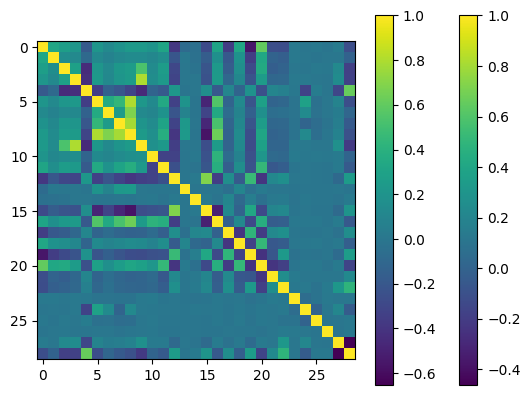

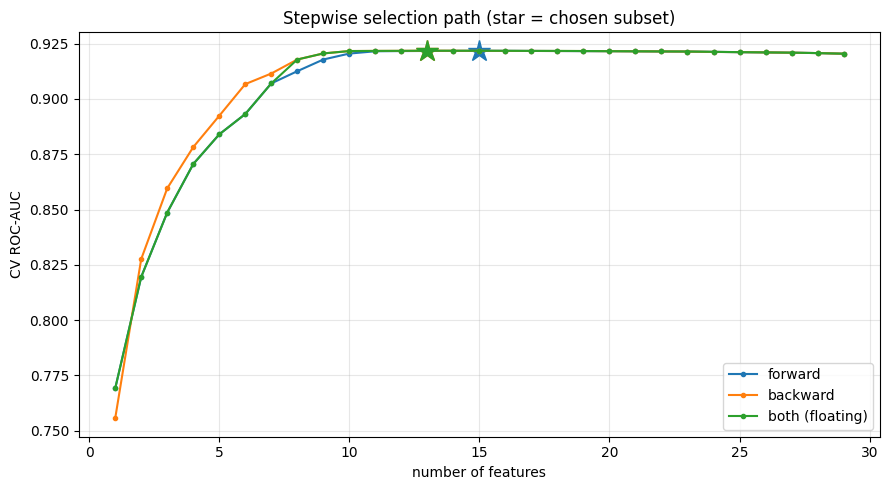

{'forward': SequentialFeatureSelector(estimator=LogisticRegression(max_iter=1000),
                          k_features=(1, 29), n_jobs=-1, scoring='roc_auc'), 'backward': SequentialFeatureSelector(estimator=LogisticRegression(max_iter=1000),
                          forward=False, k_features=(1, 29), n_jobs=-1,
                          scoring='roc_auc'), 'both (floating)': SequentialFeatureSelector(estimator=LogisticRegression(max_iter=1000),
                          floating=True, k_features=(1, 29), n_jobs=-1,
                          scoring='roc_auc')}
                        feature  tree_count  recurrence  importance
0                  CREDIT_SCORE         100         1.0    0.150646
4                ANNUAL_MILEAGE         100         1.0    0.090656
8                INSURANCE_RISK         100         1.0    0.086117
15  DRIVING_EXPERIENCE_Beginner         100         1.0    0.084019
1             VEHICLE_OWNERSHIP         100         1.0    0.076138
5           SPEEDING_VI

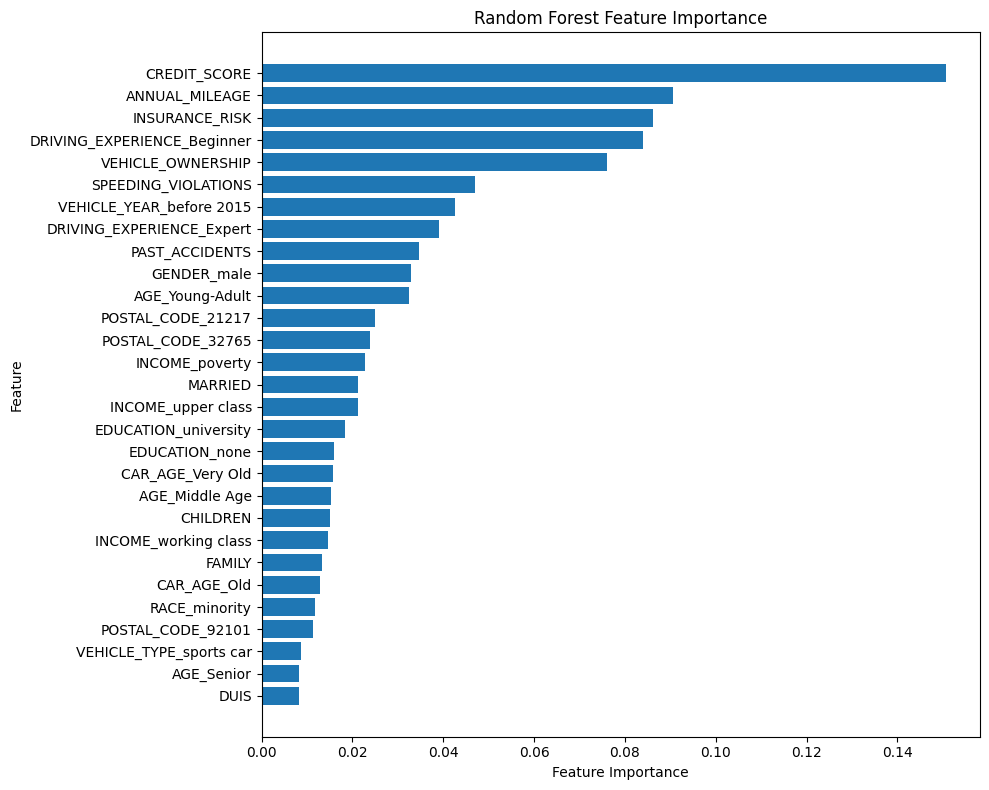

train: (8000, 29) test: (2000, 29) | claim rate train/test: 0.31 0.328
unpruned depth: 32 leaves: 1303


,train accuracy,test accuracy,precision,recall,f1,ROC-AUC
Decision Tree (unpruned),0.9996,0.794,0.6821,0.6966,0.6893,0.7692


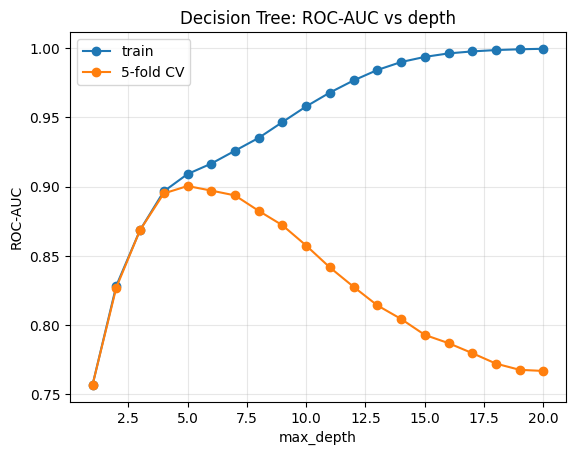

best depth by CV: 5 | CV AUC: 0.9004
best params: {'class_weight': None, 'max_depth': 8, 'min_samples_leaf': 1, 'min_samples_split': 100} | CV AUC: 0.9023 | depth: 8 | leaves: 82


,train accuracy,test accuracy,precision,recall,f1,ROC-AUC
Decision Tree (unpruned),0.9996,0.7940,0.6821,0.6966,0.6893,0.7692
Decision Tree (tuned),0.8596,0.8485,0.7547,0.7973,0.7754,0.9074


,param_class_weight,param_max_depth,param_min_samples_leaf,param_min_samples_split,mean_test_score,std_test_score
123,None,8,1,100,0.9023,0.0082
103,None,7,1,100,0.9020,0.0088
107,None,7,10,100,0.9020,0.0091
247,balanced,7,10,100,0.9019,0.0083
131,None,8,25,100,0.9018,0.0103


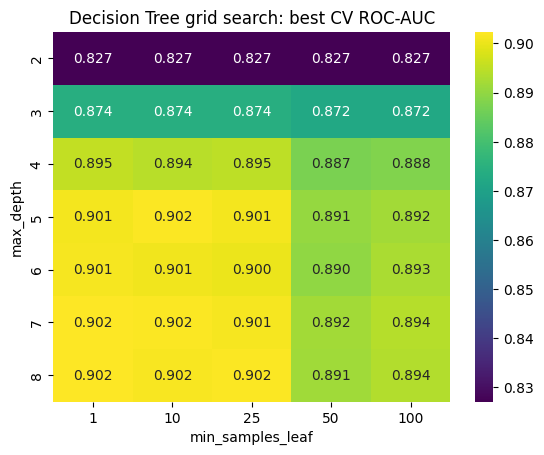

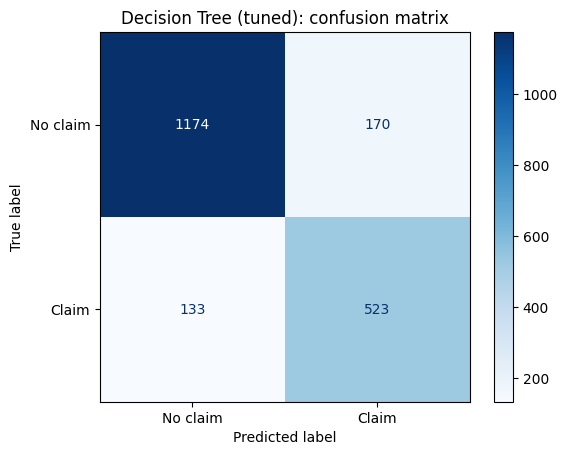

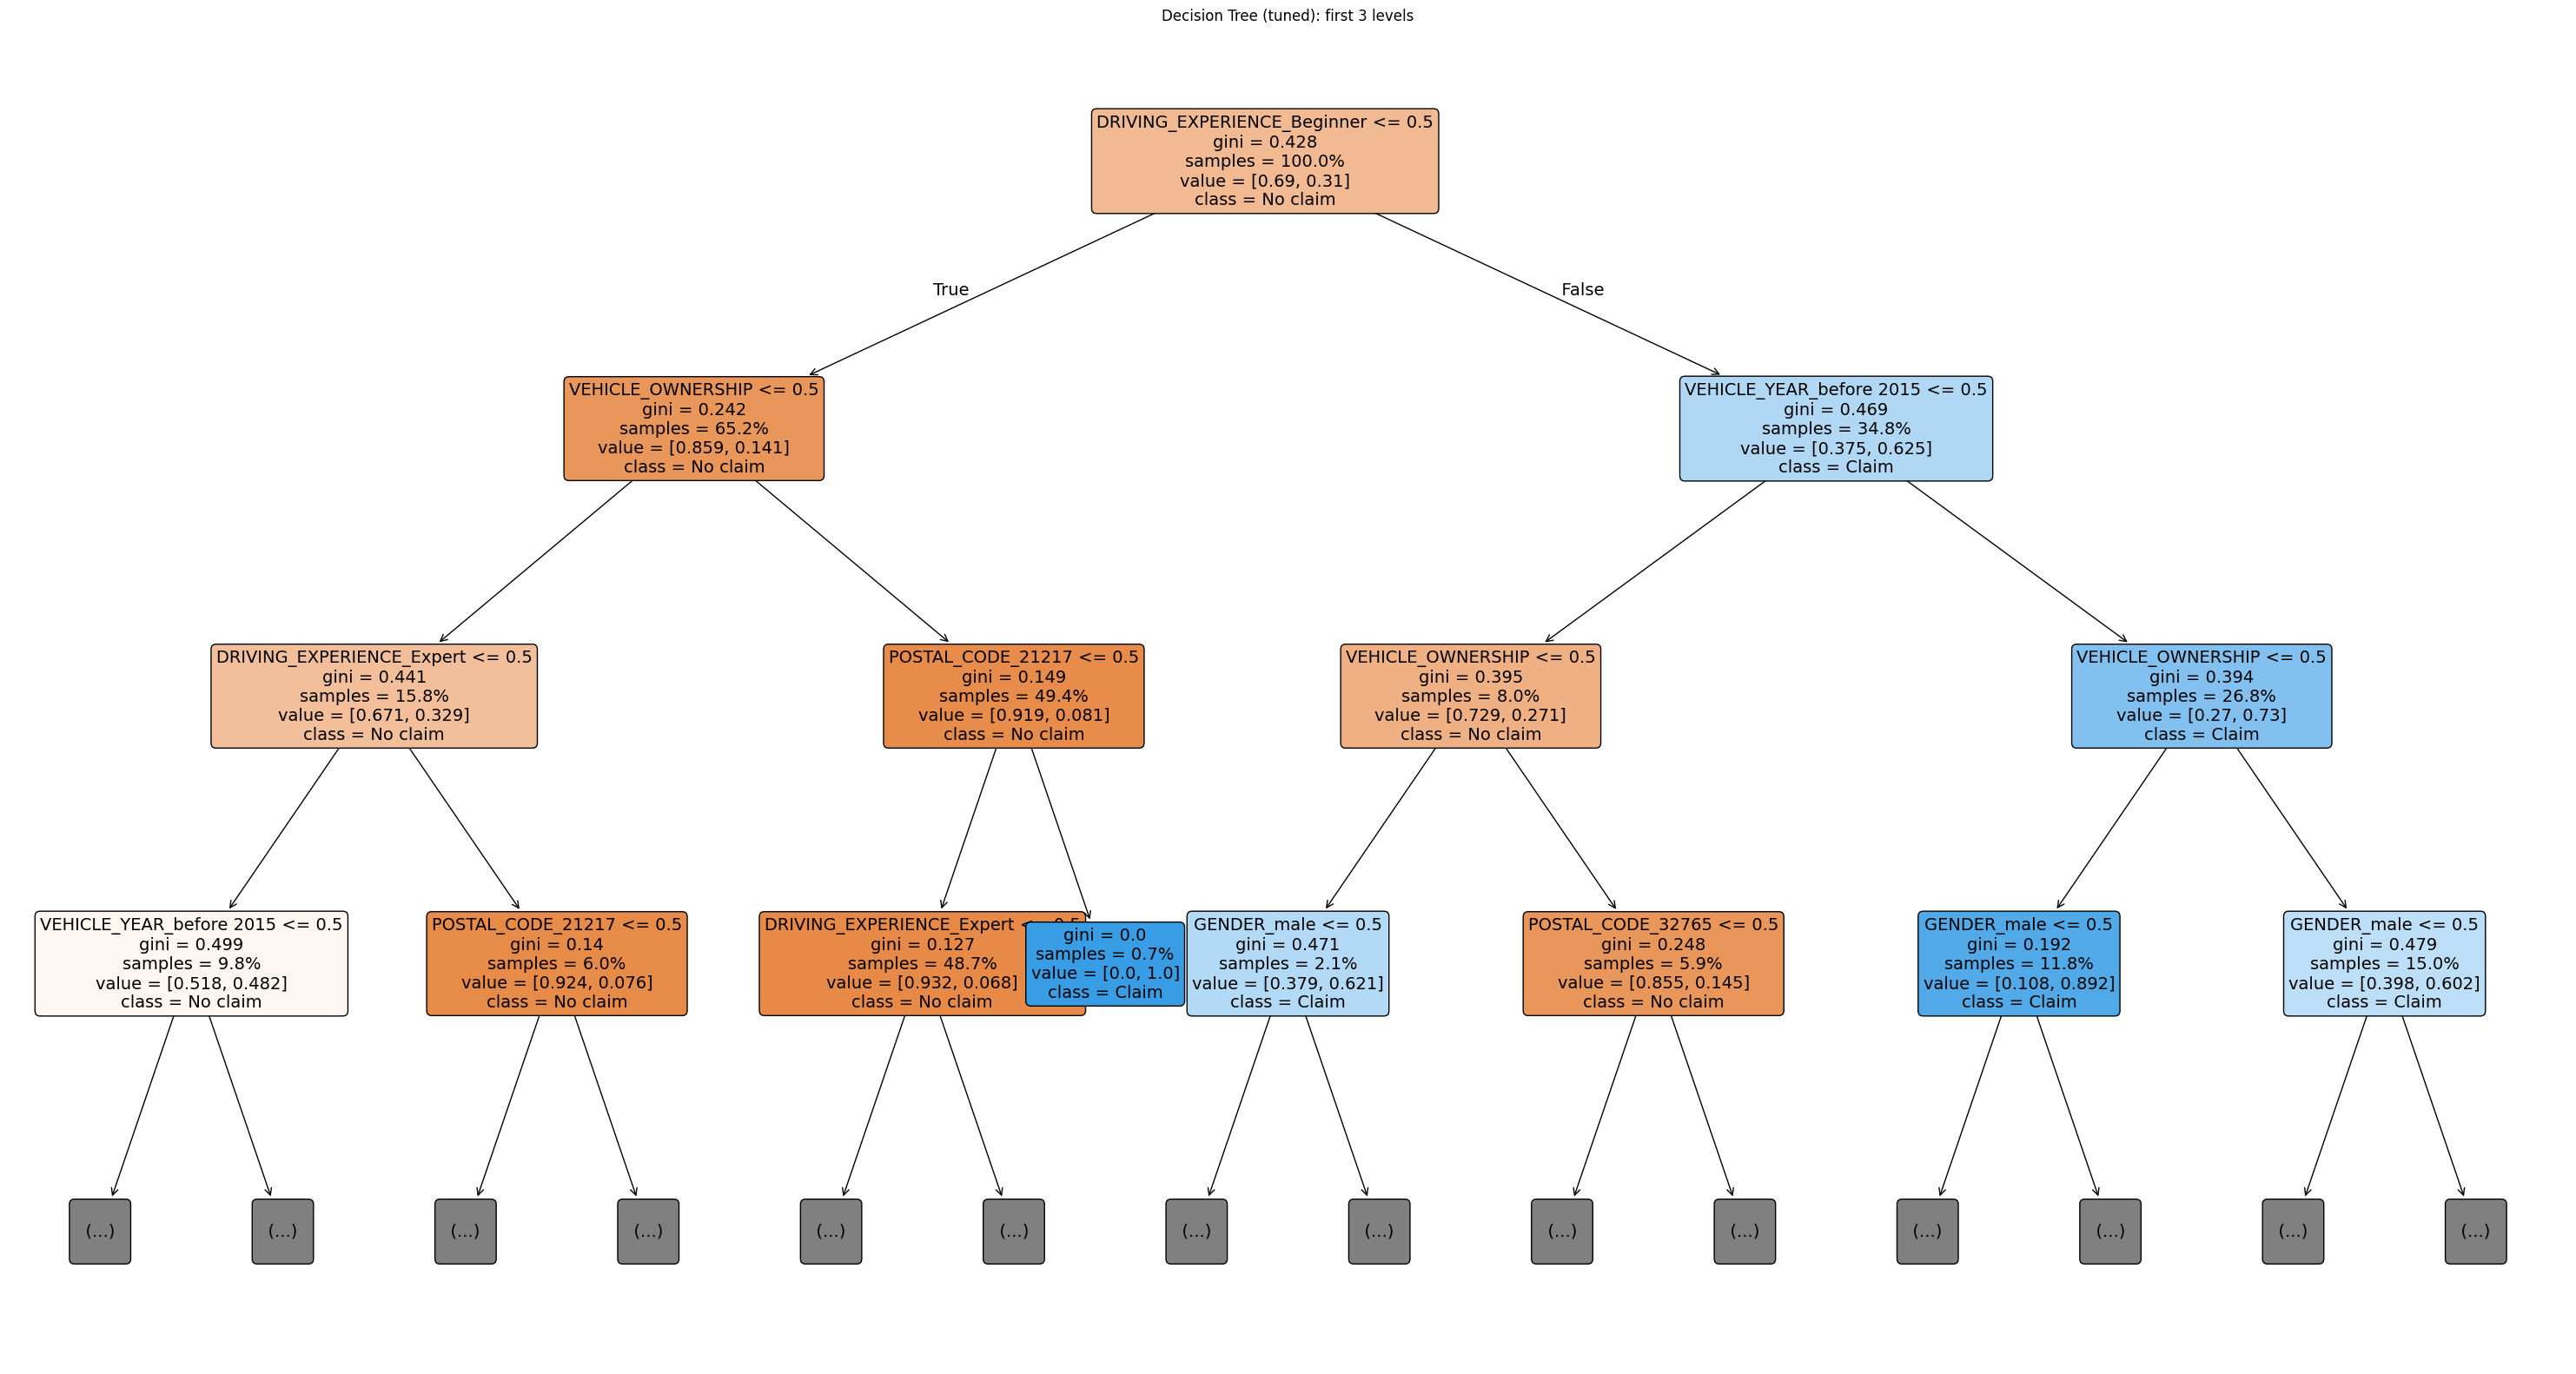

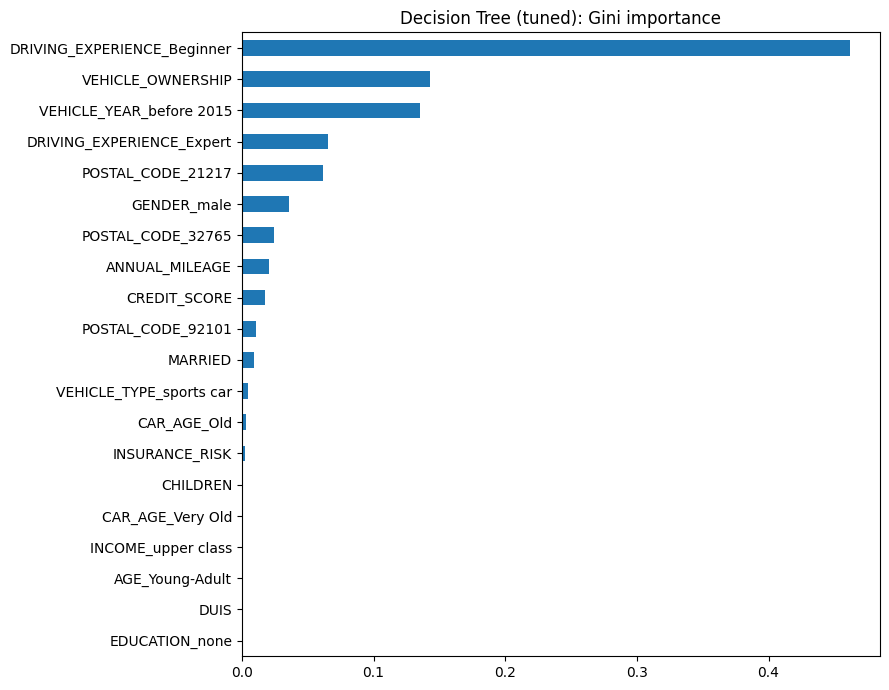

,train accuracy,test accuracy,precision,recall,f1,ROC-AUC
Decision Tree (unpruned),0.9996,0.7940,0.6821,0.6966,0.6893,0.7692
Decision Tree (tuned),0.8596,0.8485,0.7547,0.7973,0.7754,0.9074
Random Forest (default),0.9996,0.8455,0.7858,0.7271,0.7553,0.9114


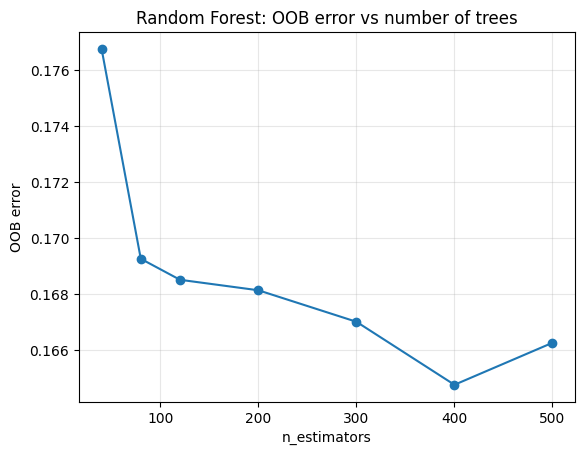

{40: np.float64(0.1767), 80: np.float64(0.1693), 120: np.float64(0.1685), 200: np.float64(0.1681), 300: np.float64(0.167), 400: np.float64(0.1647), 500: np.float64(0.1662)}
best params: {'class_weight': None, 'max_depth': 8, 'max_features': 0.5, 'min_samples_leaf': 1} | CV AUC: 0.916


,train accuracy,test accuracy,precision,recall,f1,ROC-AUC
Decision Tree (unpruned),0.9996,0.7940,0.6821,0.6966,0.6893,0.7692
Decision Tree (tuned),0.8596,0.8485,0.7547,0.7973,0.7754,0.9074
Random Forest (default),0.9996,0.8455,0.7858,0.7271,0.7553,0.9114
Random Forest (tuned),0.8729,0.8545,0.7821,0.7713,0.7767,0.9199


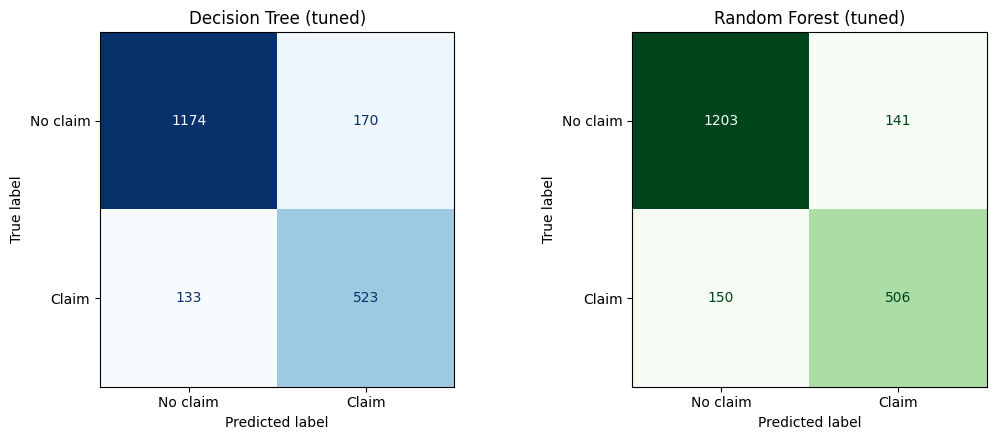

,impurity,permutation,permutation_std
DRIVING_EXPERIENCE_Beginner,0.2491,0.0676,0.0045
VEHICLE_OWNERSHIP,0.1379,0.0499,0.0038
VEHICLE_YEAR_before 2015,0.0955,0.0323,0.0031
DRIVING_EXPERIENCE_Expert,0.0683,0.0262,0.0033
POSTAL_CODE_21217,0.0501,0.0249,0.0018
GENDER_male,0.0350,0.0111,0.0013
POSTAL_CODE_32765,0.0183,0.0110,0.0007
INSURANCE_RISK,0.0918,0.0021,0.0009
POSTAL_CODE_92101,0.0084,0.0018,0.0004
AGE_Young-Adult,0.0628,0.0018,0.0006


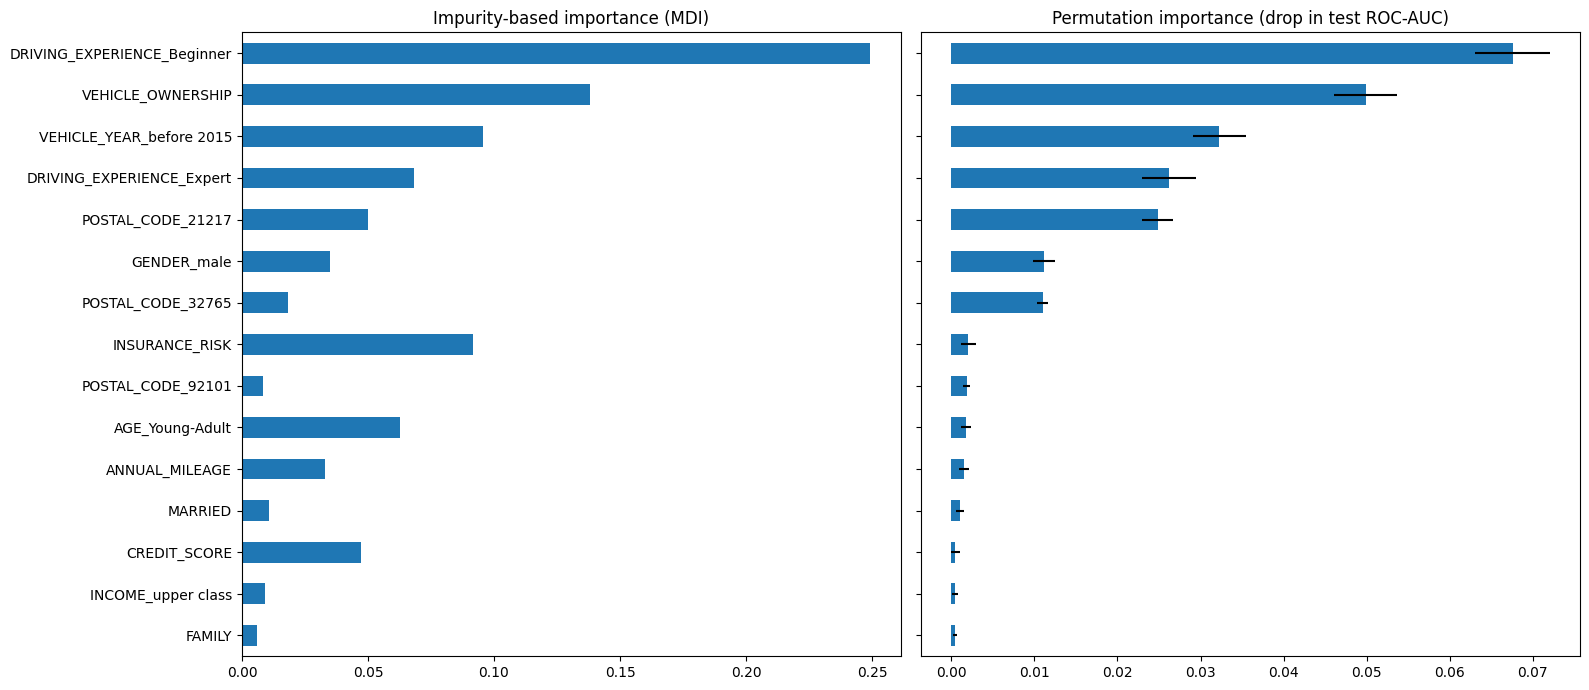

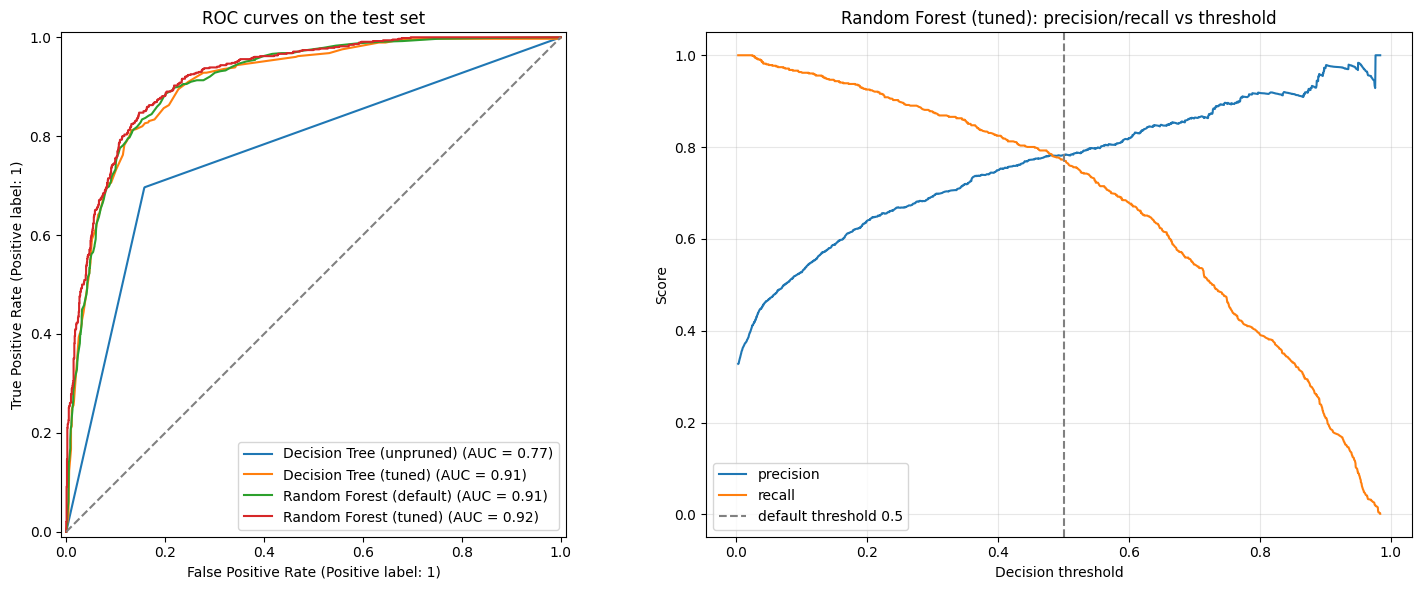

,train accuracy,test accuracy,precision,recall,f1,ROC-AUC
Decision Tree (unpruned),0.9996,0.7940,0.6821,0.6966,0.6893,0.7692
Decision Tree (tuned),0.8596,0.8485,0.7547,0.7973,0.7754,0.9074
Random Forest (default),0.9996,0.8455,0.7858,0.7271,0.7553,0.9114
Random Forest (tuned),0.8729,0.8545,0.7821,0.7713,0.7767,0.9199


train: (8000, 16) test: (2000, 16) | claim rate train/test: 0.31 0.328
unpruned depth: 36 leaves: 1453


,train accuracy,test accuracy,precision,recall,f1,ROC-AUC
Decision Tree (unpruned),0.9979,0.791,0.6766,0.6951,0.6857,0.7683


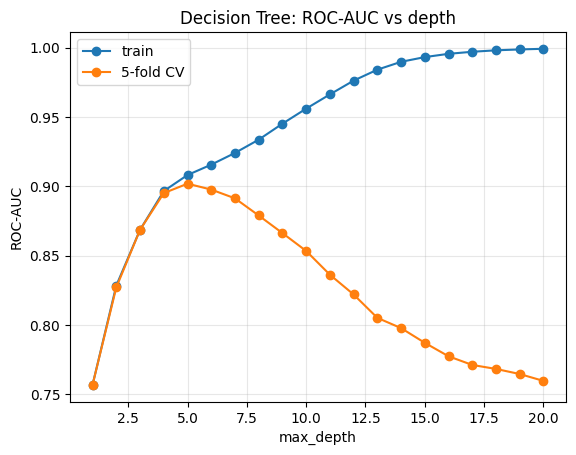

best depth by CV: 5 | CV AUC: 0.9019
best params: {'class_weight': None, 'max_depth': 5, 'min_samples_leaf': 10, 'min_samples_split': 50} | CV AUC: 0.9024 | depth: 5 | leaves: 29


,train accuracy,test accuracy,precision,recall,f1,ROC-AUC
Decision Tree (unpruned),0.9979,0.7910,0.6766,0.6951,0.6857,0.7683
Decision Tree (tuned),0.8484,0.8395,0.7638,0.7393,0.7514,0.9051


,param_class_weight,param_max_depth,param_min_samples_leaf,param_min_samples_split,mean_test_score,std_test_score
66,None,5,10,50,0.9024,0.0060
62,None,5,1,50,0.9021,0.0068
65,None,5,10,20,0.9020,0.0060
64,None,5,10,2,0.9020,0.0060
107,None,7,10,100,0.9020,0.0105


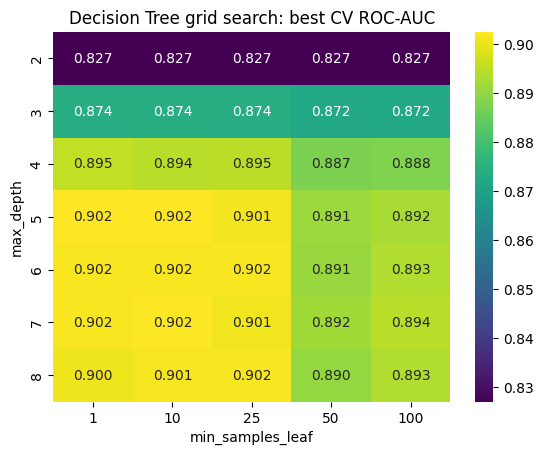

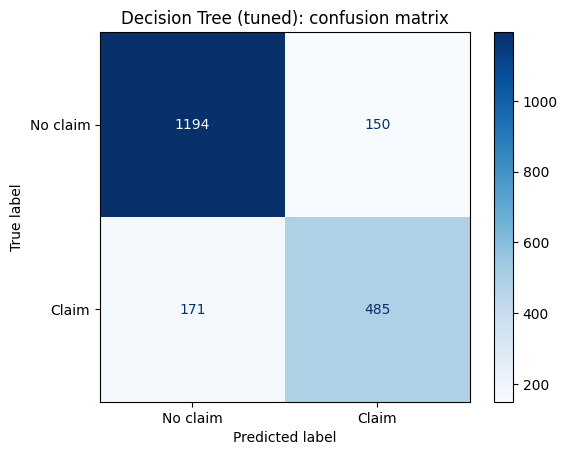

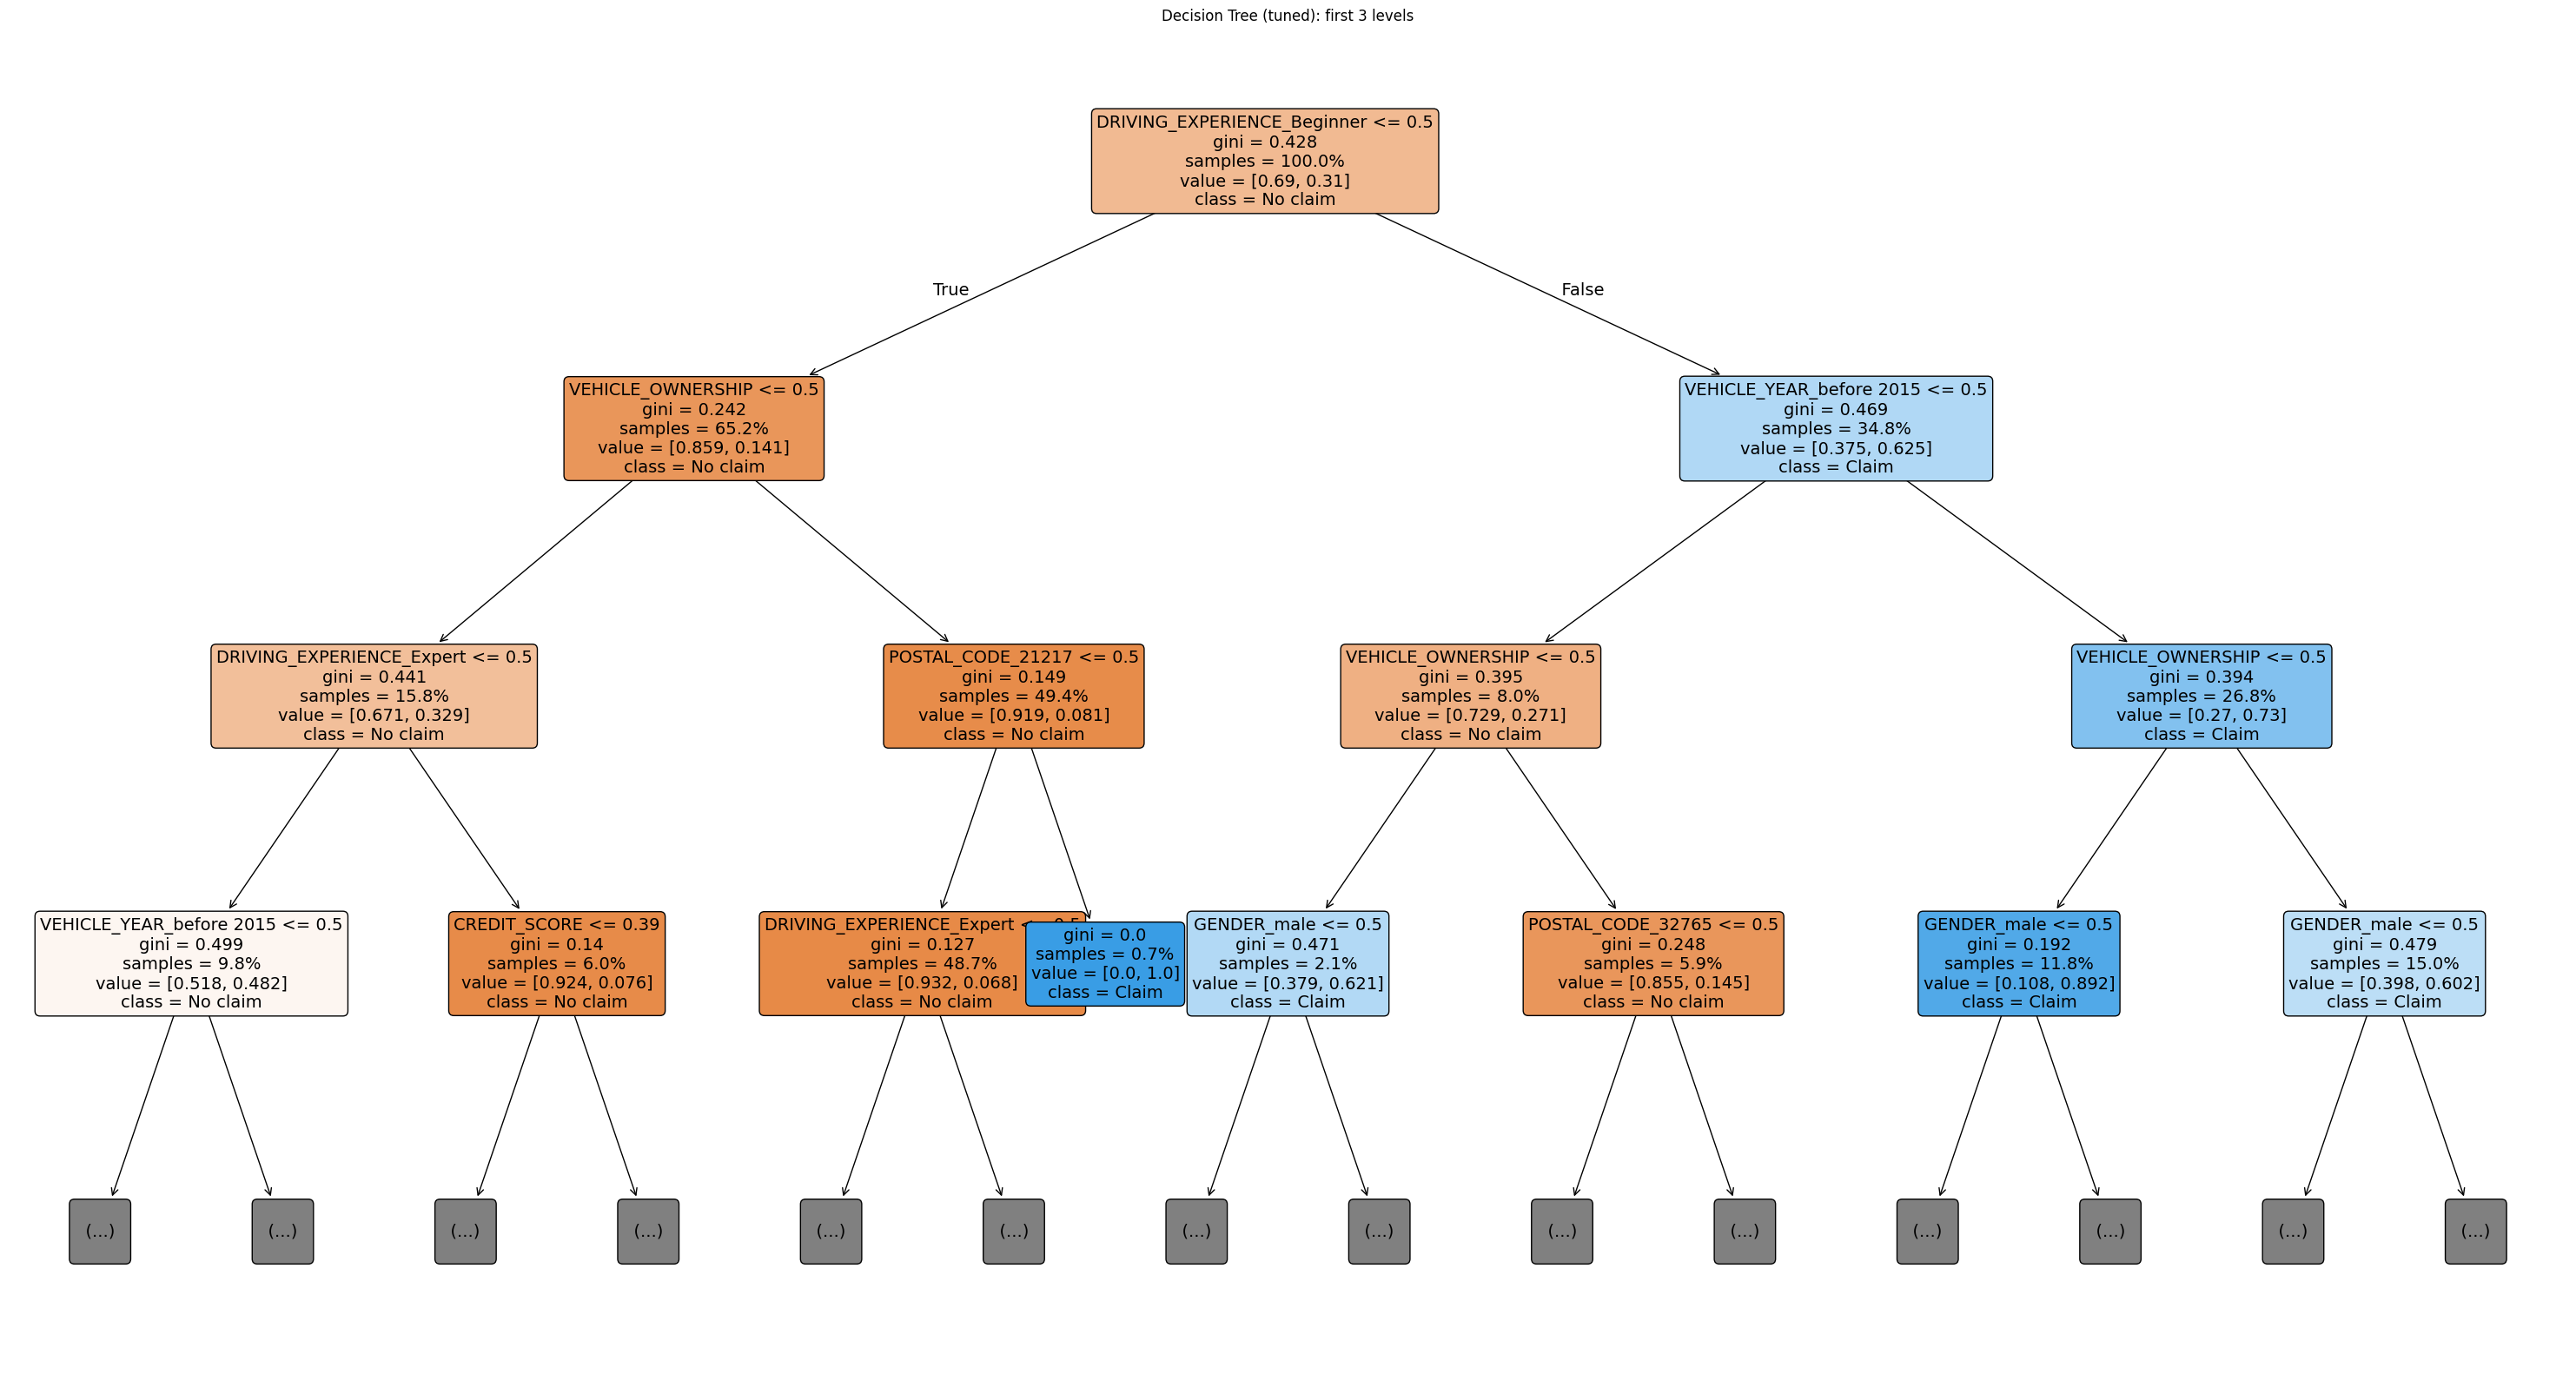

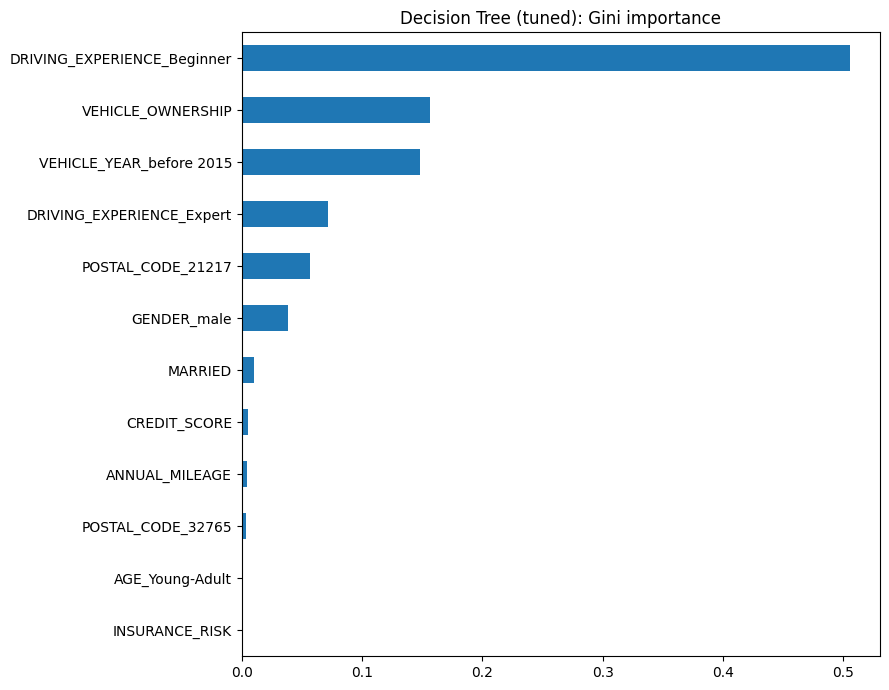

,train accuracy,test accuracy,precision,recall,f1,ROC-AUC
Decision Tree (unpruned),0.9979,0.7910,0.6766,0.6951,0.6857,0.7683
Decision Tree (tuned),0.8484,0.8395,0.7638,0.7393,0.7514,0.9051
Random Forest (default),0.9979,0.8335,0.7661,0.7088,0.7363,0.9035


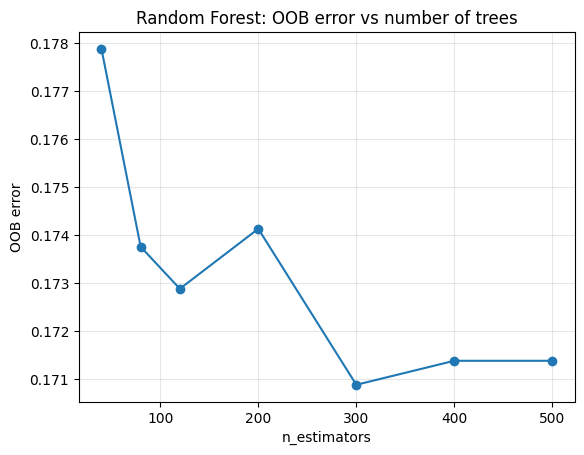

{40: np.float64(0.1779), 80: np.float64(0.1737), 120: np.float64(0.1729), 200: np.float64(0.1741), 300: np.float64(0.1709), 400: np.float64(0.1714), 500: np.float64(0.1714)}
best params: {'class_weight': None, 'max_depth': 8, 'max_features': 0.5, 'min_samples_leaf': 1} | CV AUC: 0.9139


,train accuracy,test accuracy,precision,recall,f1,ROC-AUC
Decision Tree (unpruned),0.9979,0.7910,0.6766,0.6951,0.6857,0.7683
Decision Tree (tuned),0.8484,0.8395,0.7638,0.7393,0.7514,0.9051
Random Forest (default),0.9979,0.8335,0.7661,0.7088,0.7363,0.9035
Random Forest (tuned),0.8706,0.8555,0.7836,0.7729,0.7782,0.9176


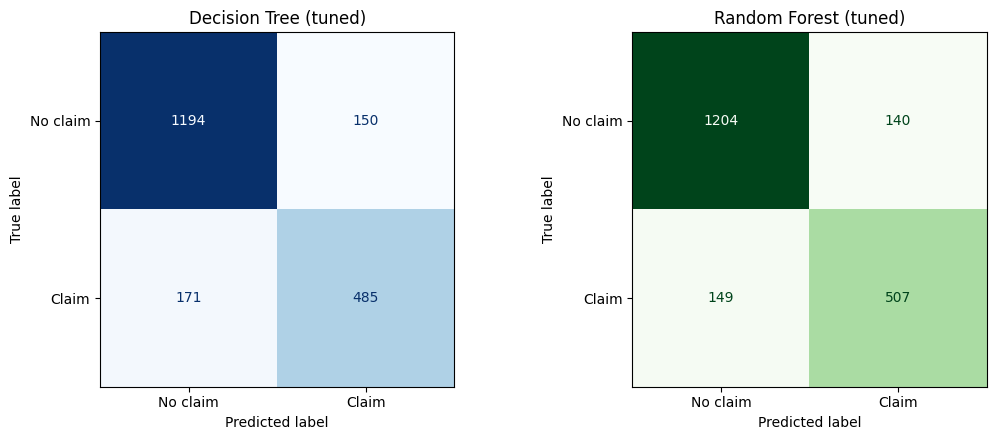

,impurity,permutation,permutation_std
DRIVING_EXPERIENCE_Beginner,0.2614,0.0696,0.0045
VEHICLE_OWNERSHIP,0.1396,0.0501,0.0036
VEHICLE_YEAR_before 2015,0.1045,0.0402,0.0040
DRIVING_EXPERIENCE_Expert,0.0676,0.0294,0.0031
POSTAL_CODE_21217,0.0521,0.0239,0.0020
GENDER_male,0.0375,0.0130,0.0014
POSTAL_CODE_32765,0.0195,0.0103,0.0009
ANNUAL_MILEAGE,0.0416,0.0040,0.0008
INSURANCE_RISK,0.1037,0.0039,0.0009
MARRIED,0.0145,0.0019,0.0006


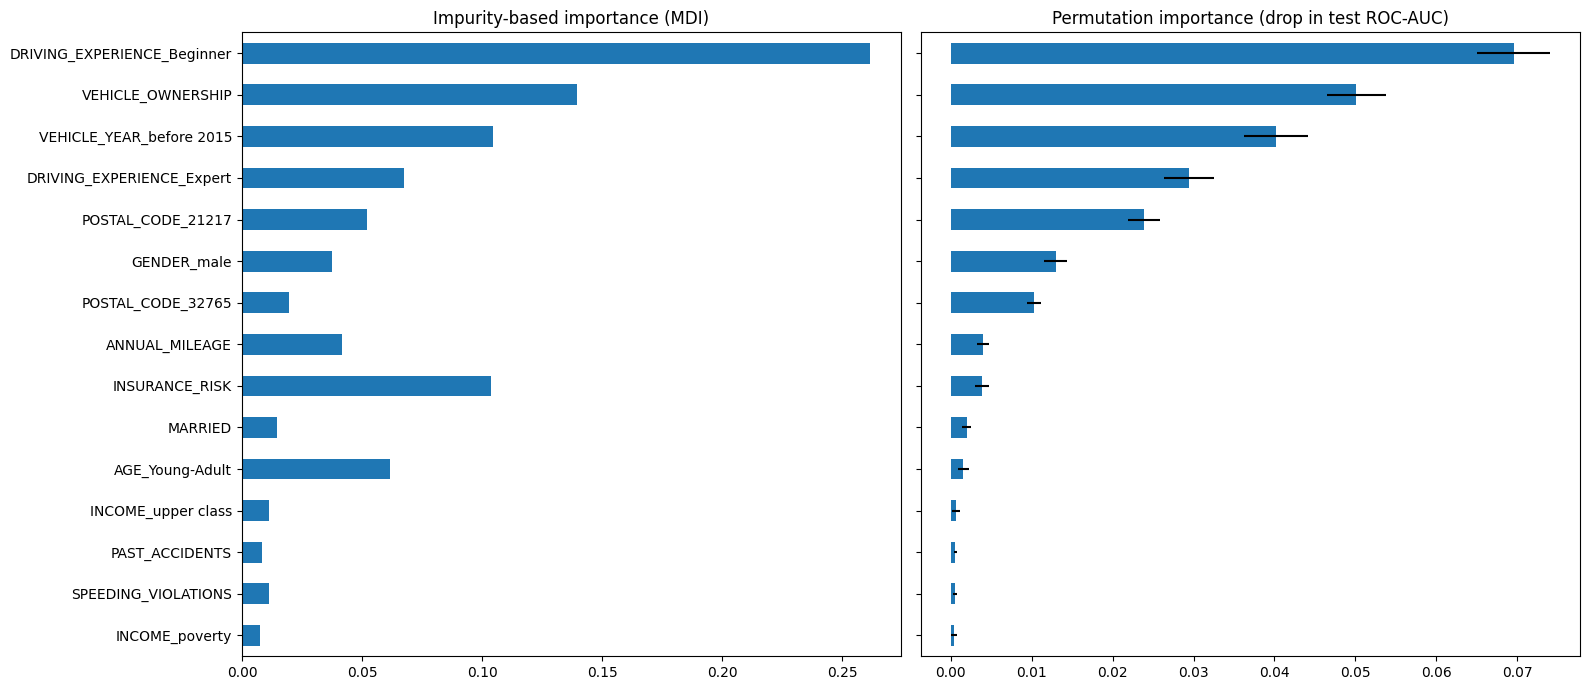

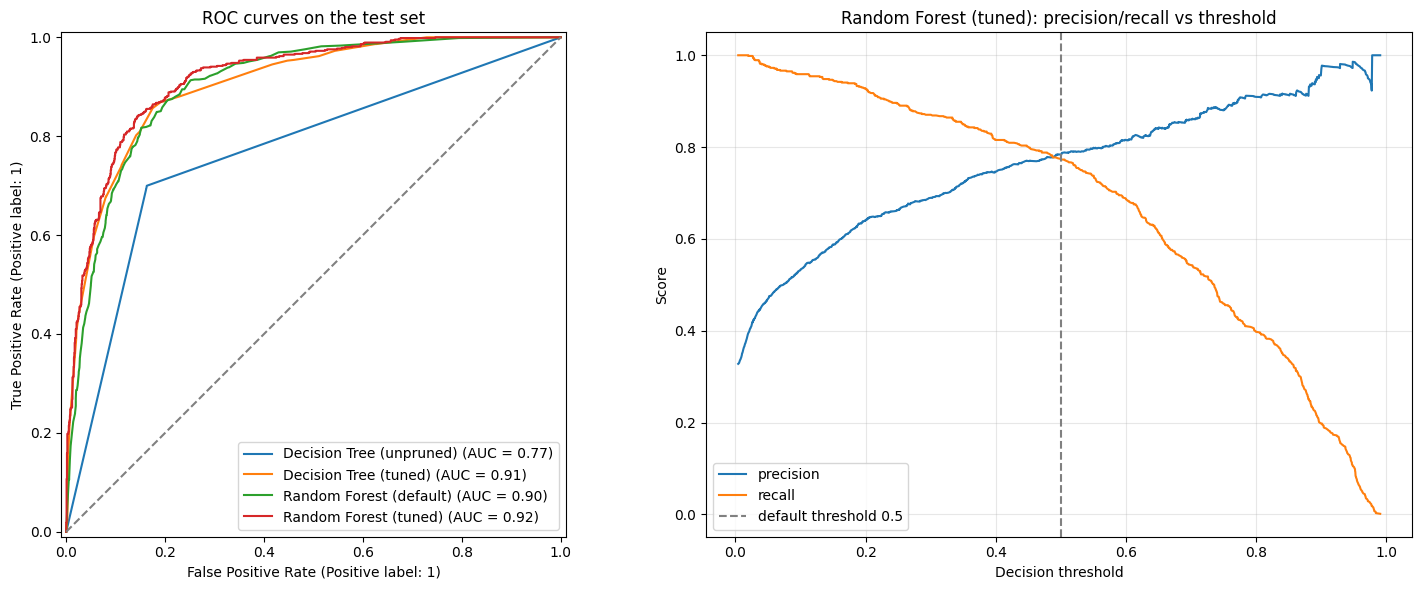

,train accuracy,test accuracy,precision,recall,f1,ROC-AUC
Decision Tree (unpruned),0.9979,0.7910,0.6766,0.6951,0.6857,0.7683
Decision Tree (tuned),0.8484,0.8395,0.7638,0.7393,0.7514,0.9051
Random Forest (default),0.9979,0.8335,0.7661,0.7088,0.7363,0.9035
Random Forest (tuned),0.8706,0.8555,0.7836,0.7729,0.7782,0.9176


train: (8000, 15) test: (2000, 15) | claim rate train/test: 0.31 0.328
unpruned depth: 26 leaves: 1253


,train accuracy,test accuracy,precision,recall,f1,ROC-AUC
Decision Tree (unpruned),0.9265,0.8175,0.7201,0.7256,0.7229,0.8266


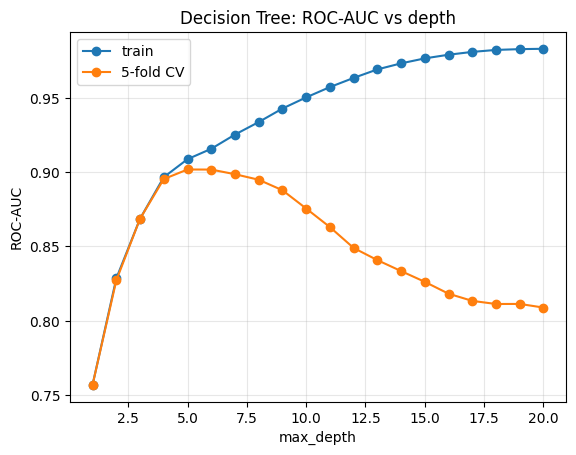

best depth by CV: 5 | CV AUC: 0.9017
best params: {'class_weight': None, 'max_depth': 8, 'min_samples_leaf': 25, 'min_samples_split': 100} | CV AUC: 0.9089 | depth: 8 | leaves: 82


,train accuracy,test accuracy,precision,recall,f1,ROC-AUC
Decision Tree (unpruned),0.9265,0.8175,0.7201,0.7256,0.7229,0.8266
Decision Tree (tuned),0.8540,0.8460,0.7693,0.7576,0.7634,0.9110


,param_class_weight,param_max_depth,param_min_samples_leaf,param_min_samples_split,mean_test_score,std_test_score
131,None,8,25,100,0.9089,0.0059
267,balanced,8,10,100,0.9088,0.0054
127,None,8,10,100,0.9085,0.0047
128,None,8,25,2,0.9075,0.0044
130,None,8,25,50,0.9075,0.0044


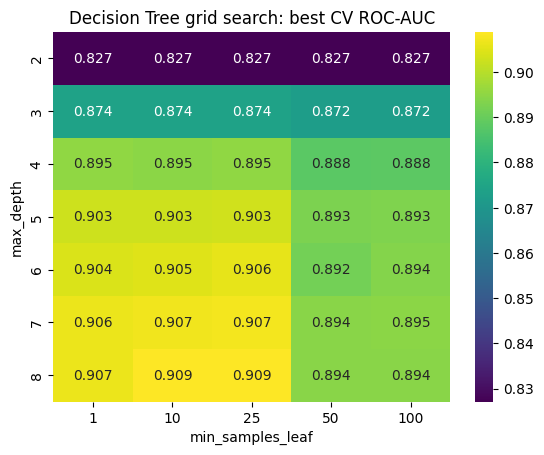

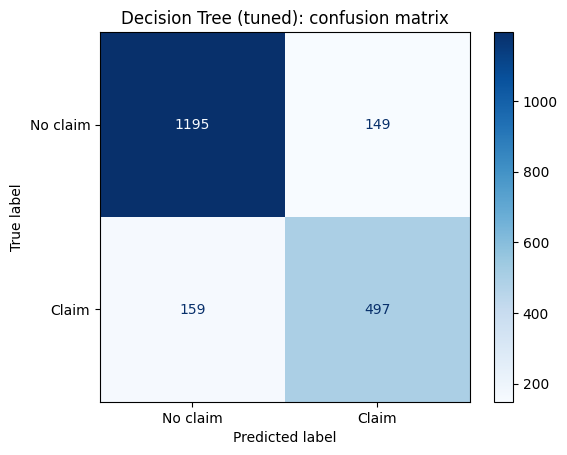

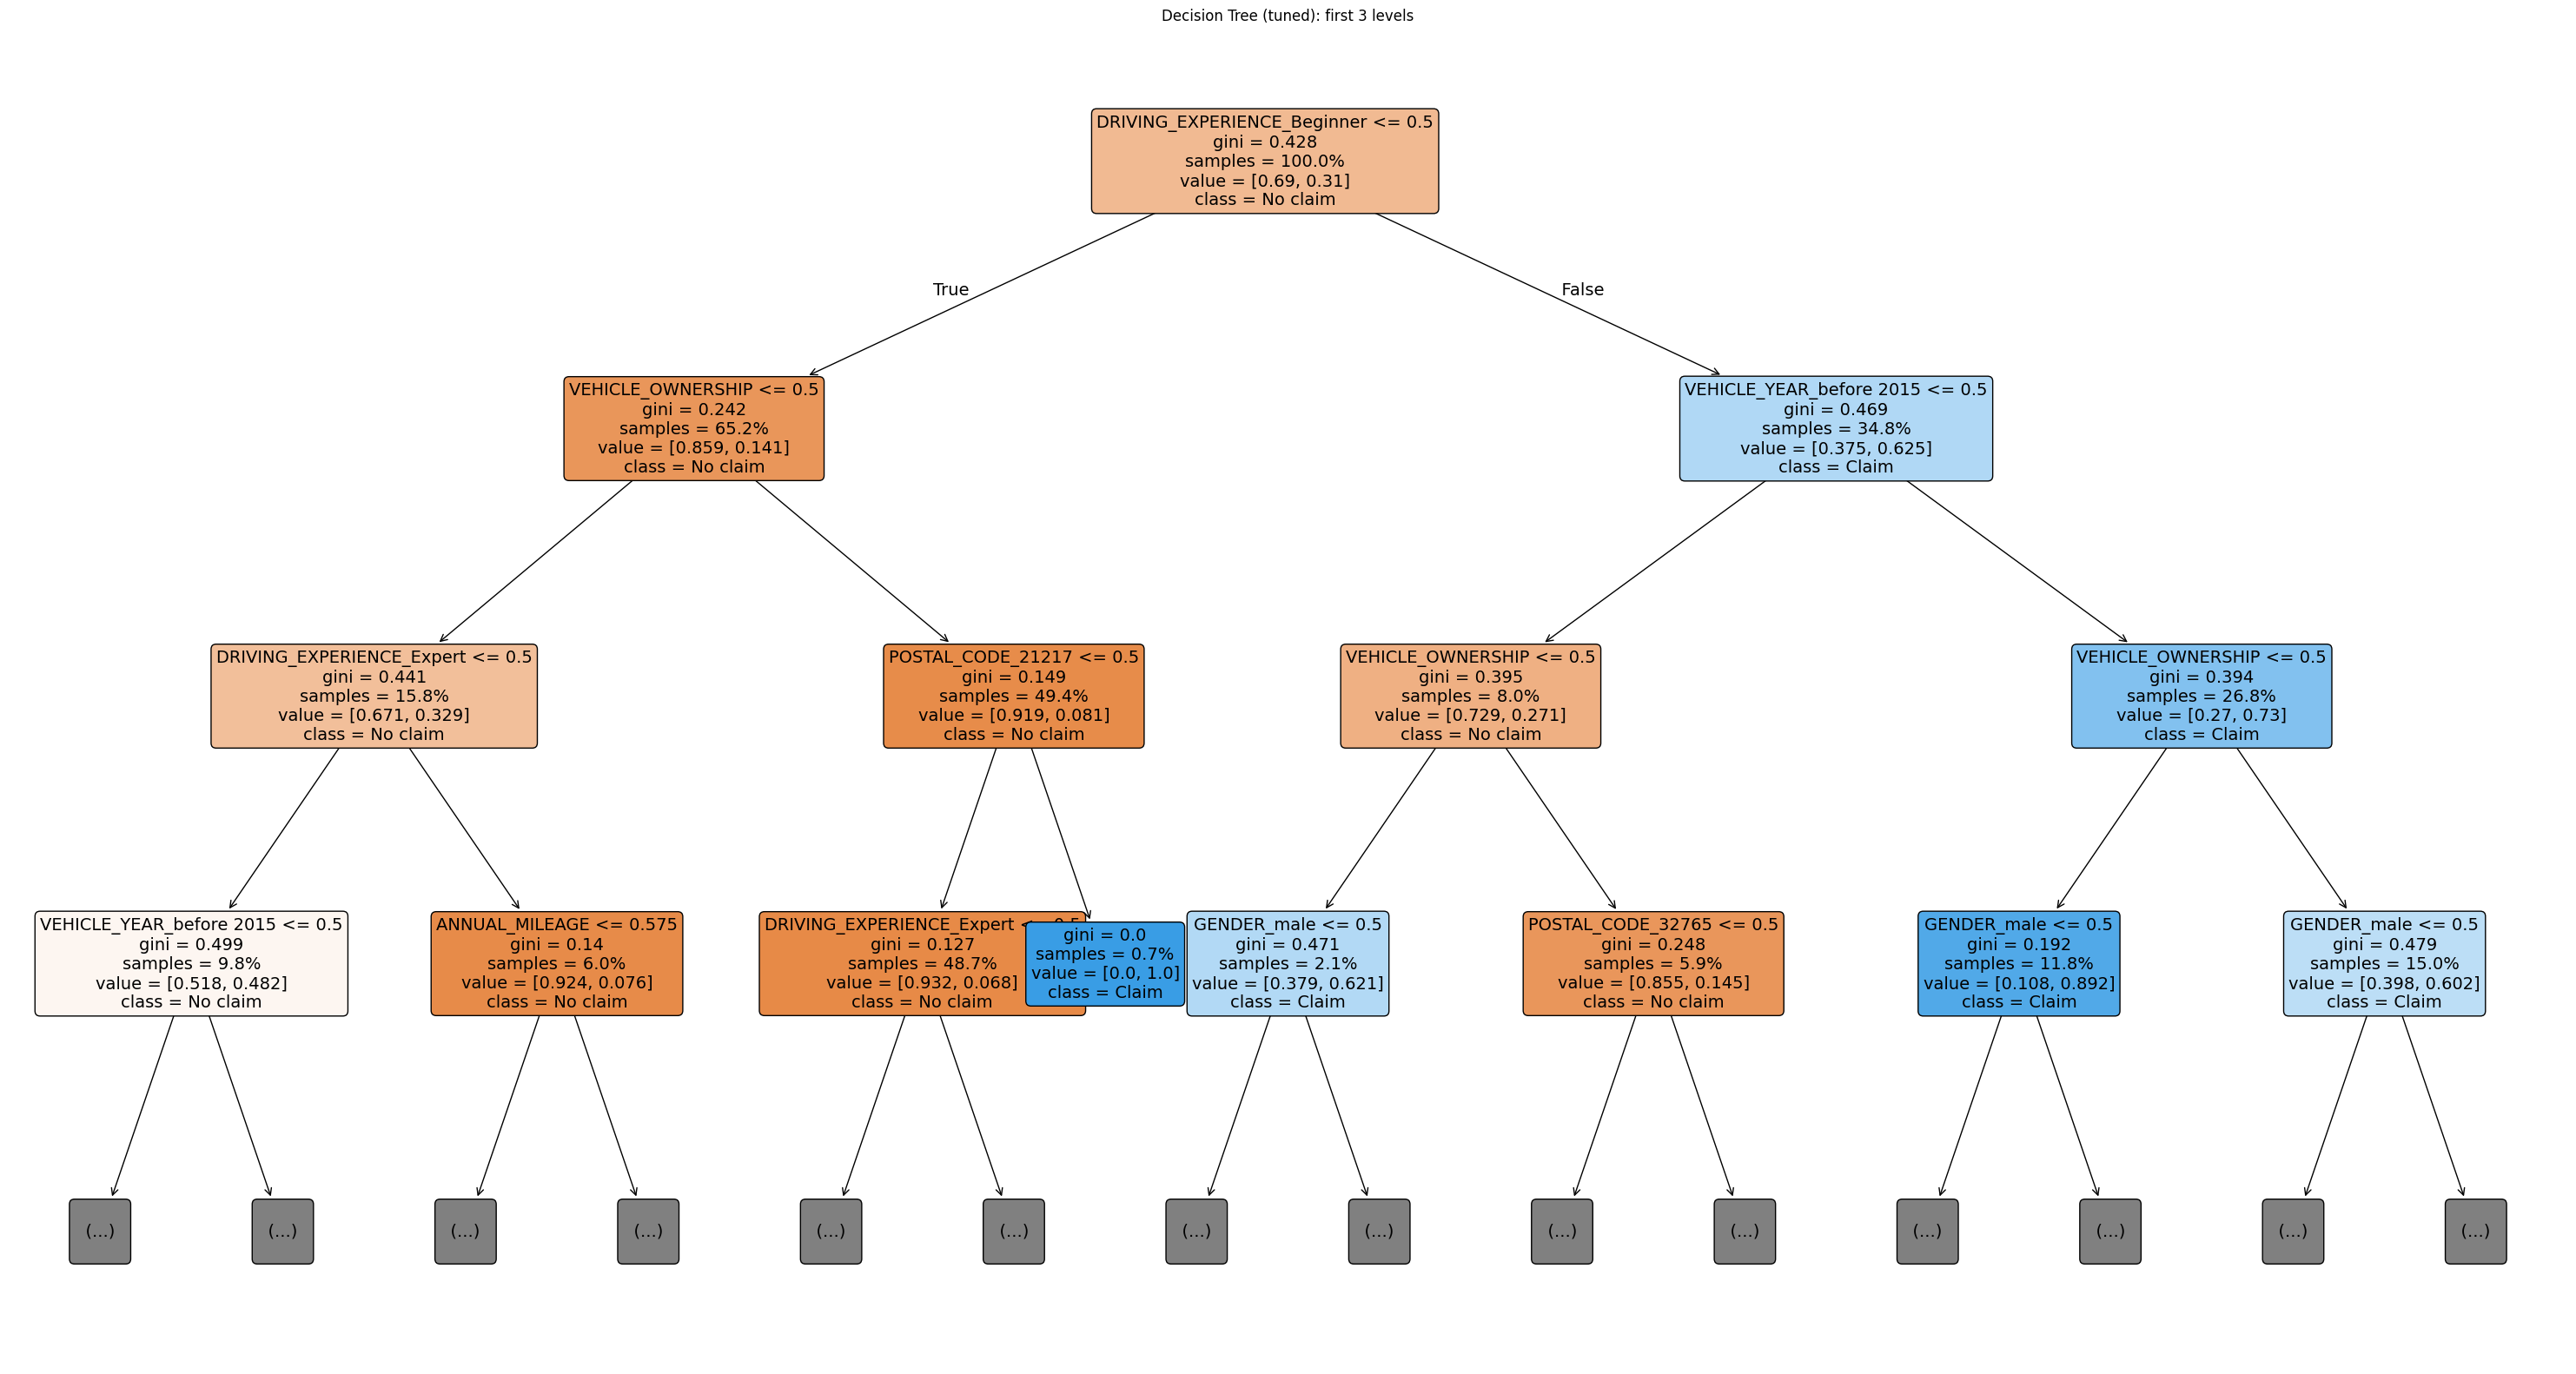

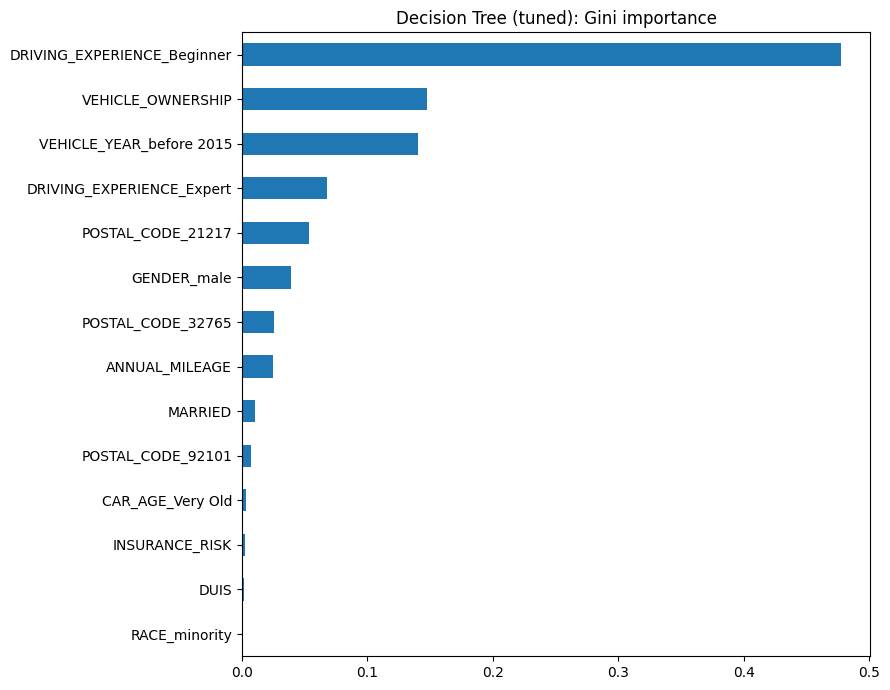

,train accuracy,test accuracy,precision,recall,f1,ROC-AUC
Decision Tree (unpruned),0.9265,0.8175,0.7201,0.7256,0.7229,0.8266
Decision Tree (tuned),0.8540,0.8460,0.7693,0.7576,0.7634,0.9110
Random Forest (default),0.9265,0.8345,0.7543,0.7348,0.7444,0.9010


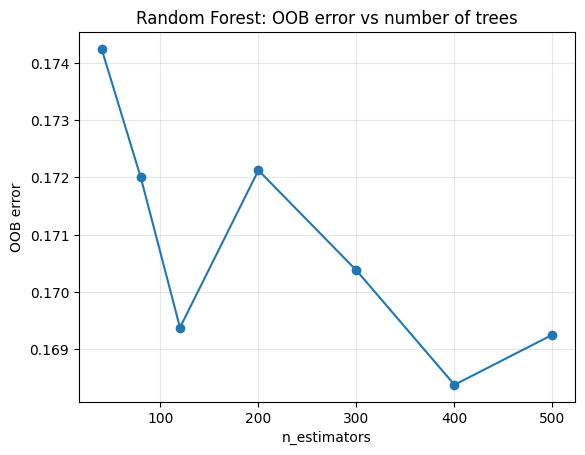

{40: np.float64(0.1743), 80: np.float64(0.172), 120: np.float64(0.1694), 200: np.float64(0.1721), 300: np.float64(0.1704), 400: np.float64(0.1684), 500: np.float64(0.1693)}
best params: {'class_weight': None, 'max_depth': 8, 'max_features': 0.5, 'min_samples_leaf': 1} | CV AUC: 0.9173


,train accuracy,test accuracy,precision,recall,f1,ROC-AUC
Decision Tree (unpruned),0.9265,0.8175,0.7201,0.7256,0.7229,0.8266
Decision Tree (tuned),0.8540,0.8460,0.7693,0.7576,0.7634,0.9110
Random Forest (default),0.9265,0.8345,0.7543,0.7348,0.7444,0.9010
Random Forest (tuned),0.8656,0.8575,0.7876,0.7744,0.7809,0.9198


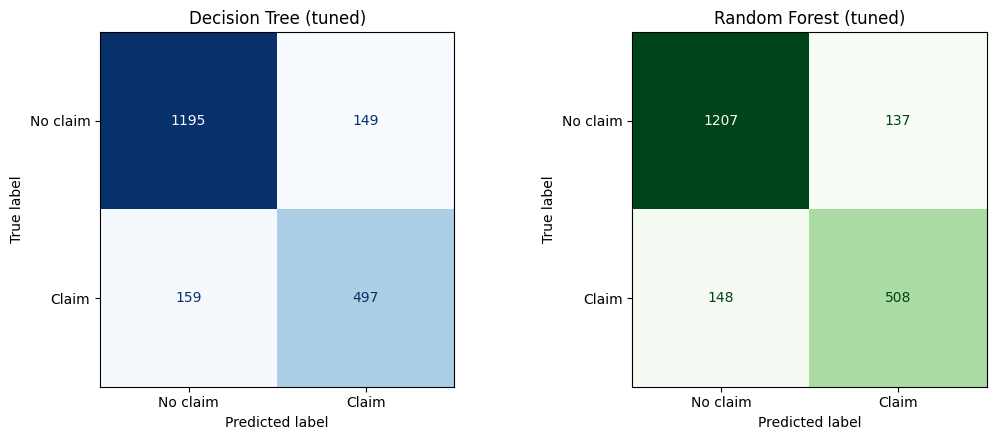

,impurity,permutation,permutation_std
DRIVING_EXPERIENCE_Beginner,0.2747,0.0803,0.0056
VEHICLE_OWNERSHIP,0.1580,0.0527,0.0042
VEHICLE_YEAR_before 2015,0.1072,0.0356,0.0037
DRIVING_EXPERIENCE_Expert,0.0926,0.0301,0.0029
POSTAL_CODE_21217,0.0543,0.0252,0.0019
POSTAL_CODE_32765,0.0233,0.0136,0.0007
GENDER_male,0.0409,0.0128,0.0015
ANNUAL_MILEAGE,0.0473,0.0033,0.0010
MARRIED,0.0202,0.0025,0.0008
INSURANCE_RISK,0.1225,0.0024,0.0011


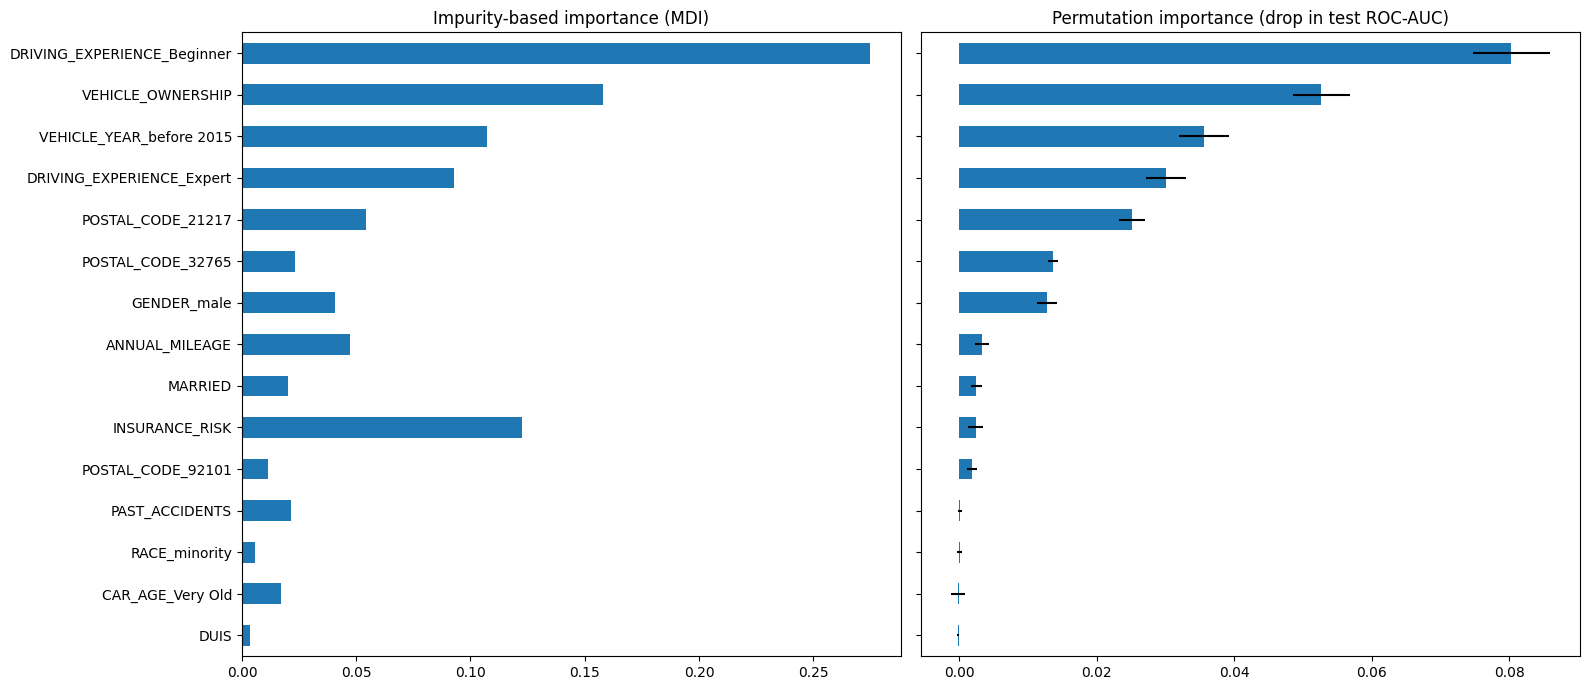

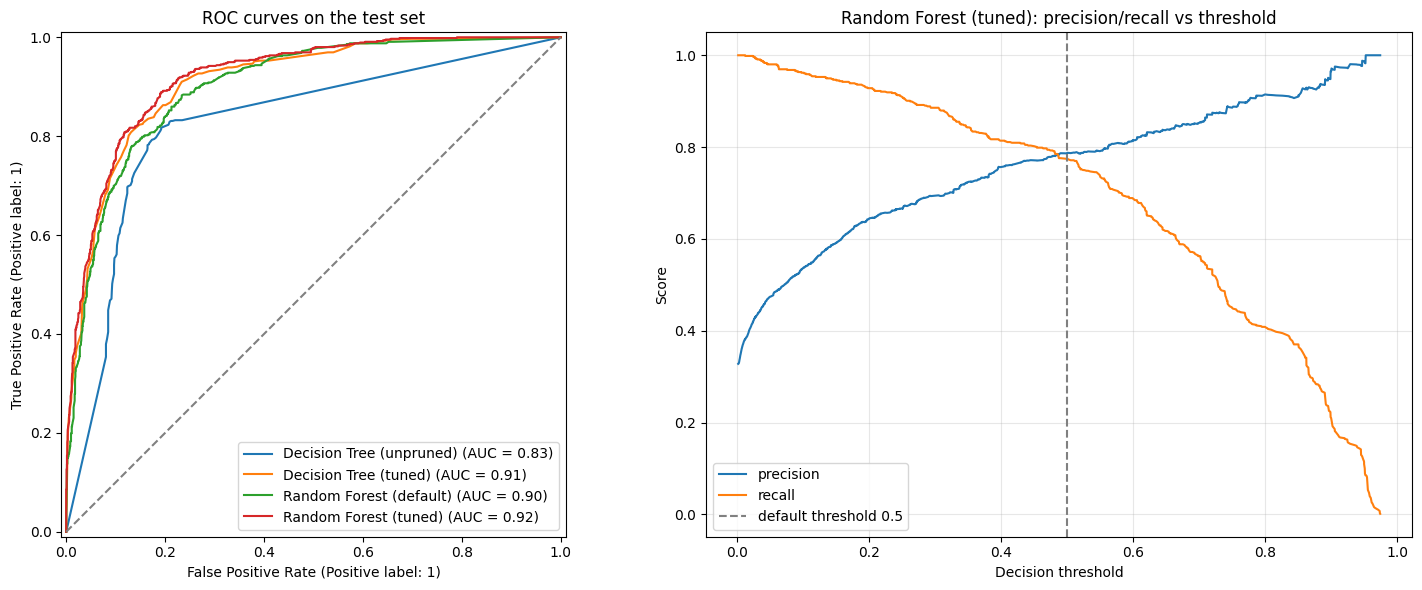

,train accuracy,test accuracy,precision,recall,f1,ROC-AUC
Decision Tree (unpruned),0.9265,0.8175,0.7201,0.7256,0.7229,0.8266
Decision Tree (tuned),0.8540,0.8460,0.7693,0.7576,0.7634,0.9110
Random Forest (default),0.9265,0.8345,0.7543,0.7348,0.7444,0.9010
Random Forest (tuned),0.8656,0.8575,0.7876,0.7744,0.7809,0.9198


In [67]:
url = "https://raw.githubusercontent.com/brian-chin22/cse4_587_project/refs/heads/main/Car_Insurance_Claim.csv"
data = pd.read_csv(url)
outcome = data["OUTCOME"]
data = data.drop(columns=["OUTCOME"])
SEED = 123

X_train, X_test, y_train, y_test = train_test_split(
    data,
    outcome,
    test_size=0.2,
    random_state=SEED
)

train_set, test_set, y_train, y_test, rf_train_set, rf_test_set, lr_train_set, lr_test_set = pre_process(
  X_train, X_test, y_train, y_test
)
tree_models, tree_table = run_tree_models(train_set, y_train, test_set, y_test)
display(tree_table.round(4))

tree_models_rf, tree_table_rf = run_tree_models(rf_train_set, y_train, rf_test_set, y_test)
display(tree_table_rf.round(4))

tree_models_lr, tree_table_lr = run_tree_models(lr_train_set, y_train, lr_test_set, y_test)
display(tree_table_lr.round(4))

# All three feature sets are split with the same labels, seed and stratification,
# so they get the same validation rows
y_train_full = y_train

train_set, val_set, y_train, y_val = train_test_split(
    train_set,
    y_train_full,
    test_size=0.2,
    random_state=SEED,
    stratify=y_train_full
)

rf_train_set, rf_val_set, rf_y_train, rf_y_val = train_test_split(
    rf_train_set,
    y_train_full,
    test_size=0.2,
    random_state=SEED,
    stratify=y_train_full
)

lr_train_set, lr_val_set, y_train, y_val = train_test_split(
    lr_train_set,
    y_train_full,
    test_size=0.2,
    random_state=SEED,
    stratify=y_train_full
)

assert train_set.index.equals(rf_train_set.index) and train_set.index.equals(lr_train_set.index)

### KNN

K value with best accuracy: 17


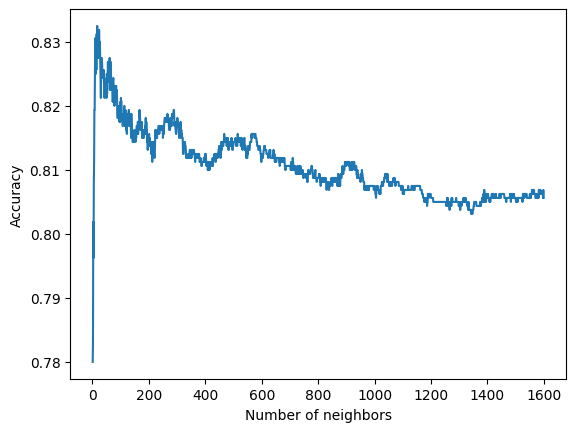

Test Accuracy for K-NN with best k: 17
Accuracy: 0.8395 
 Precision: 0.7873070325900514 
 Recall: 0.6996951219512195 
 F1-score: 0.7409200968523002 
 ROC-AUC: 0.8037166085946573
Accuracy: 0.8395
Redundant examples removed
Samples removed: 3234
K value with best accuracy: 17


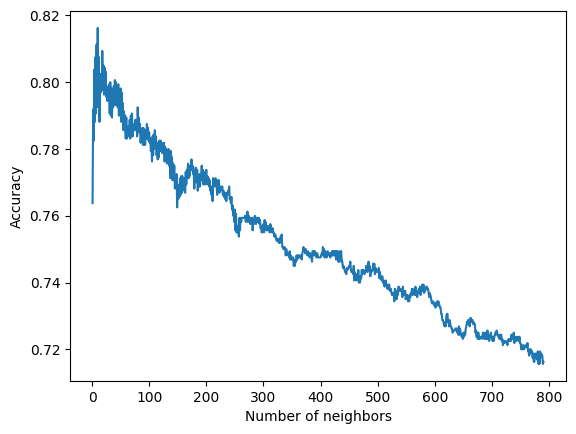

Test Accuracy for K-NN with best k: 17
Accuracy: 0.808 
 Precision: 0.6566820276497696 
 Recall: 0.8689024390243902 
 F1-score: 0.7480314960629921 
 ROC-AUC: 0.8235881242740999
Accuracy: 0.808


In [73]:
KNN_models(
    X_train=train_set,
    y_train=y_train,
    X_val=val_set,
    y_val=y_val,
    X_test=test_set,
    y_test=y_test,
    weighted=False
)

K value with best accuracy: 27


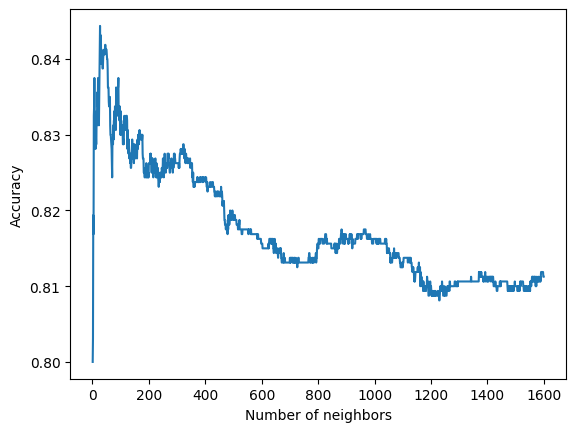

Test Accuracy for K-NN with best k: 27
Accuracy: 0.837 
 Precision: 0.7570093457943925 
 Recall: 0.7408536585365854 
 F1-score: 0.74884437596302 
 ROC-AUC: 0.8123911149825783
Accuracy: 0.837
Redundant examples removed
Samples removed: 3340
K value with best accuracy: 27


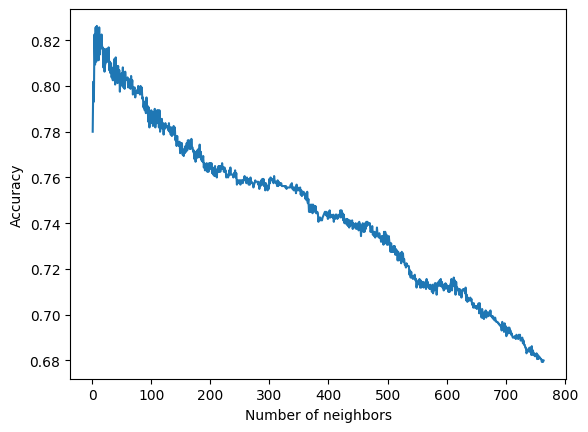

Test Accuracy for K-NN with best k: 27
Accuracy: 0.8115 
 Precision: 0.6654804270462633 
 Recall: 0.8551829268292683 
 F1-score: 0.7484989993328885 
 ROC-AUC: 0.8226807491289199
Accuracy: 0.8115


In [80]:
KNN_models(
    X_train=rf_train_set,
    y_train=rf_y_train,
    X_val=rf_val_set,
    y_val=rf_y_val,
    X_test=rf_test_set,
    y_test=y_test,
    weighted=False
)

K value with best accuracy: 10


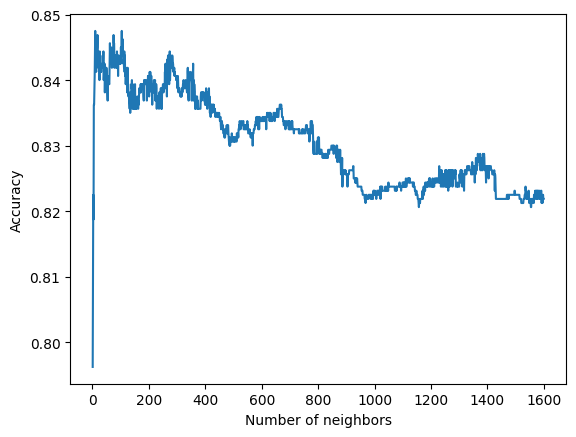

Test Accuracy for K-NN with best k: 10
Accuracy: 0.8415 
 Precision: 0.7927461139896373 
 Recall: 0.6996951219512195 
 F1-score: 0.7433198380566801 
 ROC-AUC: 0.8052047038327526
Accuracy: 0.8415
Redundant examples removed
Samples removed: 3251
K value with best accuracy: 10


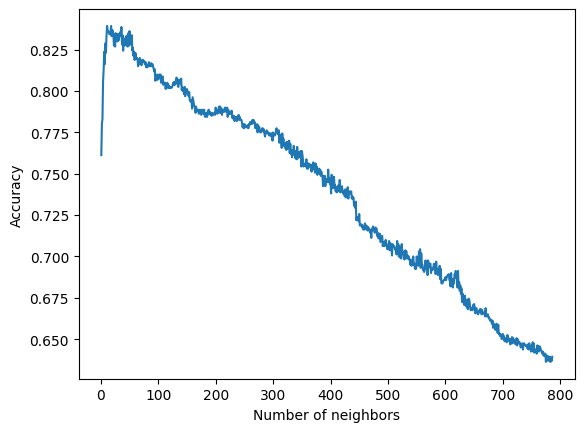

Test Accuracy for K-NN with best k: 10
Accuracy: 0.841 
 Precision: 0.7845117845117845 
 Recall: 0.7103658536585366 
 F1-score: 0.7456 
 ROC-AUC: 0.8075638792102207
Accuracy: 0.841


In [84]:
KNN_models(
    X_train=lr_train_set,
    y_train=y_train,
    X_val=lr_val_set,
    y_val=y_val,
    X_test=lr_test_set,
    y_test=y_test,
    weighted=False
)

K value with best accuracy: 17


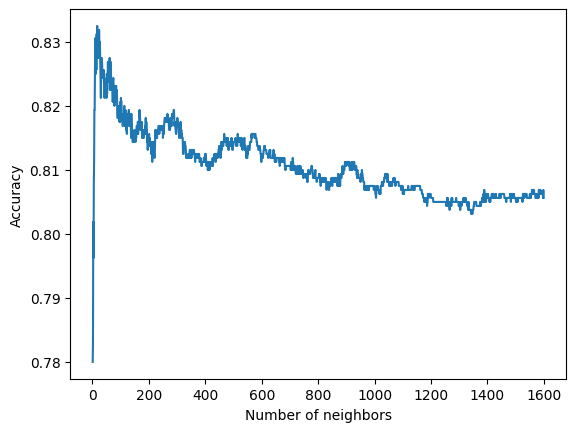

Test Accuracy for K-NN with best k: 17
Accuracy: 0.8395 
 Precision: 0.7873070325900514 
 Recall: 0.6996951219512195 
 F1-score: 0.7409200968523002 
 ROC-AUC: 0.8037166085946573
Accuracy: 0.8395
Redundant examples removed
Samples removed: 3234
K value with best accuracy: 17


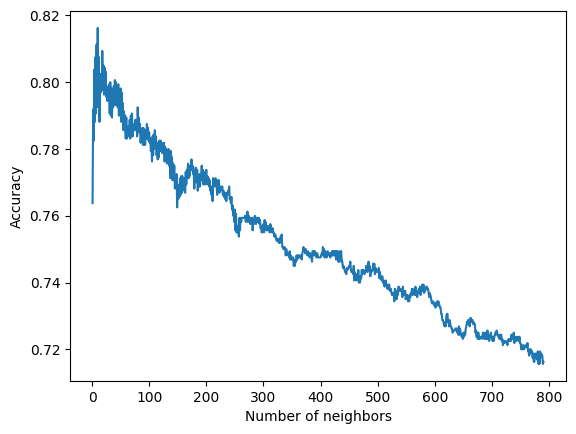

Test Accuracy for K-NN with best k: 17
Accuracy: 0.808 
 Precision: 0.6566820276497696 
 Recall: 0.8689024390243902 
 F1-score: 0.7480314960629921 
 ROC-AUC: 0.8235881242740999
Accuracy: 0.808


In [85]:
KNN_models(
    X_train=train_set,
    y_train=y_train,
    X_val=val_set,
    y_val=y_val,
    X_test=test_set,
    y_test=y_test,
    weighted=True
)

K value with best accuracy: 27


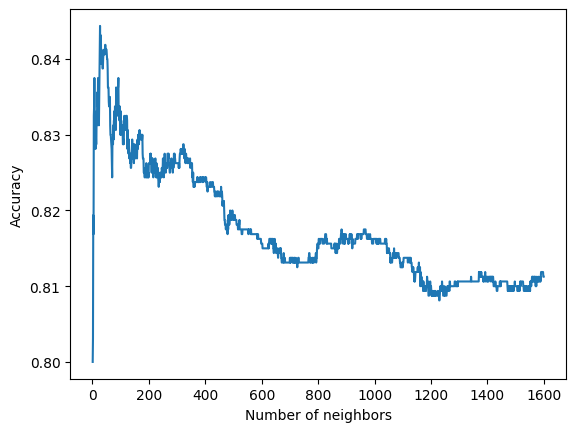

Test Accuracy for K-NN with best k: 27
Accuracy: 0.837 
 Precision: 0.7570093457943925 
 Recall: 0.7408536585365854 
 F1-score: 0.74884437596302 
 ROC-AUC: 0.8123911149825783
Accuracy: 0.837
Redundant examples removed
Samples removed: 3340
K value with best accuracy: 27


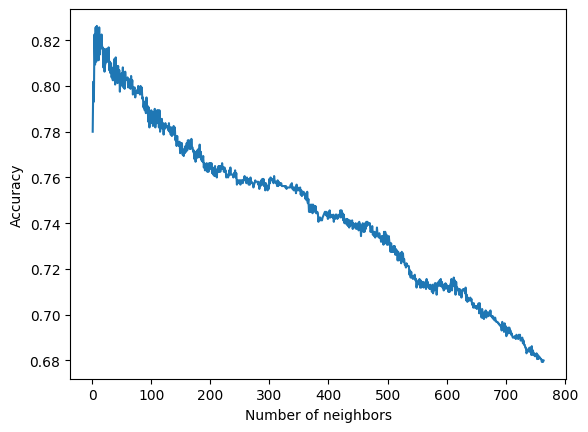

Test Accuracy for K-NN with best k: 27
Accuracy: 0.8115 
 Precision: 0.6654804270462633 
 Recall: 0.8551829268292683 
 F1-score: 0.7484989993328885 
 ROC-AUC: 0.8226807491289199
Accuracy: 0.8115


In [86]:
KNN_models(
    X_train=rf_train_set,
    y_train=rf_y_train,
    X_val=rf_val_set,
    y_val=rf_y_val,
    X_test=rf_test_set,
    y_test=y_test,
    weighted=True
)

K value with best accuracy: 10


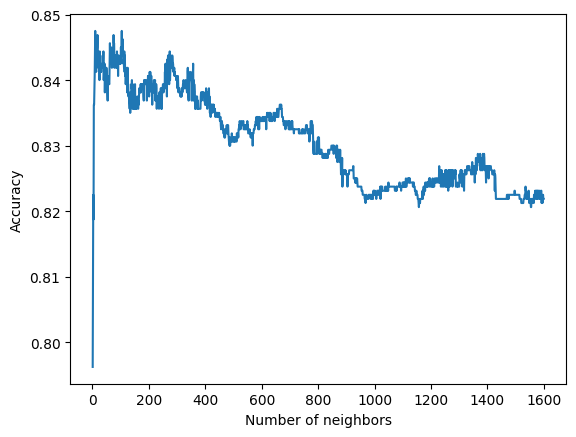

Test Accuracy for K-NN with best k: 10
Accuracy: 0.8415 
 Precision: 0.7927461139896373 
 Recall: 0.6996951219512195 
 F1-score: 0.7433198380566801 
 ROC-AUC: 0.8052047038327526
Accuracy: 0.8415
Redundant examples removed
Samples removed: 3251
K value with best accuracy: 10


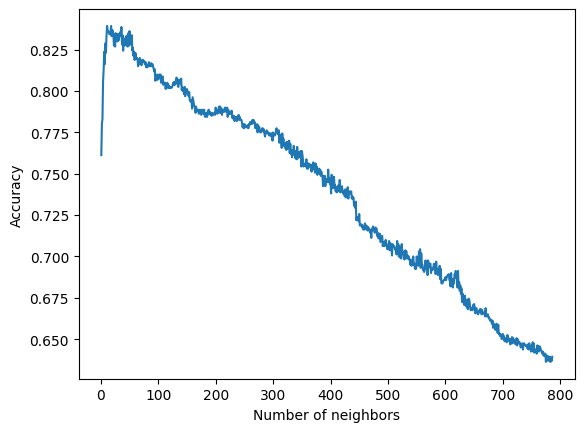

Test Accuracy for K-NN with best k: 10
Accuracy: 0.841 
 Precision: 0.7845117845117845 
 Recall: 0.7103658536585366 
 F1-score: 0.7456 
 ROC-AUC: 0.8075638792102207
Accuracy: 0.841


In [87]:
KNN_models(
    X_train=lr_train_set,
    y_train=y_train,
    X_val=lr_val_set,
    y_val=y_val,
    X_test=lr_test_set,
    y_test=y_test,
    weighted=True
)

### Neural Network

In [76]:
run_NeuralNet(
    X_train=train_set,
    y_train=y_train,
    X_test=test_set,
    y_test=y_test,
    epochs=20,
    optimizer="Adam",
    activation=nn.ReLU()
)

Epoch 1/20, Loss: 0.567509
Epoch 2/20, Loss: 0.490055
Epoch 3/20, Loss: 0.440135
Epoch 4/20, Loss: 0.412534
Epoch 5/20, Loss: 0.397048
Epoch 6/20, Loss: 0.387803
Epoch 7/20, Loss: 0.380902
Epoch 8/20, Loss: 0.375094
Epoch 9/20, Loss: 0.369763
Epoch 10/20, Loss: 0.364958
Epoch 11/20, Loss: 0.360702
Epoch 12/20, Loss: 0.356863
Epoch 13/20, Loss: 0.353468
Epoch 14/20, Loss: 0.350487
Epoch 15/20, Loss: 0.347892
Epoch 16/20, Loss: 0.345645
Epoch 17/20, Loss: 0.343693
Epoch 18/20, Loss: 0.342004
Epoch 19/20, Loss: 0.340509
Epoch 20/20, Loss: 0.339191
Accuracy: 0.822 
 Precision: 0.6676829268292683 
 Recall: 0.7604166666666666 
 F1-score: 0.711038961038961 
 ROC-AUC: 0.8036633895131086


In [77]:
run_NeuralNet(
    X_train=train_set,
    y_train=y_train,
    X_test=test_set,
    y_test=y_test,
    epochs=20,
    optimizer="Adam",
    activation=nn.Sigmoid()
)

Epoch 1/20, Loss: 0.548895
Epoch 2/20, Loss: 0.480743
Epoch 3/20, Loss: 0.445004
Epoch 4/20, Loss: 0.425309
Epoch 5/20, Loss: 0.414180
Epoch 6/20, Loss: 0.407922
Epoch 7/20, Loss: 0.404471
Epoch 8/20, Loss: 0.402505
Epoch 9/20, Loss: 0.401105
Epoch 10/20, Loss: 0.399634
Epoch 11/20, Loss: 0.397708
Epoch 12/20, Loss: 0.395173
Epoch 13/20, Loss: 0.392049
Epoch 14/20, Loss: 0.388467
Epoch 15/20, Loss: 0.384601
Epoch 16/20, Loss: 0.380618
Epoch 17/20, Loss: 0.376658
Epoch 18/20, Loss: 0.372822
Epoch 19/20, Loss: 0.369178
Epoch 20/20, Loss: 0.365762
Accuracy: 0.8015 
 Precision: 0.538109756097561 
 Recall: 0.7897091722595079 
 F1-score: 0.6400725294650952 
 ROC-AUC: 0.7973014631419882


In [78]:
run_NeuralNet(
    X_train=train_set,
    y_train=y_train,
    X_test=test_set,
    y_test=y_test,
    epochs=20,
    optimizer="SGD",
    activation=nn.ReLU()
)

Epoch 1/20, Loss: 0.690590
Epoch 2/20, Loss: 0.688136
Epoch 3/20, Loss: 0.685697
Epoch 4/20, Loss: 0.683272
Epoch 5/20, Loss: 0.680864
Epoch 6/20, Loss: 0.678473
Epoch 7/20, Loss: 0.676095
Epoch 8/20, Loss: 0.673730
Epoch 9/20, Loss: 0.671376
Epoch 10/20, Loss: 0.669033
Epoch 11/20, Loss: 0.666703
Epoch 12/20, Loss: 0.664384
Epoch 13/20, Loss: 0.662077
Epoch 14/20, Loss: 0.659779
Epoch 15/20, Loss: 0.657491
Epoch 16/20, Loss: 0.655210
Epoch 17/20, Loss: 0.652938
Epoch 18/20, Loss: 0.650674
Epoch 19/20, Loss: 0.648418
Epoch 20/20, Loss: 0.646168
Accuracy: 0.673 
 Precision: 0.003048780487804878 
 Recall: 1.0 
 F1-score: 0.0060790273556231 
 ROC-AUC: 0.8363363363363363


In [79]:
run_NeuralNet(
    X_train=train_set,
    y_train=y_train,
    X_test=test_set,
    y_test=y_test,
    epochs=20,
    optimizer="SGD",
    activation=nn.Sigmoid()
)

Epoch 1/20, Loss: 0.710251
Epoch 2/20, Loss: 0.699951
Epoch 3/20, Loss: 0.690001
Epoch 4/20, Loss: 0.680400
Epoch 5/20, Loss: 0.671149
Epoch 6/20, Loss: 0.662244
Epoch 7/20, Loss: 0.653678
Epoch 8/20, Loss: 0.645447
Epoch 9/20, Loss: 0.637541
Epoch 10/20, Loss: 0.629953
Epoch 11/20, Loss: 0.622672
Epoch 12/20, Loss: 0.615688
Epoch 13/20, Loss: 0.608991
Epoch 14/20, Loss: 0.602569
Epoch 15/20, Loss: 0.596411
Epoch 16/20, Loss: 0.590505
Epoch 17/20, Loss: 0.584841
Epoch 18/20, Loss: 0.579407
Epoch 19/20, Loss: 0.574194
Epoch 20/20, Loss: 0.569190
Accuracy: 0.672 
 Precision: 0.0 
 Recall: 0.0 
 F1-score: 0.0 
 ROC-AUC: nan


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


RF Set

In [82]:
run_NeuralNet(
    X_train=rf_train_set,
    y_train=y_train,
    X_test=rf_test_set,
    y_test=y_test,
    epochs=20,
    optimizer="Adam",
    activation=nn.ReLU()
)

run_NeuralNet(
    X_train=rf_train_set,
    y_train=y_train,
    X_test=rf_test_set,
    y_test=y_test,
    epochs=20,
    optimizer="Adam",
    activation=nn.Sigmoid()
)

run_NeuralNet(
    X_train=rf_train_set,
    y_train=y_train,
    X_test=rf_test_set,
    y_test=y_test,
    epochs=20,
    optimizer="SGD",
    activation=nn.ReLU()
)

run_NeuralNet(
    X_train=rf_train_set,
    y_train=y_train,
    X_test=rf_test_set,
    y_test=y_test,
    epochs=20,
    optimizer="SGD",
    activation=nn.Sigmoid()
)

Epoch 1/20, Loss: 0.595693
Epoch 2/20, Loss: 0.513179
Epoch 3/20, Loss: 0.451872
Epoch 4/20, Loss: 0.414056
Epoch 5/20, Loss: 0.391753
Epoch 6/20, Loss: 0.377517
Epoch 7/20, Loss: 0.367578
Epoch 8/20, Loss: 0.360140
Epoch 9/20, Loss: 0.354189
Epoch 10/20, Loss: 0.349284
Epoch 11/20, Loss: 0.345190
Epoch 12/20, Loss: 0.341767
Epoch 13/20, Loss: 0.338903
Epoch 14/20, Loss: 0.336492
Epoch 15/20, Loss: 0.334435
Epoch 16/20, Loss: 0.332702
Epoch 17/20, Loss: 0.331156
Epoch 18/20, Loss: 0.329813
Epoch 19/20, Loss: 0.328679
Epoch 20/20, Loss: 0.327684
Accuracy: 0.829 
 Precision: 0.6920731707317073 
 Recall: 0.7643097643097643 
 F1-score: 0.7264 
 ROC-AUC: 0.8103198892672577
Epoch 1/20, Loss: 0.522848
Epoch 2/20, Loss: 0.466350
Epoch 3/20, Loss: 0.434590
Epoch 4/20, Loss: 0.416027
Epoch 5/20, Loss: 0.404966
Epoch 6/20, Loss: 0.398422
Epoch 7/20, Loss: 0.394689
Epoch 8/20, Loss: 0.392697
Epoch 9/20, Loss: 0.391704
Epoch 10/20, Loss: 0.391167
Epoch 11/20, Loss: 0.390684
Epoch 12/20, Loss: 0.389

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


Epoch 1/20, Loss: 0.723194
Epoch 2/20, Loss: 0.712391
Epoch 3/20, Loss: 0.701946
Epoch 4/20, Loss: 0.691865
Epoch 5/20, Loss: 0.682149
Epoch 6/20, Loss: 0.672796
Epoch 7/20, Loss: 0.663804
Epoch 8/20, Loss: 0.655164
Epoch 9/20, Loss: 0.646869
Epoch 10/20, Loss: 0.638910
Epoch 11/20, Loss: 0.631276
Epoch 12/20, Loss: 0.623959
Epoch 13/20, Loss: 0.616945
Epoch 14/20, Loss: 0.610223
Epoch 15/20, Loss: 0.603784
Epoch 16/20, Loss: 0.597614
Epoch 17/20, Loss: 0.591702
Epoch 18/20, Loss: 0.586037
Epoch 19/20, Loss: 0.580606
Epoch 20/20, Loss: 0.575399
Accuracy: 0.672 
 Precision: 0.0 
 Recall: 0.0 
 F1-score: 0.0 
 ROC-AUC: nan


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


Stepwise Feature Set

In [83]:
run_NeuralNet(
    X_train=lr_train_set,
    y_train=y_train,
    X_test=lr_test_set,
    y_test=y_test,
    epochs=20,
    optimizer="Adam",
    activation=nn.ReLU()
)

run_NeuralNet(
    X_train=lr_train_set,
    y_train=y_train,
    X_test=lr_test_set,
    y_test=y_test,
    epochs=20,
    optimizer="Adam",
    activation=nn.Sigmoid()
)

run_NeuralNet(
    X_train=lr_train_set,
    y_train=y_train,
    X_test=lr_test_set,
    y_test=y_test,
    epochs=20,
    optimizer="SGD",
    activation=nn.ReLU()
)

run_NeuralNet(
    X_train=lr_train_set,
    y_train=y_train,
    X_test=lr_test_set,
    y_test=y_test,
    epochs=20,
    optimizer="SGD",
    activation=nn.Sigmoid()
)

Epoch 1/20, Loss: 0.638119
Epoch 2/20, Loss: 0.563425
Epoch 3/20, Loss: 0.501812
Epoch 4/20, Loss: 0.457888
Epoch 5/20, Loss: 0.429195
Epoch 6/20, Loss: 0.411058
Epoch 7/20, Loss: 0.399009
Epoch 8/20, Loss: 0.389859
Epoch 9/20, Loss: 0.382313
Epoch 10/20, Loss: 0.375669
Epoch 11/20, Loss: 0.369677
Epoch 12/20, Loss: 0.364271
Epoch 13/20, Loss: 0.359311
Epoch 14/20, Loss: 0.354783
Epoch 15/20, Loss: 0.350714
Epoch 16/20, Loss: 0.347055
Epoch 17/20, Loss: 0.343784
Epoch 18/20, Loss: 0.340892
Epoch 19/20, Loss: 0.338333
Epoch 20/20, Loss: 0.336071
Accuracy: 0.84 
 Precision: 0.7057926829268293 
 Recall: 0.7847457627118644 
 F1-score: 0.7431781701444623 
 ROC-AUC: 0.8239331650438754
Epoch 1/20, Loss: 0.551707
Epoch 2/20, Loss: 0.492202
Epoch 3/20, Loss: 0.457852
Epoch 4/20, Loss: 0.437003
Epoch 5/20, Loss: 0.424054
Epoch 6/20, Loss: 0.416068
Epoch 7/20, Loss: 0.411366
Epoch 8/20, Loss: 0.408927
Epoch 9/20, Loss: 0.408041
Epoch 10/20, Loss: 0.408181
Epoch 11/20, Loss: 0.408934
Epoch 12/20, 

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


Epoch 1/20, Loss: 0.675901
Epoch 2/20, Loss: 0.666190
Epoch 3/20, Loss: 0.656879
Epoch 4/20, Loss: 0.647959
Epoch 5/20, Loss: 0.639420
Epoch 6/20, Loss: 0.631250
Epoch 7/20, Loss: 0.623436
Epoch 8/20, Loss: 0.615964
Epoch 9/20, Loss: 0.608822
Epoch 10/20, Loss: 0.601994
Epoch 11/20, Loss: 0.595466
Epoch 12/20, Loss: 0.589225
Epoch 13/20, Loss: 0.583257
Epoch 14/20, Loss: 0.577549
Epoch 15/20, Loss: 0.572088
Epoch 16/20, Loss: 0.566862
Epoch 17/20, Loss: 0.561857
Epoch 18/20, Loss: 0.557064
Epoch 19/20, Loss: 0.552471
Epoch 20/20, Loss: 0.548068
Accuracy: 0.672 
 Precision: 0.0 
 Recall: 0.0 
 F1-score: 0.0 
 ROC-AUC: nan


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


### Logistic Regression

In [88]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Copies of the shared sets: bool columns become 0/1 and labels become integers
feature_sets = {
    "Random Forest": (rf_train_set.astype(float), rf_test_set.astype(float)),
    "Stepwise": (lr_train_set.astype(float), lr_test_set.astype(float)),
}
y_train_int = y_train.astype(int)
y_test_int = y_test.astype(int)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(


,feature_set,best_C,best_l1_ratio,baseline_cv_acc,tuned_cv_acc,tuned_train_acc,tuned_test_acc
0,Random Forest,3.1623,0.0,0.8494,0.8503,0.8513,0.8515
1,Stepwise,1.0000,0.0,0.8533,0.8533,0.8537,0.8515


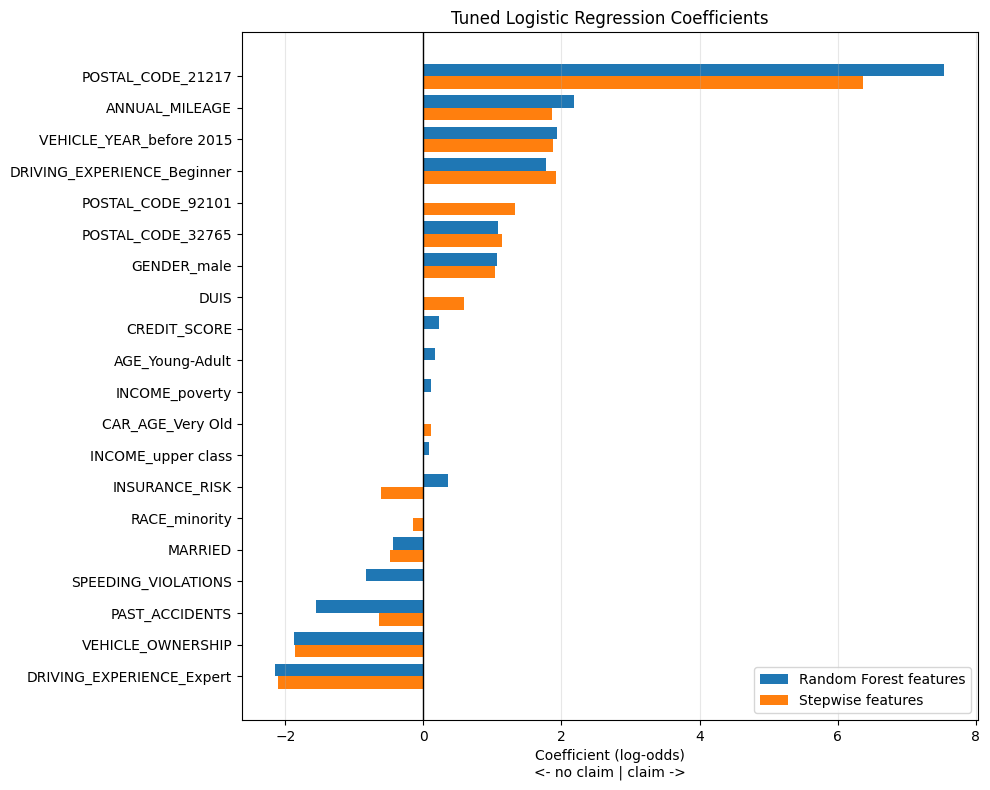

,Random Forest features,Stepwise features
Feature,,
POSTAL_CODE_21217,7.545,6.372
ANNUAL_MILEAGE,2.189,1.869
VEHICLE_YEAR_before 2015,1.938,1.877
DRIVING_EXPERIENCE_Beginner,1.783,1.925
POSTAL_CODE_32765,1.077,1.138
GENDER_male,1.069,1.033
INSURANCE_RISK,0.361,-0.614
CREDIT_SCORE,0.220,NaN
AGE_Young-Adult,0.166,NaN


,Random Forest features,Stepwise features
Feature,,
POSTAL_CODE_21217,1890.46,585.20
ANNUAL_MILEAGE,8.93,6.48
VEHICLE_YEAR_before 2015,6.95,6.54
DRIVING_EXPERIENCE_Beginner,5.95,6.85
POSTAL_CODE_32765,2.94,3.12
GENDER_male,2.91,2.81
INSURANCE_RISK,1.43,0.54
CREDIT_SCORE,1.25,NaN
AGE_Young-Adult,1.18,NaN


,accuracy,precision,recall,f1,roc_auc
model,,,,,
Always no claim,0.6720,0.000,0.0000,0.0000,0.5000
LR (Random Forest),0.8515,0.790,0.7454,0.7671,0.9213
LR (Stepwise),0.8515,0.789,0.7470,0.7674,0.9229


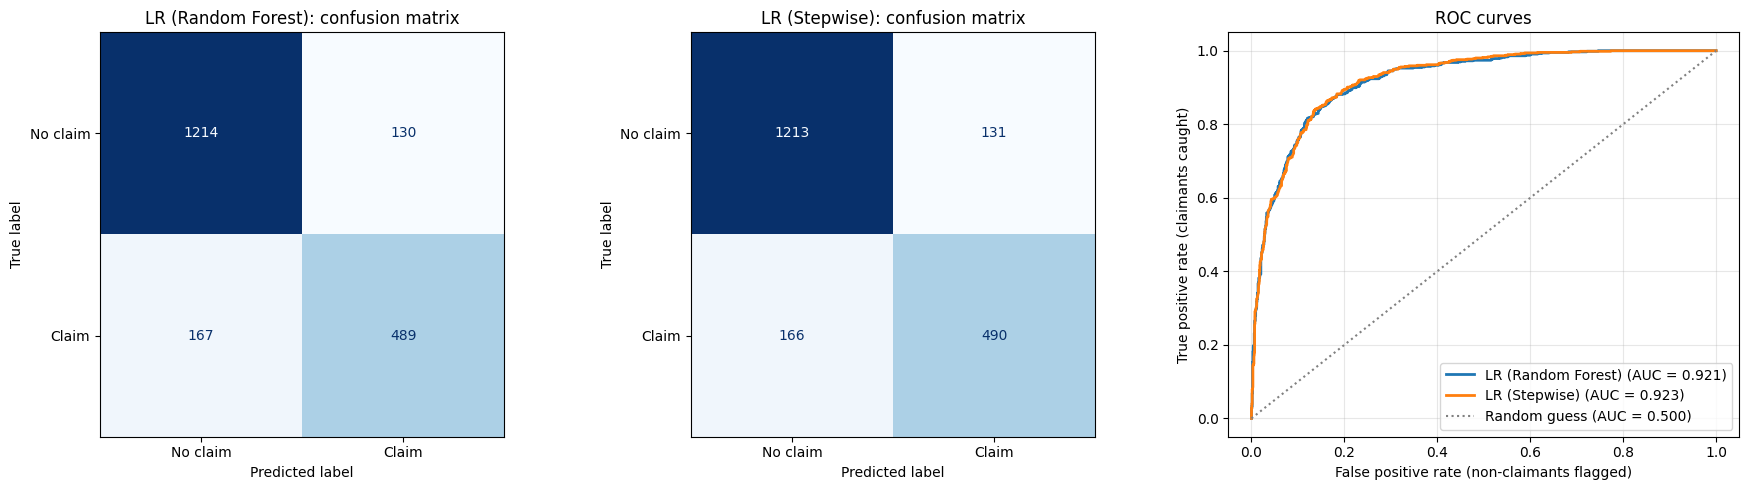

In [89]:
lr_tuned, lr_best_params, lr_results = run_logistic_regression(feature_sets, y_train_int, y_test_int, cv)
tuned_comparison, odds_ratios, lr_metrics = report_logistic_regression(
    lr_tuned, lr_results, feature_sets, y_train_int, y_test_int
)

### Xgboost

Random Forest best parameters:
  colsample_bytree: 0.7216
  gamma: 2.0851
  learning_rate: 0.1015
  max_depth: 5
  min_child_weight: 6
  n_estimators: 573
  reg_alpha: 0.0671
  reg_lambda: 0.0638
  subsample: 0.9348

Stepwise best parameters:
  colsample_bytree: 0.6369
  gamma: 3.0147
  learning_rate: 0.0345
  max_depth: 4
  min_child_weight: 5
  n_estimators: 145
  reg_alpha: 0.5101
  reg_lambda: 0.0443
  subsample: 0.7112



,feature_set,baseline_cv_acc,tuned_cv_acc,tuned_train_acc,tuned_test_acc
0,Random Forest,0.8506,0.8534,0.8645,0.8560
1,Stepwise,0.8522,0.8553,0.8568,0.8545


Always predicting 'no claim' scores 0.672 on the test set


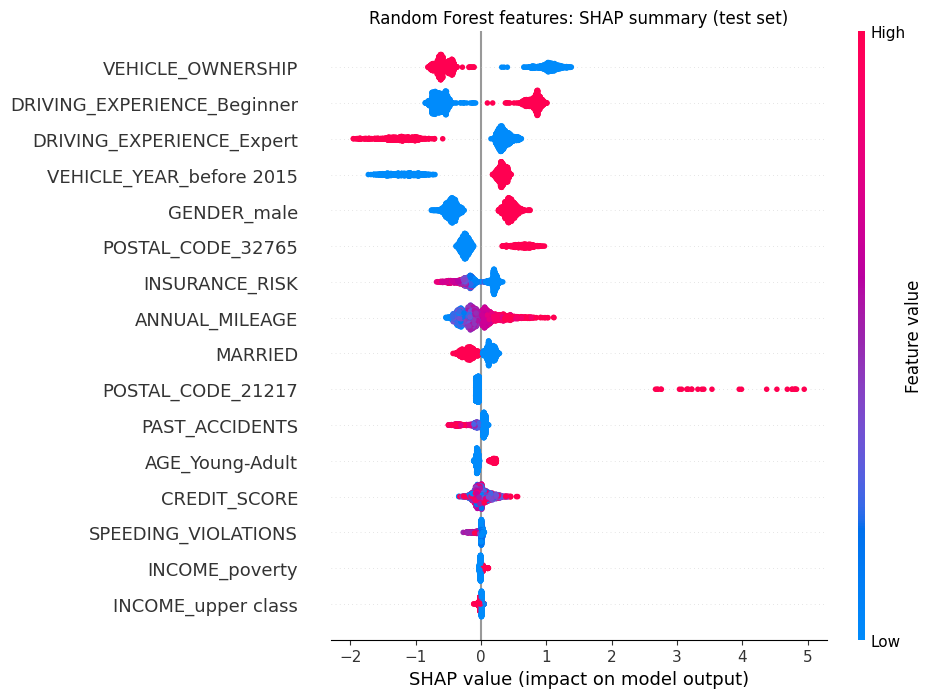

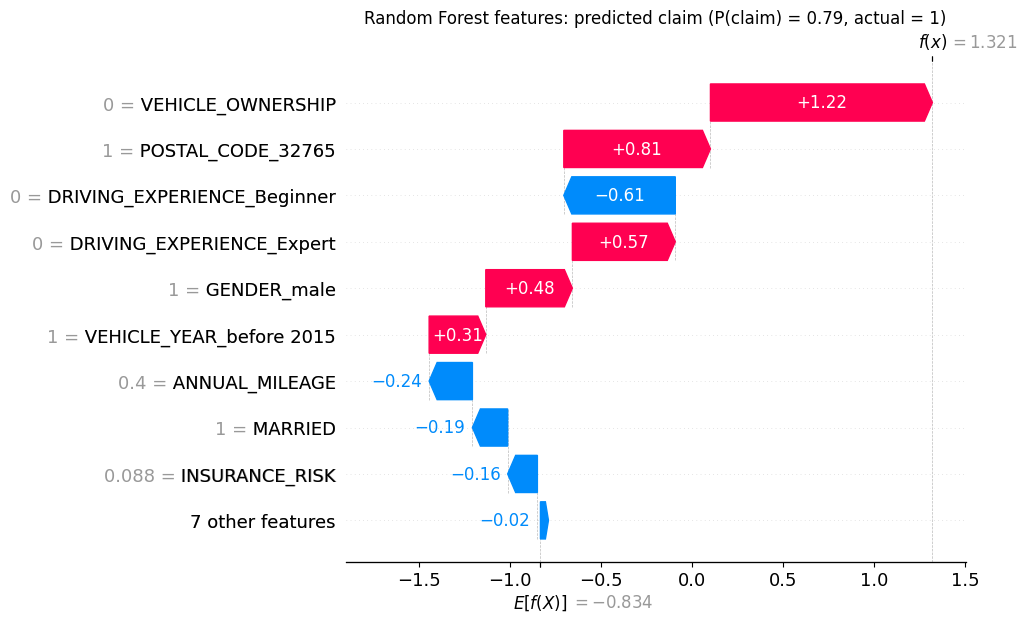

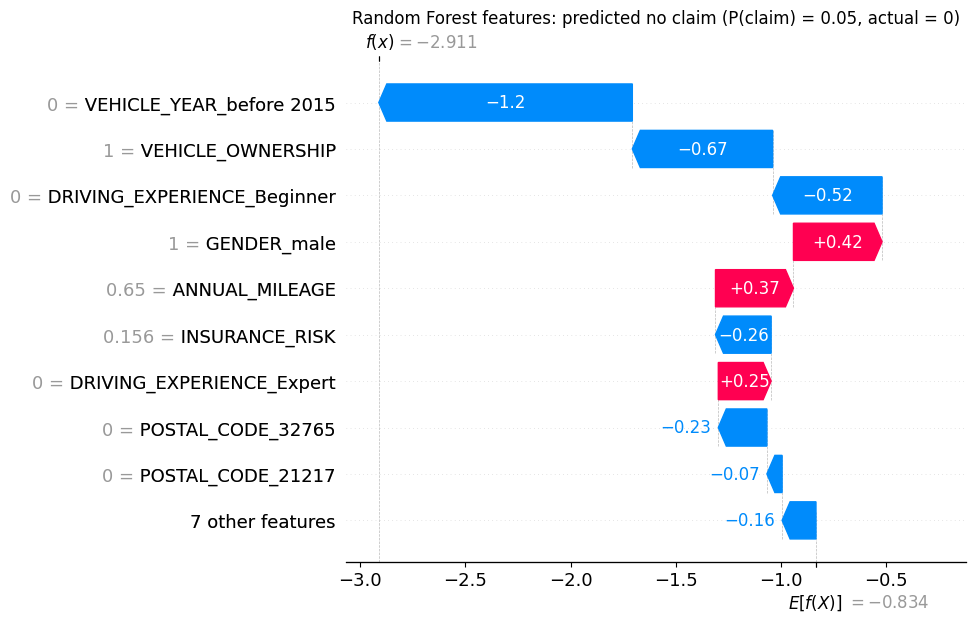

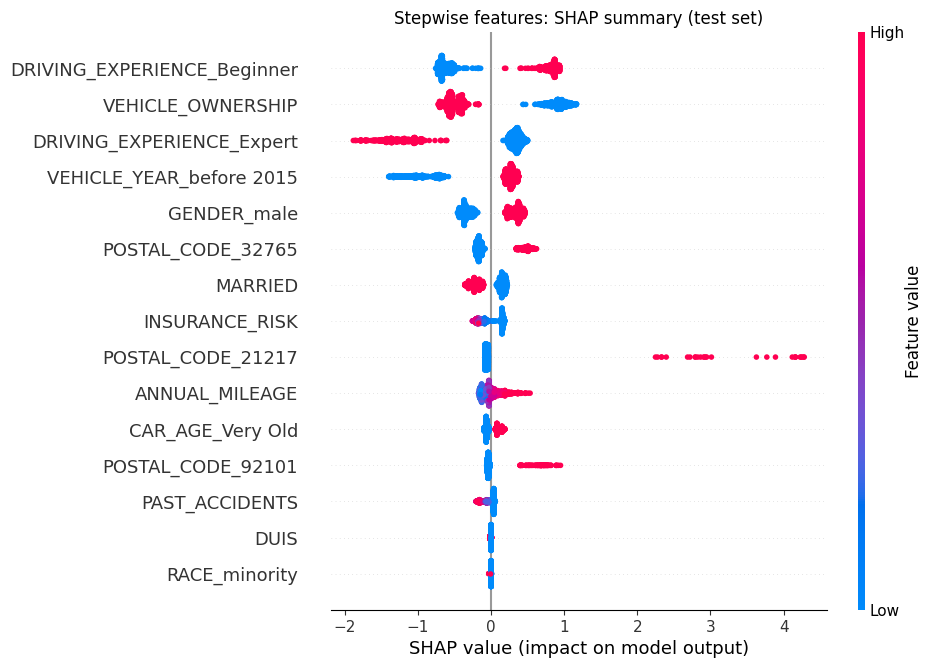

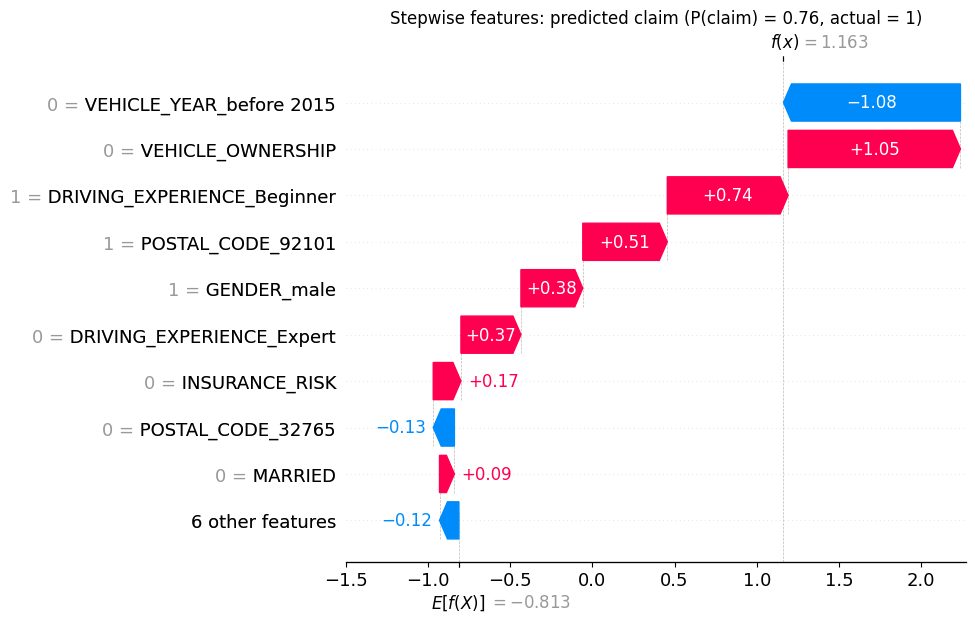

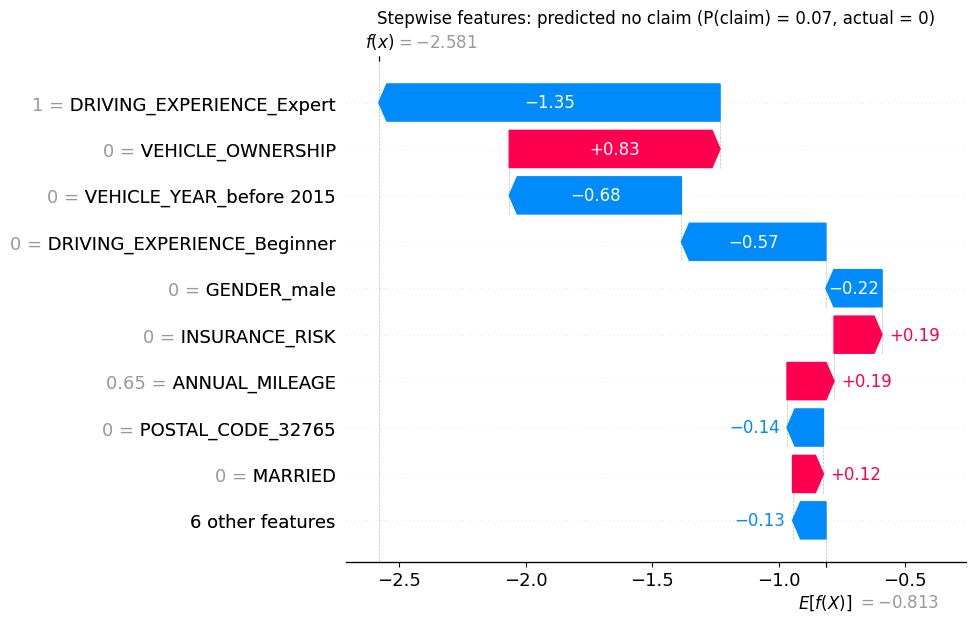

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Always no claim,0.6720,0.0000,0.0000,0.0000,0.5000
XGBoost (Random Forest),0.8560,0.7866,0.7698,0.7781,0.9212
XGBoost (Stepwise),0.8545,0.7829,0.7698,0.7763,0.9227


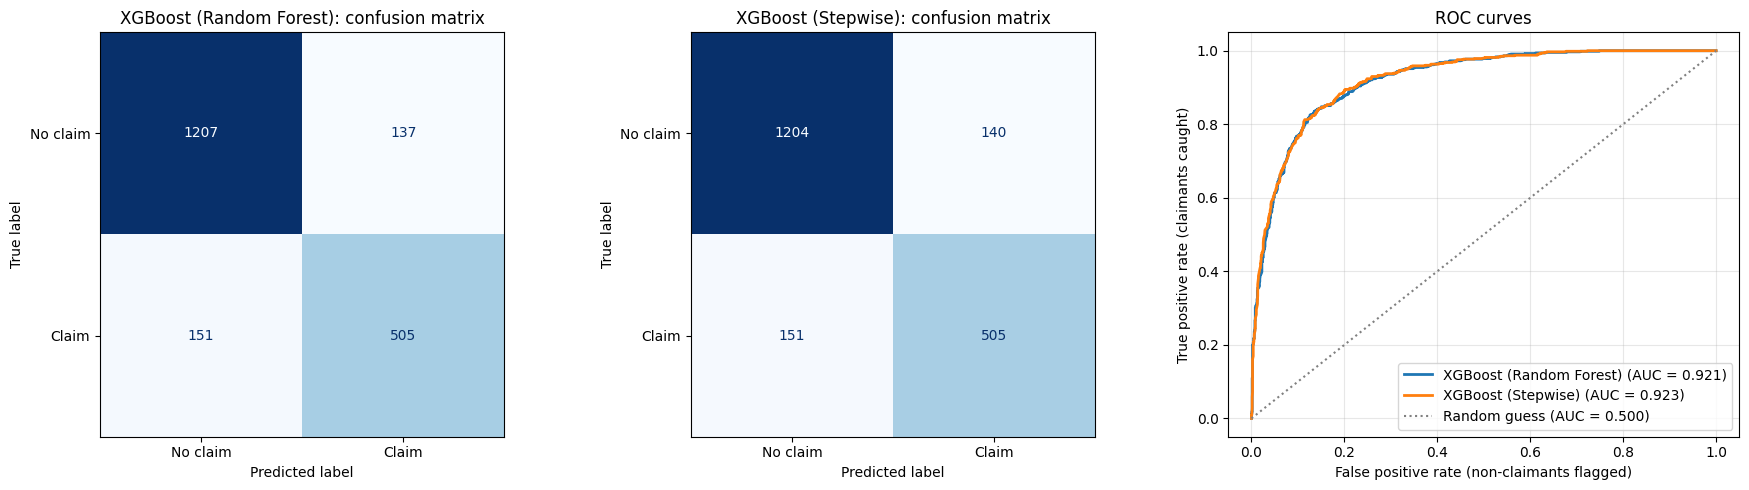

In [90]:
xgb_tuned, xgb_best_params, xgb_results = run_xgboost(feature_sets, y_train_int, y_test_int, cv)
xgb_metrics = report_xgboost(xgb_tuned, xgb_best_params, xgb_results, feature_sets, y_train_int, y_test_int)